In [3]:
print('h')

h


In [4]:
%pip install -q evaluate contractions sentence-transformers scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [5]:
# Safeguard Kaggle persistent working directory
# WARNING: Do NOT automatically run `!rm -rf /kaggle/working/*` when Kaggle persistence is enabled!
# Doing so permanently deletes all cached checkpoints, trained models, and history logs.
CLEAN_WORKING_DIR = False  # Set to True ONLY if you explicitly want to completely wipe all cached models.

if CLEAN_WORKING_DIR:
    !rm -rf /kaggle/working/*
    print("[Working Dir] /kaggle/working/* has been wiped as requested.")
else:
    print("[Working Dir] Kaggle persistent working directory preserved. Existing checkpoints and models will be reused/resumed.")

[Working Dir] Kaggle persistent working directory preserved. Existing checkpoints and models will be reused/resumed.


# Dataset Loading and Train-Test-Validation Splitting

## Loading

In [6]:
import os
from pathlib import Path
from datasets import load_dataset, load_from_disk, Dataset, DatasetDict

# Priority list of dataset locations:
# 1. Attached Kaggle dataset folder specified by user: /kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset
# 2. Alternative Kaggle mount layouts
# 3. Local repository fallback paths
candidate_aug_paths = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
]

aug_file_path = None
for candidate in candidate_aug_paths:
    if candidate.exists():
        aug_file_path = str(candidate)
        print(f"[Dataset] Successfully located dataset at: {aug_file_path}")
        break

if aug_file_path is None:
    # Default explicitly to the Kaggle attached dataset directory
    aug_file_path = "/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"
    print(f"[Dataset] Path candidate not found locally. Using default Kaggle path: {aug_file_path}")

augmented_dataset = load_from_disk(aug_file_path)

# Keep a compatibility variable for downstream exploratory cells
dataset = augmented_dataset["train"]

print("Augmented Dataset splits:", augmented_dataset)
print("Working Dataset (train split length):", len(dataset))

[Dataset] Successfully located dataset at: /kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset
Augmented Dataset splits: DatasetDict({
    train: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F', 'augmentation_method', 'augmentation_source'],
        num_rows: 4279
    })
    test: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 333
    })
    validation: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 333
    })
})
Working Dataset (train split length): 4279


## Solving Contractions

In [7]:
import pandas as pd
import numpy as np
import re
import contractions  # Make sure to install: pip install contractions

class TextNormalizer:
    def __init__(self):
        # Initialize text normalization dictionary
        self.slang_dict = {
            'imo': 'in my opinion',
            'imho': 'in my humble opinion',
            'tbh': 'to be honest',
            'afaik': 'as far as i know',
            'idk': "i don't know",
            'smh': 'shaking my head',
            'btw': 'by the way',
            'asap': 'as soon as possible',
            'fyi': 'for your information',
            'np': 'no problem',
            'thx': 'thanks',
            'pls': 'please',
            'u': 'you',
            'r': 'are',
            'ur': 'your',
            'n': 'and',
            'b/c': 'because',
            'cz' : 'because',
            'bcz' : 'because',
            'ofc' : 'ofcourse',
            'govt': 'government',
            'dept': 'department',
            'est': 'established',
            'approx': 'approximately',
            'min': 'minimum',
            'max': 'maximum',
            "n't": 'not',
            "nt" : 'not',
            "gn" : 'good night',
            "f9" : 'fine',
            'bpd': 'borderline personality disorder',
            'dbt': 'dialectical behavior therapy',
            'fp': 'favorite person',
            'si': 'suicidal ideation',
            'sh': 'self harm',
            "its" : 'it is',
            "people's" : 'people',
            "sha'n't": "shall not",
            "shan't've": "shall not have",
            "she'd": "she had / she would",
            "she'd've": "she would have",
            "she'll": "she shall / she will",
            "she'll've": "she shall have / she will have",
            "she's": "she has / she is",
            "should've": "should have",
            "shouldn't": "should not",
            "shouldn't've": "should not have",
            "so've": "so have",
            "so's": "so as / so is",
            "that'd": "that would / that had",
            "that'd've": "that would have",
            "that's": "that has / that is",
            "there'd": "there had / there would",
            "there'd've": "there would have",
            "there's": "there has / there is",
            "they'd": "they had / they would",
            "they'd've": "they would have",
            "they'll": "they shall / they will",
            "they'll've": "they shall have / they will have",
            "they're": "they are",
            "they've": "they have",
            "to've": "to have",
            "wasn't": "was not",
            "we'd": "we had / we would",
            "we'd've": "we would have",
            "we'll": "we will",
            "we'll've": "we will have",
            "we're": "we are",
            "we've": "we have",
            "weren't": "were not",
            "what'll": "what shall / what will",
            "what'll've": "what shall have / what will have",
            "what're": "what are",
            "what's": "what has / what is",
            "what've": "what have",
            "when's": "when has / when is",
            "when've": "when have",
            "where'd": "where did",
            "where's": "where has / where is",
            "where've": "where have",
            "who'll": "who shall / who will",
            "who'll've": "who shall have / who will have",
            "who's": "who has / who is",
            "who've": "who have",
            "why's": "why has / why is",
            "why've": "why have",
            "will've": "will have",
            "won't": "will not",
            "won't've": "will not have",
            "would've": "would have",
            "wouldn't": "would not",
            "wouldn't've": "would not have",
            "y'all": "you all",
            "y'all'd": "you all would",
            "y'all'd've": "you all would have",
            "y'all're": "you all are",
            "y'all've": "you all have",
            "you'd": "you had / you would",
            "you'd've": "you would have",
            "you'll": "you shall / you will",
            "you'll've": "you shall have / you will have",
            "you're": "you are",
            "you've": "you have"
}

    def clean_text(self, text):
        """Basic text cleaning"""
        text = str(text).lower().strip()
        # Remove special characters (keep basic punctuation)
        text = re.sub(r"[^a-zA-Z0-9\s.,!?']", "", text)
        return text

    def expand_slang(self, text):
        """Replace slang terms using dictionary"""
        words = text.split()
        expanded_words = [self.slang_dict.get(word, word) for word in words]
        return ' '.join(expanded_words)

    def normalize_text(self, text):
        """Full text normalization pipeline"""
        if not isinstance(text, str) or not text.strip():
            return text
            
        # Clean text first
        text = self.clean_text(text)
        # Fix contractions
        text = contractions.fix(text)
        # Expand slang
        text = self.expand_slang(text)
        return text

# Convert to pandas DataFrame for easier processing
df = dataset.to_pandas()
aug_df_train = augmented_dataset['train'].to_pandas()
aug_df_test = augmented_dataset['test'].to_pandas()
aug_df_validation = augmented_dataset['validation'].to_pandas()

# Initialize normalizer
normalizer = TextNormalizer()

# Apply normalization to text columns
text_columns = ['question', 'answer']
for col in text_columns:
    df[col] = df[col].apply(normalizer.normalize_text)
    aug_df_train[col] = aug_df_train[col].apply(normalizer.normalize_text)
    aug_df_test[col] = aug_df_test[col].apply(normalizer.normalize_text)
    aug_df_validation[col] = aug_df_validation[col].apply(normalizer.normalize_text)
    
clean_dataset = Dataset.from_pandas(df, preserve_index=False)

aug_clean_dataset_train = Dataset.from_pandas(aug_df_train, preserve_index=False)
aug_clean_dataset_test = Dataset.from_pandas(aug_df_test, preserve_index=False)
aug_clean_dataset_validation =  Dataset.from_pandas(aug_df_validation, preserve_index=False)
aug_clean_dataset = DatasetDict({
    "train":aug_clean_dataset_train,
    "test":aug_clean_dataset_test,
    "validation":aug_clean_dataset_validation
})
dataset = clean_dataset
augmented_dataset = aug_clean_dataset

## Question-Wise Stratified Splitting

In [8]:
# Baseline question-wise stratified split is disabled for augmented-only workflow.
# from collections import Counter
# from datasets import concatenate_datasets, DatasetDict
# qid_split_ds = {}
# ds = dataset.class_encode_column("label")
# for qid in range(1, 10):
#     split_ds = ds.filter(lambda row, q=qid: row["question_id"] == q)
#     qid_split_ds[qid] = split_ds
# question_split_dataset = {}
# train_splits = dataset.select([])
# test_splits = dataset.select([])
# validation_splits = dataset.select([])
# for i in range(1,10):
#     split1 = qid_split_ds[i].train_test_split(test_size=0.1 , seed=42, stratify_by_column="label")
#     split2 = split1["train"].train_test_split(test_size=0.1111 , seed=42, stratify_by_column="label")
#     train_splits = concatenate_datasets([split2['train'] , train_splits])
#     test_splits = concatenate_datasets([split2['test'] , test_splits])
#     validation_splits = concatenate_datasets([split1['test'] , validation_splits])
# question_split_dataset = DatasetDict({
#     'train' : train_splits,
#     'test' : test_splits,
#     'validation' : validation_splits
# })
# print(f"\nTrain set: {question_split_dataset['train'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['train']['label'])}")
# print(f"\nTest set: {question_split_dataset['test'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['test']['label'])}")
# print(f"\nValidation set: {question_split_dataset['validation'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['validation']['label'])}")
# print("\n",Counter(question_split_dataset['train']['question_id']))

# For augmented-only workflow, use augmented split directly.
question_split_dataset = augmented_dataset
print("Baseline split disabled. Using augmented dataset splits directly.")

Baseline split disabled. Using augmented dataset splits directly.


## Data Visualization

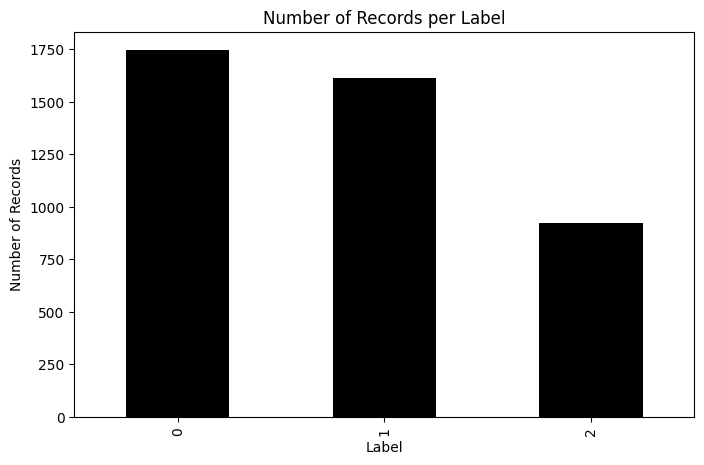

In [9]:
import matplotlib.pyplot as plt

df = dataset.to_pandas()

# Use pandas value_counts to count the labels
label_counts = df['label'].value_counts().sort_index()

label_counts.plot(kind='bar', figsize=(8, 5), color='black')
plt.xlabel('Label')
plt.ylabel('Number of Records')
plt.title('Number of Records per Label')
plt.show()

## Class Weights for Weighted Cross-Entropy Loss
###  Weight of Class i = sqrt (Total Number of Examples)/(Number of Classes x Examples in Class i)

In [10]:
# Weighted Cross-Entropy class weights are disabled per experiment scope.
# from sklearn.utils.class_weight import compute_class_weight
# import numpy as np
# import torch
# classes=np.unique(question_split_dataset['train']['label'])
# class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(question_split_dataset['train']['label']), y=question_split_dataset['train']['label'])
# class_weights = torch.tensor(class_weights)
# class_weights = torch.sqrt(class_weights)
# class_weights = class_weights / class_weights.sum() * len(class_weights)
# class_weights = class_weights.to(device='cuda', dtype=torch.float32)
# print (f"Class Weights: {class_weights}")
print("Skipped: class-weight computation disabled (no weighted-loss runs).")

Skipped: class-weight computation disabled (no weighted-loss runs).


## Checking for Null Values

In [11]:
df = dataset.to_pandas()

# 2. Identify rows with at least one null
mask = df.isnull().any(axis=1)

# 3. Extract and print those rows
null_df = df[mask]
print(null_df)

        id  participant_id  question_id  \
0     3077             181            9   
1     3039             143            9   
2     3007             111            9   
3     3106             210            9   
4     3052             156            9   
...    ...             ...          ...   
2587    60              60            1   
2588    28              28            1   
2589   344             344            1   
2590   109             109            1   
2591   112             112            1   

                                               question  \
0     can you describe experiences where you felt in...   
1     can you describe experiences where you felt in...   
2     can you describe experiences where you felt in...   
3     can you describe experiences where you felt in...   
4     can you describe experiences where you felt in...   
...                                                 ...   
2587  can you describe situations where you felt a s...   
2588  can y

# Tokenization

## Tokenization Function

In [12]:
# tokenizer also passed to ensure used tokenizer is of same checkpoint as the model
# Dynamic Padding. Hence, dp
def tokenize(example , tokenizer):
    return tokenizer(example["question"], example["answer"], truncation=True)

## Tokenization

In [13]:
from transformers import AutoTokenizer

### Electra

In [14]:
electra_checkpoint = 'google/electra-base-discriminator'
electra_tokenizer = AutoTokenizer.from_pretrained(electra_checkpoint)
# tokenized_dataset_dp_electra = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : electra_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_electra = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : electra_tokenizer})

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### BERT

In [15]:
bert_checkpoint = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_checkpoint)
# tokenized_dataset_dp_bert = question_split_dataset.map(tokenize , batched = True , fn_kwargs = {'tokenizer' : bert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_bert = augmented_dataset.map(tokenize , batched = True , fn_kwargs = {'tokenizer' : bert_tokenizer})

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

###  DistilBERT

In [16]:
distilbert_checkpoint = "distilbert/distilbert-base-uncased"
distilbert_tokenizer = AutoTokenizer.from_pretrained(distilbert_checkpoint)
# tokenized_dataset_dp_distilbert = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : distilbert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_distilbert = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : distilbert_tokenizer})

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### RoBERTa

In [17]:
roberta_checkpoint = "FacebookAI/roberta-base"
roberta_tokenizer = AutoTokenizer.from_pretrained(roberta_checkpoint)
# tokenized_dataset_dp_roberta = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : roberta_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_roberta = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : roberta_tokenizer})

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### PsychBERT

In [18]:
# PsychBERT tokenization is disabled entirely per experiment scope.
# psychbert_checkpoint = "mnaylor/psychbert-cased"
# psychbert_tokenizer = AutoTokenizer.from_pretrained(psychbert_checkpoint)
# tokenized_dataset_dp_psychbert = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : psychbert_tokenizer})
# augmented_tokenized_dataset_dp_psychbert = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : psychbert_tokenizer})
print("Skipped: PsychBERT section disabled.")

Skipped: PsychBERT section disabled.


### XLNet

In [19]:
xlnet_checkpoint = "xlnet/xlnet-base-cased"
xlnet_tokenizer = AutoTokenizer.from_pretrained(xlnet_checkpoint)
# tokenized_dataset_dp_xlnet = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : xlnet_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_xlnet = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : xlnet_tokenizer})

config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### DeBERTa

In [20]:
deberta_checkpoint = "microsoft/deberta-v3-base"
deberta_tokenizer = AutoTokenizer.from_pretrained(deberta_checkpoint, use_fast=False)
# tokenized_dataset_dp_deberta = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : deberta_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_deberta = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : deberta_tokenizer})


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### ModernBERT


In [21]:
modernbert_checkpoint = "answerdotai/ModernBERT-base"
try:
    modernbert_tokenizer = AutoTokenizer.from_pretrained(modernbert_checkpoint)
except Exception as ex:
    raise RuntimeError(
        "ModernBERT could not be loaded in this environment. If your Transformers build is too old, upgrade it before running this cell."
    ) from ex
# tokenized_dataset_dp_modernbert = question_split_dataset.map(tokenize, batched=True, fn_kwargs={'tokenizer': modernbert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_modernbert = augmented_dataset.map(tokenize, batched=True, fn_kwargs={'tokenizer': modernbert_tokenizer})


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### T5

In [22]:
t5_checkpoint = "google-t5/t5-small"

from transformers import T5Tokenizer
t5_tokenizer = T5Tokenizer.from_pretrained(t5_checkpoint)

def t5_preprocess(example):
    inputs = [
        f"trinary classification: {question} </s> {answer}"
        for question, answer in zip(example["question"], example["answer"])
    ]
    model_inputs = t5_tokenizer(
        inputs,
        max_length=512,
        truncation=True,
    )
    return model_inputs

# tokenized_dataset_dp_t5 = question_split_dataset.map(t5_preprocess, batched=True)  # Raw baseline disabled
augmented_tokenized_dataset_dp_t5 = augmented_dataset.map(t5_preprocess, batched=True)

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4279 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

# Evaluate Function

In [23]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(evaluation_predictions):
    logits, actual_labels = evaluation_predictions
    predicted_labels = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

def compute_test_metrics(evaluation_predictions):
    predicted_labels, actual_labels = evaluation_predictions

    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# Training

In [24]:
import gc
import json
import inspect
from contextlib import contextmanager, nullcontext
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    T5ForSequenceClassification,
    T5Tokenizer,
    Trainer,
    TrainingArguments,
)

if Path("/kaggle/working").exists():
    MODEL_ARTIFACT_ROOT = Path("/kaggle/working/model_artifacts")
else:
    MODEL_ARTIFACT_ROOT = Path("./model_artifacts")
MODEL_ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_RUNTIME_SPECS = {
    "ELECTRA": {
        "trainer_name": "electra_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_electra",
        "tokenizer_name": "electra_tokenizer",
        "artifact_dir": "electra_augmented",
        "model_loader": "auto",
    },
    "BERT": {
        "trainer_name": "bert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_bert",
        "tokenizer_name": "bert_tokenizer",
        "artifact_dir": "bert_augmented",
        "model_loader": "auto",
    },
    "DistilBERT": {
        "trainer_name": "distilbert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_distilbert",
        "tokenizer_name": "distilbert_tokenizer",
        "artifact_dir": "distilbert_augmented",
        "model_loader": "auto",
    },
    "RoBERTa": {
        "trainer_name": "roberta_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_roberta",
        "tokenizer_name": "roberta_tokenizer",
        "artifact_dir": "roberta_augmented",
        "model_loader": "auto",
    },
    "XLNet": {
        "trainer_name": "xlnet_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_xlnet",
        "tokenizer_name": "xlnet_tokenizer",
        "artifact_dir": "xlnet_augmented",
        "model_loader": "auto",
    },
    "DeBERTa": {
        "trainer_name": "deberta_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_deberta",
        "tokenizer_name": "deberta_tokenizer",
        "artifact_dir": "deberta_augmented",
        "model_loader": "auto",
    },
    "ModernBERT": {
        "trainer_name": "modernbert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_modernbert",
        "tokenizer_name": "modernbert_tokenizer",
        "artifact_dir": "modernbert_augmented",
        "model_loader": "auto",
    },
    "T5": {
        "trainer_name": "t5_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_t5",
        "tokenizer_name": "t5_tokenizer",
        "artifact_dir": "t5_augmented",
        "model_loader": "t5",
    },
}

def get_model_artifact_dir(model_name):
    model_dir = MODEL_ARTIFACT_ROOT / MODEL_RUNTIME_SPECS[model_name]["artifact_dir"]
    model_dir.mkdir(parents=True, exist_ok=True)
    return model_dir

def _extract_pred_labels(pred_output):
    preds = pred_output.predictions
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.asarray(preds)
    if preds.ndim == 1:
        return preds.astype(int)
    return np.argmax(preds, axis=-1)

def _resolve_saved_model_dir(model_name):
    artifact_dir = get_model_artifact_dir(model_name)
    if (artifact_dir / "config.json").exists():
        return artifact_dir

    checkpoint_dirs = sorted(
        [path for path in artifact_dir.glob("checkpoint-*") if path.is_dir()],
        key=lambda path: int(path.name.split("-")[-1]),
    )
    if checkpoint_dirs:
        return checkpoint_dirs[-1]
    return None

def _load_saved_components(model_name):
    spec = MODEL_RUNTIME_SPECS[model_name]
    saved_model_dir = _resolve_saved_model_dir(model_name)
    if saved_model_dir is None:
        raise FileNotFoundError(
            f"No saved checkpoint found for {model_name} in {get_model_artifact_dir(model_name)}"
        )

    if spec["model_loader"] == "t5":
        tokenizer = globals().get(spec["tokenizer_name"]) or T5Tokenizer.from_pretrained(saved_model_dir)
        model = T5ForSequenceClassification.from_pretrained(saved_model_dir)
    else:
        tokenizer = globals().get(spec["tokenizer_name"])
        if tokenizer is None:
            tokenizer = AutoTokenizer.from_pretrained(
                saved_model_dir,
                use_fast=(model_name != "DeBERTa"),
            )
        model = AutoModelForSequenceClassification.from_pretrained(saved_model_dir)
        if model_name == "XLNet":
            tokenizer.padding_side = "left"
            model.config.pad_token_id = tokenizer.pad_token_id

    return model, tokenizer, saved_model_dir

@contextmanager
def force_single_gpu_visibility(enabled=False):
    if (not enabled) or (not torch.cuda.is_available()):
        yield
        return

    original_device_count = torch.cuda.device_count
    torch.cuda.device_count = lambda: 1
    try:
        yield
    finally:
        torch.cuda.device_count = original_device_count

def _mixed_precision_training_kwargs():
    if not torch.cuda.is_available():
        return {"fp16": False, "bf16": False}
    # Native hardware bf16 requires Ampere (SM 8.0+) or newer (e.g. A100, RTX 3000+, H100)
    # On Turing (Tesla T4, SM 7.5), Pascal (P100), Volta (V100), use native fp16 to avoid software emulation overhead and warnings
    major_capability = torch.cuda.get_device_capability()[0]
    if major_capability >= 8 and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        return {"fp16": False, "bf16": True}
    return {"fp16": True, "bf16": False}

TRAINING_PRECISION_KWARGS = _mixed_precision_training_kwargs()
_ORIGINAL_TORCH_CUDA_DEVICE_COUNT = torch.cuda.device_count

def configure_trainer_runtime_for_notebook(precision_kwargs=None):
    precision_kwargs = precision_kwargs or TRAINING_PRECISION_KWARGS
    enable_single_gpu = (
        torch.cuda.is_available()
        and _ORIGINAL_TORCH_CUDA_DEVICE_COUNT() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )
    torch.cuda.device_count = (
        (lambda: 1) if enable_single_gpu else _ORIGINAL_TORCH_CUDA_DEVICE_COUNT
    )
    return enable_single_gpu

SINGLE_GPU_TRAINER_RUNTIME = configure_trainer_runtime_for_notebook()

def training_precision_mode_label(precision_kwargs=None):
    precision_kwargs = precision_kwargs or TRAINING_PRECISION_KWARGS
    if precision_kwargs.get("bf16"):
        return "bf16"
    if precision_kwargs.get("fp16"):
        return "fp16"
    return "fp32"

if SINGLE_GPU_TRAINER_RUNTIME:
    print(
        f"Notebook trainer stability mode enabled: using {training_precision_mode_label()} on a single visible GPU."
    )

def _trainer_tokenizer_arg_name():
    trainer_signature = inspect.signature(Trainer.__init__)
    if "processing_class" in trainer_signature.parameters:
        return "processing_class"
    if "tokenizer" in trainer_signature.parameters:
        return "tokenizer"
    return None

def predict_augmented_model(model_name):
    spec = MODEL_RUNTIME_SPECS[model_name]
    if spec["token_ds_name"] not in globals():
        raise KeyError(
            f"{spec['token_ds_name']} is not available. Run the tokenization cell for {model_name} first."
        )

    tokenized_ds = globals()[spec["token_ds_name"]]
    trainer_name = spec["trainer_name"]

    if trainer_name in globals():
        pred_output = globals()[trainer_name].predict(tokenized_ds["test"])
        source = "in-memory trainer"
        if SINGLE_GPU_TRAINER_RUNTIME:
            source += " (single-GPU stability mode)"
        return _extract_pred_labels(pred_output), source

    prediction_context = force_single_gpu_visibility(SINGLE_GPU_TRAINER_RUNTIME)
    with prediction_context:
        model, tokenizer, saved_model_dir = _load_saved_components(model_name)
        data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
        eval_args = TrainingArguments(
            output_dir=str(get_model_artifact_dir(model_name) / "_eval_runtime"),
            per_device_eval_batch_size=2 if model_name == "XLNet" else 8,
            report_to=[],
        )
        eval_trainer_kwargs = {
            "model": model,
            "args": eval_args,
            "data_collator": data_collator,
        }
        trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
        if trainer_tokenizer_arg is not None:
            eval_trainer_kwargs[trainer_tokenizer_arg] = tokenizer
        eval_trainer = Trainer(**eval_trainer_kwargs)

        try:
            pred_output = eval_trainer.predict(tokenized_ds["test"])
        finally:
            del eval_trainer
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    return _extract_pred_labels(pred_output), f"saved artifact: {saved_model_dir}"

def evaluate_augmented_model(model_name):
    actual_labels = np.array(augmented_dataset["test"]["label"])
    pred_labels, source = predict_augmented_model(model_name)
    metrics = compute_test_metrics((pred_labels, actual_labels))
    return pred_labels, actual_labels, metrics, source

def get_model_history_path(model_name):
    return get_model_artifact_dir(model_name) / "training_history.csv"

def save_training_history(model_name, trainer_obj):
    history_df = pd.DataFrame(trainer_obj.state.log_history)
    history_path = get_model_history_path(model_name)
    history_df.to_csv(history_path, index=False)
    return history_df

import shutil
import zipfile

def get_disk_usage_info():
    target = "/kaggle/working" if Path("/kaggle/working").exists() else "."
    total, used, free = shutil.disk_usage(target)
    return total, used, free

def print_disk_usage(prefix=""):
    total, used, free = get_disk_usage_info()
    tag = f"[{prefix}] " if prefix else ""
    print(f"{tag}[Disk Info] Total: {total / (1024**3):.2f} GB | Used: {used / (1024**3):.2f} GB | Free: {free / (1024**3):.2f} GB")

def cleanup_intermediate_checkpoints(output_directory):
    """
    Removes intermediate checkpoint-* folders to reclaim disk space once final model is saved.
    This prevents Kaggle's 20 GB disk quota from being exhausted by multi-gigabyte optimizer.pt files.
    """
    out_path = Path(output_directory)
    freed_bytes = 0
    for ckpt in out_path.glob("checkpoint-*"):
        if ckpt.is_dir():
            for f in ckpt.rglob("*"):
                if f.is_file():
                    try:
                        freed_bytes += f.stat().st_size
                    except Exception:
                        pass
            shutil.rmtree(ckpt, ignore_errors=True)
            print(f"[Disk Cleanup] Removed intermediate checkpoint: {ckpt.name}")
    if freed_bytes > 0:
        print(f"[Disk Cleanup] Reclaimed {freed_bytes / (1024**3):.2f} GB disk space in {out_path.name}.")

def cleanup_all_completed_checkpoints():
    """
    Scans all models. If a model's final weights are already saved, purges its intermediate
    checkpoint-* folders to reclaim up to 15+ GB of disk space on Kaggle.
    """
    print("[Disk Maintenance] Checking for completed model checkpoints to reclaim space...")
    for m_name in MODEL_RUNTIME_SPECS:
        if is_model_already_trained(m_name):
            m_dir = get_model_artifact_dir(m_name)
            ckpts = list(m_dir.glob("checkpoint-*"))
            if ckpts:
                print(f"[{m_name}] Final weights exist. Purging {len(ckpts)} obsolete intermediate checkpoints...")
                cleanup_intermediate_checkpoints(m_dir)
    print_disk_usage("After Maintenance")

def _clean_corrupted_checkpoints(output_directory):
    """Detects and deletes broken/truncated checkpoints resulting from disk-full crashes."""
    out_path = Path(output_directory)
    for ckpt in sorted(out_path.glob("checkpoint-*")):
        if not ckpt.is_dir():
            continue
        is_corrupted = False
        ts = ckpt / "trainer_state.json"
        if not ts.exists() or ts.stat().st_size == 0:
            is_corrupted = True
        for pt_file in ckpt.glob("*.pt"):
            if pt_file.stat().st_size == 0:
                is_corrupted = True
            else:
                try:
                    with zipfile.ZipFile(pt_file, "r") as z:
                        if z.testzip() is not None:
                            is_corrupted = True
                except Exception:
                    is_corrupted = True
        if is_corrupted:
            print(f"[Disk Maintenance] Deleting corrupted/incomplete checkpoint from previous crash: {ckpt.name}")
            shutil.rmtree(ckpt, ignore_errors=True)

def persist_model_training_artifacts(model_name, trainer_obj, tokenizer_obj, output_directory):
    history_df = save_training_history(model_name, trainer_obj)
    trainer_obj.save_model(output_directory)
    tokenizer_obj.save_pretrained(output_directory)
    # Immediately purge intermediate checkpoint-* folders to prevent Kaggle disk exhaustion
    cleanup_intermediate_checkpoints(output_directory)
    print_disk_usage(f"{model_name} Finalized")
    return history_df

def _checkpoint_dirs(model_name):
    artifact_dir = get_model_artifact_dir(model_name)
    return sorted(
        [path for path in artifact_dir.glob("checkpoint-*") if path.is_dir()],
        key=lambda path: int(path.name.split("-")[-1]),
    )

def load_training_history(model_name):
    history_path = get_model_history_path(model_name)
    if history_path.exists():
        return pd.read_csv(history_path)

    candidate_paths = [ckpt / "trainer_state.json" for ckpt in reversed(_checkpoint_dirs(model_name))]
    candidate_paths.append(get_model_artifact_dir(model_name) / "trainer_state.json")

    for state_path in candidate_paths:
        if not state_path.exists():
            continue
        with state_path.open("r", encoding="utf-8") as handle:
            trainer_state = json.load(handle)
        history_df = pd.DataFrame(trainer_state.get("log_history", []))
        if not history_df.empty:
            history_df.to_csv(history_path, index=False)
            return history_df

    raise FileNotFoundError(
        f"No training history found for {model_name}. Re-run training to generate paper-ready curves."
    )

def prepare_history_curves(model_name):
    history_df = load_training_history(model_name).copy()
    if history_df.empty:
        raise ValueError(f"Training history for {model_name} is empty.")

    if "epoch" not in history_df.columns:
        raise ValueError(f"Training history for {model_name} has no epoch column.")

    history_df = history_df.sort_values(by=[col for col in ["epoch", "step"] if col in history_df.columns])

    train_curve = history_df[history_df.get("loss").notna()].copy() if "loss" in history_df.columns else pd.DataFrame()
    eval_metric_cols = [
        col for col in ["eval_loss", "eval_accuracy", "eval_f1", "eval_precision", "eval_recall"]
        if col in history_df.columns
    ]
    eval_curve = pd.DataFrame()
    if eval_metric_cols:
        eval_curve = history_df[history_df[eval_metric_cols].notna().any(axis=1)].copy()

    if not train_curve.empty:
        train_curve = train_curve.drop_duplicates(subset=["epoch"], keep="last")
    if not eval_curve.empty:
        eval_curve = eval_curve.drop_duplicates(subset=["epoch"], keep="last")

    return train_curve, eval_curve

from transformers.trainer_utils import get_last_checkpoint

def is_model_already_trained(model_name):
    """Checks if final model artifacts (config, weights, training history) are already saved."""
    artifact_dir = get_model_artifact_dir(model_name)
    has_config = (artifact_dir / "config.json").exists()
    has_weights = (
        (artifact_dir / "model.safetensors").exists()
        or (artifact_dir / "pytorch_model.bin").exists()
        or len(_checkpoint_dirs(model_name)) > 0
    )
    has_history = get_model_history_path(model_name).exists()
    return has_config and has_weights and has_history

def train_with_checkpoint_resumption(
    trainer_obj,
    model_name,
    tokenizer_obj,
    output_directory,
    force_retrain=False,
):
    """
    Executes training with automatic persistence checkpoint recovery and disk space management:
    1. Purges obsolete checkpoints from other completed models to guarantee 15+ GB free disk space.
    2. If model is already fully trained and saved, skips redundant retraining and loads cached history.
    3. Cleans any corrupted/truncated checkpoints from prior disk-full crashes.
    4. If training was interrupted, detects the latest valid checkpoint and resumes seamlessly.
    5. Automatically persists final weights and removes temporary checkpoints upon completion.
    """
    out_path = Path(output_directory)
    out_path.mkdir(parents=True, exist_ok=True)

    # 1. Clean up checkpoints from already-completed models to ensure ample disk space
    cleanup_all_completed_checkpoints()

    if not force_retrain and is_model_already_trained(model_name):
        print(f"[{model_name}] Complete trained artifact and history already exist in {out_path}.")
        print(f"[{model_name}] Skipping re-training. Loading existing model state.")
        cleanup_intermediate_checkpoints(out_path)
        try:
            return load_training_history(model_name)
        except Exception:
            return None

    # 2. Clean up any corrupted checkpoint caused by prior disk-full crashes
    _clean_corrupted_checkpoints(out_path)
    print_disk_usage(f"Before {model_name} Training")

    last_checkpoint = get_last_checkpoint(str(out_path))
    if last_checkpoint is not None and not force_retrain:
        print(f"[{model_name}] Found existing checkpoint: {last_checkpoint}")
        print(f"[{model_name}] Resuming training from checkpoint...")
        try:
            train_result = trainer_obj.train(resume_from_checkpoint=last_checkpoint)
        except Exception as ex:
            print(f"[Warning] Resumption from {last_checkpoint} failed ({ex}). Deleting invalid checkpoint and restarting fresh...")
            shutil.rmtree(last_checkpoint, ignore_errors=True)
            train_result = trainer_obj.train()
    else:
        print(f"[{model_name}] Starting fresh training (no checkpoint found or force_retrain=True)...")
        train_result = trainer_obj.train()

    print(f"[{model_name}] Saving final model weights, tokenizer, and training history...")
    persist_model_training_artifacts(model_name, trainer_obj, tokenizer_obj, str(out_path))
    print(f"[{model_name}] Artifacts successfully persisted to {out_path}.")
    return train_result


Notebook trainer stability mode enabled: using fp16 on a single visible GPU.


# ELECTRA

## ELECTRA (Raw)

In [25]:
# ELECTRA (Raw) disabled for augmented-only workflow.
print("Skipped: ELECTRA raw baseline training disabled.")

Skipped: ELECTRA raw baseline training disabled.


## ELECTRA (Class-Weighted Cross Entropy Loss)

In [26]:
# ELECTRA (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: ELECTRA weighted-loss training disabled.")

Skipped: ELECTRA weighted-loss training disabled.


## ELECTRA (Text Augmentation)

In [27]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("ELECTRA"))

model = AutoModelForSequenceClassification.from_pretrained(electra_checkpoint, num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=electra_tokenizer)

training_args = TrainingArguments(
    output_dir=output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate=0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type="linear",
    eval_strategy='epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to=[]
)

electra_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset=augmented_tokenized_dataset_dp_electra['train'],
    eval_dataset=augmented_tokenized_dataset_dp_electra['validation'],
    data_collator=data_collator,
    processing_class=electra_tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("\nELECTRA (Text Augmentation) Training / Checkpoint Resumption:")
train_result = train_with_checkpoint_resumption(
    electra_aug_trainer,
    "ELECTRA",
    electra_tokenizer,
    output_directory,
    force_retrain=globals().get("FORCE_RETRAIN", False),
)
train_result

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: google/electra-base-discriminator
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings_project.bias                   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
electra.embeddings_project.weight                 | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- 


ELECTRA (Text Augmentation) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[ELECTRA] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/electra_augmented.
[ELECTRA] Skipping re-training. Loading existing model state.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.079919,2.376461,0.000002,1.0,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,268,1.000211,0.639640,0.582361,0.538669,0.639640,3.2003,104.052,6.562,NaN,NaN,NaN,NaN,NaN
2,0.994890,5.420232,0.000003,2.0,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,536,0.844518,0.672673,0.650584,0.691374,0.672673,3.1406,106.032,6.687,NaN,NaN,NaN,NaN,NaN
4,0.754821,9.762331,0.000005,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,804,0.588380,0.780781,0.781288,0.787588,0.780781,3.1518,105.655,6.663,NaN,NaN,NaN,NaN,NaN
6,0.519526,9.980052,0.000005,4.0,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1072,0.660562,0.741742,0.752751,0.804203,0.741742,3.1548,105.554,6.657,NaN,NaN,NaN,NaN,NaN
8,0.376475,15.192475,0.000004,5.0,1340,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1340,0.520033,0.816817,0.818502,0.824035,0.816817,3.1316,106.335,6.706,NaN,NaN,NaN,NaN,NaN


# BERT

## BERT (Raw)

In [28]:
# BERT (Raw) disabled for augmented-only workflow.
print("Skipped: BERT raw baseline training disabled.")

Skipped: BERT raw baseline training disabled.


## BERT (Weighted Cross Entropy Loss)

In [29]:
# BERT (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: BERT weighted-loss training disabled.")

Skipped: BERT weighted-loss training disabled.


## BERT (Text Augmentation)

In [30]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("BERT"))

model = AutoModelForSequenceClassification.from_pretrained(bert_checkpoint, num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

training_args = TrainingArguments(
    output_dir=output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate=0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type="linear",
    eval_strategy='epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to=[]
)

bert_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset=augmented_tokenized_dataset_dp_bert['train'],
    eval_dataset=augmented_tokenized_dataset_dp_bert['validation'],
    data_collator=data_collator,
    processing_class=bert_tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print("\nBERT (Text Augmentation) Training / Checkpoint Resumption:")
train_result = train_with_checkpoint_resumption(
    bert_aug_trainer,
    "BERT",
    bert_tokenizer,
    output_directory,
    force_retrain=globals().get("FORCE_RETRAIN", False),
)
train_result

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will b


BERT (Text Augmentation) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[BERT] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/bert_augmented.
[BERT] Skipping re-training. Loading existing model state.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.098352,6.609152,0.000002,1.0,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,268,1.045937,0.459459,0.458645,0.587271,0.459459,2.9844,111.581,7.037,NaN,NaN,NaN,NaN,NaN
2,0.944571,12.119008,0.000003,2.0,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,536,0.869903,0.588589,0.572871,0.738341,0.588589,2.9894,111.394,7.025,NaN,NaN,NaN,NaN,NaN
4,0.757446,9.943704,0.000005,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,804,0.625503,0.750751,0.752218,0.772783,0.750751,2.9915,111.314,7.020,NaN,NaN,NaN,NaN,NaN
6,0.520284,8.180331,0.000005,4.0,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1072,0.635198,0.738739,0.748721,0.787026,0.738739,2.9750,111.934,7.059,NaN,NaN,NaN,NaN,NaN
8,0.362381,12.612045,0.000004,5.0,1340,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1340,0.617174,0.771772,0.778886,0.806981,0.771772,2.9757,111.908,7.057,NaN,NaN,NaN,NaN,NaN


# DistilBERT

## DistilBERT (Raw)

In [31]:
# DistilBERT (Raw) disabled for augmented-only workflow.
print("Skipped: DistilBERT raw baseline training disabled.")

Skipped: DistilBERT raw baseline training disabled.


## DistilBERT (Weighted Cross Entropy Loss)

In [32]:
# DistilBERT (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: DistilBERT weighted-loss training disabled.")

Skipped: DistilBERT weighted-loss training disabled.


## DistilBERT (Text Augmentation)

In [33]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("DistilBERT"))

model = AutoModelForSequenceClassification.from_pretrained(distilbert_checkpoint, num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=distilbert_tokenizer)

training_args = TrainingArguments(
    output_dir=output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate=0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type="linear",
    eval_strategy='epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to=[]
)

distilbert_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset=augmented_tokenized_dataset_dp_distilbert['train'],
    eval_dataset=augmented_tokenized_dataset_dp_distilbert['validation'],
    data_collator=data_collator,
    processing_class=distilbert_tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("\nDistilBERT (Text Augmentation) Training / Checkpoint Resumption:")
train_result = train_with_checkpoint_resumption(
    distilbert_aug_trainer,
    "DistilBERT",
    distilbert_tokenizer,
    output_directory,
    force_retrain=globals().get("FORCE_RETRAIN", False),
)
train_result

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



DistilBERT (Text Augmentation) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[DistilBERT] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/distilbert_augmented.
[DistilBERT] Skipping re-training. Loading existing model state.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.082153,3.052912,0.000002,1.0,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,268,0.988481,0.645646,0.608723,0.577190,0.645646,1.5168,219.543,13.845,NaN,NaN,NaN,NaN,NaN
2,0.946344,5.793295,0.000003,2.0,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,536,0.795573,0.645646,0.658641,0.741181,0.645646,1.5102,220.497,13.905,NaN,NaN,NaN,NaN,NaN
4,0.707728,13.447253,0.000005,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,804,0.571774,0.780781,0.787974,0.800030,0.780781,1.5159,219.667,13.853,NaN,NaN,NaN,NaN,NaN
6,0.545395,10.801643,0.000005,4.0,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1072,0.694573,0.726727,0.741112,0.804996,0.726727,1.5190,219.219,13.825,NaN,NaN,NaN,NaN,NaN
8,0.412834,10.072443,0.000004,5.0,1340,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1340,0.566821,0.774775,0.785732,0.816314,0.774775,1.5178,219.401,13.836,NaN,NaN,NaN,NaN,NaN


# RoBERTa

## RoBERTa (Raw)

In [34]:
# RoBERTa (Raw) disabled for augmented-only workflow.
print("Skipped: RoBERTa raw baseline training disabled.")

Skipped: RoBERTa raw baseline training disabled.


## RoBERTA (Weighted Cross Entropy Loss)

In [35]:
# RoBERTa (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: RoBERTa weighted-loss training disabled.")

Skipped: RoBERTa weighted-loss training disabled.


## RoBERTa (Text Augmentation)

In [36]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("RoBERTa"))

model = AutoModelForSequenceClassification.from_pretrained(roberta_checkpoint, num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=roberta_tokenizer)

training_args = TrainingArguments(
    output_dir=output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate=0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type="linear",
    eval_strategy='epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to=[]
)

roberta_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset=augmented_tokenized_dataset_dp_roberta['train'],
    eval_dataset=augmented_tokenized_dataset_dp_roberta['validation'],
    data_collator=data_collator,
    processing_class=roberta_tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print("\nRoBERTa (Text Augmentation) Training / Checkpoint Resumption:")
train_result = train_with_checkpoint_resumption(
    roberta_aug_trainer,
    "RoBERTa",
    roberta_tokenizer,
    output_directory,
    force_retrain=globals().get("FORCE_RETRAIN", False),
)
train_result

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



RoBERTa (Text Augmentation) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[RoBERTa] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/roberta_augmented.
[RoBERTa] Skipping re-training. Loading existing model state.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.101553,4.895560,0.000002,1.0,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,268,1.044681,0.204204,0.069256,0.041699,0.204204,2.8767,115.757,7.300,NaN,NaN,NaN,NaN,NaN
2,0.956026,75.762581,0.000003,2.0,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,536,0.644150,0.720721,0.728370,0.767940,0.720721,2.8592,116.467,7.345,NaN,NaN,NaN,NaN,NaN
4,0.606032,29.885315,0.000005,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,804,0.529174,0.795796,0.800839,0.816004,0.795796,2.8705,116.008,7.316,NaN,NaN,NaN,NaN,NaN
6,0.452682,30.233435,0.000005,4.0,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1072,0.682812,0.759760,0.770789,0.813148,0.759760,2.8723,115.935,7.311,NaN,NaN,NaN,NaN,NaN
8,0.331273,51.253464,0.000004,5.0,1340,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1340,0.587296,0.810811,0.815047,0.824983,0.810811,2.8663,116.178,7.327,NaN,NaN,NaN,NaN,NaN


# PsychBERT

## PsychBERT (Raw)

In [37]:
# PsychBERT (Raw) disabled entirely per scope.
print("Skipped: PsychBERT raw training disabled.")

Skipped: PsychBERT raw training disabled.


## PsychBERT (Weighted Cross Entropy Loss)

In [38]:
# PsychBERT (Weighted Cross Entropy Loss) disabled entirely per scope.
print("Skipped: PsychBERT weighted training disabled.")

Skipped: PsychBERT weighted training disabled.


## PsychBERT (Text Augmentation)

In [39]:
# PsychBERT (Text Augmentation) disabled entirely per scope.
print("Skipped: PsychBERT augmentation training disabled.")

Skipped: PsychBERT augmentation training disabled.


# XLNet

## XLNet (Raw)

In [40]:
# XLNet (Raw) disabled for augmented-only workflow.
print("Skipped: XLNet raw baseline training disabled.")

Skipped: XLNet raw baseline training disabled.


## XLNet (Weighted Cross Entropy Loss)

In [41]:
# XLNet (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: XLNet weighted-loss training disabled.")

Skipped: XLNet weighted-loss training disabled.


In [42]:
import torch
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## XLNet (Text Augmentation)

In [43]:
import gc
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

# Free memory from previously trained models
for var_name in [
    "electra_aug_trainer", "bert_aug_trainer", "distilbert_aug_trainer", "roberta_aug_trainer", "model", "xlnet_aug_trainer"
]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("XLNet"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(xlnet_checkpoint, num_labels=3)

    # Fix XLNet padding requirement (Prevents immediate crash on forward pass)
    xlnet_tokenizer.padding_side = "left"
    model.config.pad_token_id = xlnet_tokenizer.pad_token_id

    data_collator = DataCollatorWithPadding(tokenizer=xlnet_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=4,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=4,
        num_train_epochs=15,
        learning_rate=0.000005,
        weight_decay=0.1,
        warmup_ratio=0.2,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy="epoch",
        logging_strategy="epoch",
        eval_accumulation_steps=8,
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        **precision_kwargs,
        report_to=[]
    )

    xlnet_aug_trainer = Trainer(
        model,
        training_args,
        train_dataset=augmented_tokenized_dataset_dp_xlnet['train'],
        eval_dataset=augmented_tokenized_dataset_dp_xlnet['validation'],
        data_collator=data_collator,
        processing_class=xlnet_tokenizer,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    print("\nXLNet (Text Augmentation) Training / Checkpoint Resumption:")
    train_result = train_with_checkpoint_resumption(
        xlnet_aug_trainer,
        "XLNet",
        xlnet_tokenizer,
        output_directory,
        force_retrain=globals().get("FORCE_RETRAIN", False),
    )
train_result

pytorch_model.bin:   0%|          | 0.00/467M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/467M [00:00<?, ?B/s]

XLNetForSequenceClassification LOAD REPORT from: xlnet/xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.bias                    | UNEXPECTED | 
lm_loss.weight                  | UNEXPECTED | 
logits_proj.weight              | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 
logits_proj.bias                | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



XLNet (Text Augmentation) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[XLNet] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/xlnet_augmented.
[XLNet] Skipping re-training. Loading existing model state.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,4.192281,58.118530,0.000002,1.0,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,268,0.911567,0.552553,0.559394,0.610578,0.552553,4.2190,78.928,39.582,NaN,NaN,NaN,NaN,NaN
2,3.571222,64.784546,0.000003,2.0,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,536,0.819855,0.582583,0.599186,0.761395,0.582583,4.1875,79.522,39.880,NaN,NaN,NaN,NaN,NaN
4,2.705961,88.345062,0.000005,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,804,0.545118,0.774775,0.777658,0.813743,0.774775,4.2179,78.949,39.593,NaN,NaN,NaN,NaN,NaN
6,2.070360,46.161308,0.000005,4.0,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1072,0.668056,0.750751,0.762552,0.819047,0.750751,4.1148,80.926,40.585,NaN,NaN,NaN,NaN,NaN
8,1.539338,47.687149,0.000004,5.0,1340,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1340,0.592571,0.783784,0.789775,0.819086,0.783784,4.1602,80.045,40.143,NaN,NaN,NaN,NaN,NaN


# DeBERTa

## DeBERTa (Raw)

In [44]:
# DeBERTa (Raw) disabled for augmented-only workflow.
print("Skipped: DeBERTa raw baseline training disabled.")

Skipped: DeBERTa raw baseline training disabled.


## DeBERTa (Weighted Cross Entropy Loss)

In [45]:
# DeBERTa (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: DeBERTa weighted-loss training disabled.")

Skipped: DeBERTa weighted-loss training disabled.


## DeBERTa (Text Augmentation)

In [46]:
import gc
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

# The previous DeBERTa artifact collapsed to predicting mostly the BPD class.
# Retry with a more standard DeBERTa-v3 fine-tuning setup before judging the model itself.
for var_name in ["xlnet_aug_trainer", "model", "deberta_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("DeBERTa"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(deberta_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=deberta_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=15,
        learning_rate=0.00002,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss',
        greater_is_better=False,
        **precision_kwargs,
        report_to=[],
    )

    deberta_trainer_kwargs = {
        "model": model,
        "args": training_args,
        "train_dataset": augmented_tokenized_dataset_dp_deberta['train'],
        "eval_dataset": augmented_tokenized_dataset_dp_deberta['validation'],
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
        "callbacks": [EarlyStoppingCallback(early_stopping_patience=2)],
    }
    trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
    if trainer_tokenizer_arg is not None:
        deberta_trainer_kwargs[trainer_tokenizer_arg] = deberta_tokenizer

    print("\nRetrying DeBERTa with lr=2e-5, wd=0.01, and effective batch size 16.")

    deberta_aug_trainer = Trainer(**deberta_trainer_kwargs)
    print("\nDeBERTa (Text Augmentation, Stability Retry) Training / Checkpoint Resumption:")
    train_result = train_with_checkpoint_resumption(
        deberta_aug_trainer,
        "DeBERTa",
        deberta_tokenizer,
        output_directory,
        force_retrain=globals().get("FORCE_RETRAIN", False),
    )
train_result

pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.dense.bias        


Retrying DeBERTa with lr=2e-5, wd=0.01, and effective batch size 16.

DeBERTa (Text Augmentation, Stability Retry) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[DeBERTa] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/deberta_augmented.
[DeBERTa] Skipping re-training. Loading existing model state.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.197855,4.441406,0.000013,1.0,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,268,0.963386,0.672673,0.541037,0.452489,0.672673,3.1134,106.957,13.490,NaN,NaN,NaN,NaN,NaN
2,2.162626,8.820312,0.000019,2.0,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,536,1.004026,0.204204,0.069256,0.041699,0.204204,3.1043,107.272,13.530,NaN,NaN,NaN,NaN,NaN
4,2.140884,7.605469,0.000018,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,804,1.005737,0.204204,0.069256,0.041699,0.204204,3.1056,107.226,13.524,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,430.9526,148.937,9.328,6.658395e+14,2.167122


# ModernBERT
## ModernBERT (Text Augmentation)


In [47]:
import gc
import torch

output_directory = str(get_model_artifact_dir("ModernBERT"))

# Free disk space from completed models and purge any truncated checkpoint from prior crash
cleanup_all_completed_checkpoints()
_clean_corrupted_checkpoints(output_directory)
print_disk_usage("Before ModernBERT Initialization")
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

for var_name in ["deberta_aug_trainer", "model", "modernbert_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("ModernBERT"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(modernbert_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=modernbert_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=15,
        learning_rate=0.00002,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss',
        greater_is_better=False,
        **precision_kwargs,
        report_to=[],
    )

    modernbert_trainer_kwargs = {
        "model": model,
        "args": training_args,
        "train_dataset": augmented_tokenized_dataset_dp_modernbert['train'],
        "eval_dataset": augmented_tokenized_dataset_dp_modernbert['validation'],
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
        "callbacks": [EarlyStoppingCallback(early_stopping_patience=2)],
    }
    trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
    if trainer_tokenizer_arg is not None:
        modernbert_trainer_kwargs[trainer_tokenizer_arg] = modernbert_tokenizer

    modernbert_aug_trainer = Trainer(**modernbert_trainer_kwargs)
    print("\nModernBERT (Text Augmentation) Training / Checkpoint Resumption:")
    train_result = train_with_checkpoint_resumption(
        modernbert_aug_trainer,
        "ModernBERT",
        modernbert_tokenizer,
        output_directory,
        force_retrain=globals().get("FORCE_RETRAIN", False),
    )
train_result

[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[Before ModernBERT Initialization] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB


model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



ModernBERT (Text Augmentation) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[ModernBERT] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/modernbert_augmented.
[ModernBERT] Skipping re-training. Loading existing model state.


,epoch,grad_norm,learning_rate,loss,step,eval_accuracy,eval_f1,eval_loss,eval_precision,eval_recall,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.0,12.897066,0.000013,1.755182,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.0,NaN,NaN,NaN,268,0.753754,0.756549,0.565232,0.761423,0.753754,5.7704,57.709,7.279,NaN,NaN,NaN,NaN,NaN
2,2.0,2.327589,0.000019,0.956506,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2.0,NaN,NaN,NaN,536,0.825826,0.825717,0.454648,0.828203,0.825826,1.4883,223.751,28.221,NaN,NaN,NaN,NaN,NaN
4,3.0,62.580055,0.000018,0.397897,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,3.0,NaN,NaN,NaN,804,0.822823,0.816724,0.702304,0.822768,0.822823,1.3219,251.914,31.773,NaN,NaN,NaN,NaN,NaN
6,4.0,0.127460,0.000016,0.141115,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,4.0,NaN,NaN,NaN,1072,0.843844,0.840052,0.963143,0.838862,0.843844,1.2891,258.316,32.580,NaN,NaN,NaN,NaN,NaN
8,4.0,NaN,NaN,NaN,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,179.2231,358.129,22.43,1.217598e+15,0.37388


# T5

In [48]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## T5 Evaluation Code

In [49]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_T5_metrics(evaluation_predictions):
    logits, actual_labels = evaluation_predictions
    if logits.ndim == 3:
        logits = logits[:, 0, :]

    predicted_labels = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

## T5 (Raw)

In [50]:
# T5 (Raw) disabled for augmented-only workflow.
print("Skipped: T5 raw baseline training disabled.")

Skipped: T5 raw baseline training disabled.


## T5 (Weighted Cross Entropy Loss)

In [51]:
# T5 (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: T5 weighted-loss training disabled.")

Skipped: T5 weighted-loss training disabled.


## T5 (Text Augmentation)

In [52]:
import gc
import torch
from transformers import T5ForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

for var_name in ["deberta_aug_trainer", "modernbert_aug_trainer", "model", "t5_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("T5"))

with force_single_gpu_visibility(single_gpu_training):
    model = T5ForSequenceClassification.from_pretrained(t5_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=t5_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=8,
        num_train_epochs=15,
        learning_rate=0.00005,
        weight_decay=0.01,
        warmup_ratio=0.2,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        **precision_kwargs,
        report_to=[]
    )

    t5_aug_trainer = Trainer(
        model,
        training_args,
        train_dataset=augmented_tokenized_dataset_dp_t5['train'],
        eval_dataset=augmented_tokenized_dataset_dp_t5['validation'],
        data_collator=data_collator,
        processing_class=t5_tokenizer,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    print("\nT5 (Text Augmentation) Training / Checkpoint Resumption:")
    train_result = train_with_checkpoint_resumption(
        t5_aug_trainer,
        "T5",
        t5_tokenizer,
        output_directory,
        force_retrain=globals().get("FORCE_RETRAIN", False),
    )
train_result

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

T5ForSequenceClassification LOAD REPORT from: google-t5/t5-small
Key                                 | Status  | 
------------------------------------+---------+-
classification_head.out_proj.bias   | MISSING | 
classification_head.out_proj.weight | MISSING | 
classification_head.dense.bias      | MISSING | 
classification_head.dense.weight    | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



T5 (Text Augmentation) Training / Checkpoint Resumption:
[Disk Maintenance] Checking for completed model checkpoints to reclaim space...
[After Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[T5] Complete trained artifact and history already exist in /kaggle/working/model_artifacts/t5_augmented.
[T5] Skipping re-training. Loading existing model state.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,8.580624,19.876081,0.000017,1.0,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,268,0.965184,3.8584,86.305,43.282,NaN,NaN,NaN,NaN,NaN
2,8.011066,33.179600,0.000033,2.0,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,536,0.913273,3.8010,87.608,43.936,NaN,NaN,NaN,NaN,NaN
4,7.003785,25.918179,0.000050,3.0,804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,804,0.697838,3.9224,84.897,42.576,NaN,NaN,NaN,NaN,NaN
6,5.856057,19.838360,0.000046,4.0,1072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,1072,0.738795,3.9070,85.232,42.744,NaN,NaN,NaN,NaN,NaN
8,4.994447,16.686247,0.000042,5.0,1340,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,5.0,1340,0.696349,3.8399,86.720,43.490,NaN,NaN,NaN,NaN,NaN


# Model Evaluation

In [53]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_test_metrics(evaluation_predictions):
    predicted_labels, actual_labels = evaluation_predictions

    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

## Electra

In [54]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "ELECTRA"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report ==========================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

ELECTRA (Text Augmentation) ====
   Source   : saved artifact: /kaggle/working/model_artifacts/electra_augmented
   Accuracy : 0.8348
   F1-score : 0.8390
   Precision: 0.8503
   Recall   : 0.8348

ELECTRA Classification Report ==========================
              precision    recall  f1-score   support

      Normal       0.94      0.85      0.89       225
         BPD       0.68      0.87      0.76        67
Inconclusive       0.65      0.68      0.67        41

    accuracy                           0.83       333
   macro avg       0.76      0.80      0.77       333
weighted avg       0.85      0.83      0.84       333



## BERT

In [55]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "BERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BERT (Text Augmentation) ====
   Source   : saved artifact: /kaggle/working/model_artifacts/bert_augmented
   Accuracy : 0.7958
   F1-score : 0.8028
   Precision: 0.8221
   Recall   : 0.7958

BERT Classification Report =============================
              precision    recall  f1-score   support

      Normal       0.92      0.80      0.86       225
         BPD       0.61      0.81      0.69        67
Inconclusive       0.65      0.76      0.70        41

    accuracy                           0.80       333
   macro avg       0.72      0.79      0.75       333
weighted avg       0.82      0.80      0.80       333



## DistilBERT

In [56]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "DistilBERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation)")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("===============================\n")

    print(f"{model_name} Classification Report =======================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT (Text Augmentation)
   Source   : saved artifact: /kaggle/working/model_artifacts/distilbert_augmented
   Accuracy : 0.7477
   F1-score : 0.7614
   Precision: 0.8108
   Recall   : 0.7477

DistilBERT Classification Report =======================
              precision    recall  f1-score   support

      Normal       0.94      0.72      0.82       225
         BPD       0.54      0.84      0.66        67
Inconclusive       0.53      0.73      0.61        41

    accuracy                           0.75       333
   macro avg       0.67      0.76      0.70       333
weighted avg       0.81      0.75      0.76       333



## RoBERTa

In [57]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "RoBERTa"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) =====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report =======================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("=====================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RoBERTa (Text Augmentation) =====
   Source   : saved artifact: /kaggle/working/model_artifacts/roberta_augmented
   Accuracy : 0.8108
   F1-score : 0.8196
   Precision: 0.8432
   Recall   : 0.8108

RoBERTa Classification Report =======================
              precision    recall  f1-score   support

      Normal       0.95      0.82      0.88       225
         BPD       0.65      0.85      0.74        67
Inconclusive       0.56      0.71      0.62        41

    accuracy                           0.81       333
   macro avg       0.72      0.79      0.75       333
weighted avg       0.84      0.81      0.82       333



## PsychBERT

In [58]:
# PsychBERT evaluation disabled entirely per scope.
print("Skipped: PsychBERT evaluation disabled.")

Skipped: PsychBERT evaluation disabled.


## XLNet

In [59]:
from sklearn.metrics import classification_report

class_names = ["Normal", "BPD", "Inconclusive"]
model_name = "XLNet"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) =======")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report =========================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("=====================================================")
except NameError as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}). Run the shared helper cell and XLNet tokenization cell first.")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")


Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

XLNet (Text Augmentation) =======
   Source   : saved artifact: /kaggle/working/model_artifacts/xlnet_augmented
   Accuracy : 0.7748
   F1-score : 0.7832
   Precision: 0.8140
   Recall   : 0.7748

XLNet Classification Report =========================
              precision    recall  f1-score   support

      Normal       0.92      0.79      0.85       225
         BPD       0.54      0.85      0.66        67
Inconclusive       0.70      0.56      0.62        41

    accuracy                           0.77       333
   macro avg       0.72      0.73      0.71       333
weighted avg       0.81      0.77      0.78       333



## DeBERTa

In [60]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "DeBERTa"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DeBERTa (Text Augmentation) ====
   Source   : saved artifact: /kaggle/working/model_artifacts/deberta_augmented
   Accuracy : 0.6757
   F1-score : 0.5449
   Precision: 0.4565
   Recall   : 0.6757

DeBERTa Classification Report =============================
              precision    recall  f1-score   support

      Normal       0.68      1.00      0.81       225
         BPD       0.00      0.00      0.00        67
Inconclusive       0.00      0.00      0.00        41

    accuracy                           0.68       333
   macro avg       0.23      0.33      0.27       333
weighted avg       0.46      0.68      0.54       333



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## ModernBERT


In [61]:
from sklearn.metrics import classification_report

class_names = ["Normal", "BPD", "Inconclusive"]
model_name = "ModernBERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

W0912 18:13:53.204000 58 torch/_inductor/utils.py:1679] [1/0_1] Not enough SMs to use max_autotune_gemm mode


ModernBERT (Text Augmentation) ====
   Source   : saved artifact: /kaggle/working/model_artifacts/modernbert_augmented
   Accuracy : 0.8589
   F1-score : 0.8616
   Precision: 0.8688
   Recall   : 0.8589

ModernBERT Classification Report =============================
              precision    recall  f1-score   support

      Normal       0.94      0.88      0.91       225
         BPD       0.71      0.87      0.78        67
Inconclusive       0.72      0.71      0.72        41

    accuracy                           0.86       333
   macro avg       0.79      0.82      0.80       333
weighted avg       0.87      0.86      0.86       333



# Ensemble Learning

## Loading Models

In [62]:
# Ensemble loading disabled: depends on removed raw/baseline model artifacts.
print("Skipped: Ensemble model loading disabled.")

Skipped: Ensemble model loading disabled.


## Getting Predictions

In [63]:
# Ensemble prediction pipeline disabled: out of current augmented-only scope.
print("Skipped: Ensemble predictions disabled.")

Skipped: Ensemble predictions disabled.


In [64]:
# Ensemble inspection disabled.
print("Skipped: Ensemble inspection disabled.")

Skipped: Ensemble inspection disabled.


## Making Combined Dataframe For Input to Meta Model

In [65]:
# Ensemble meta-feature dataframe construction disabled.
print("Skipped: Ensemble meta-feature construction disabled.")

Skipped: Ensemble meta-feature construction disabled.


## Meta Model

In [66]:
# Ensemble meta-model section disabled.
print("Skipped: Ensemble meta-model disabled.")

Skipped: Ensemble meta-model disabled.


# Model Performance Summary & Ranking

## 8 Transformer Models Comparison (Augmented Dataset Only)
Dynamic ranking and best-model selection from augmented data training.


In [67]:
import numpy as np
import pandas as pd

summary_models = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
summary_rows = []

for model_name in summary_models:
    saved_dir = _resolve_saved_model_dir(model_name)
    status = "Saved artifact available" if saved_dir is not None else "No saved artifact yet"

    epochs_trained = None
    best_eval_loss = None
    try:
        train_curve, eval_curve = prepare_history_curves(model_name)
        if not train_curve.empty:
            epochs_trained = int(round(float(train_curve["epoch"].max())))
        if not eval_curve.empty and "eval_loss" in eval_curve.columns:
            best_eval_loss = float(eval_curve["eval_loss"].min())
    except Exception:
        pass

    accuracy = np.nan
    f1 = np.nan
    source = "Not evaluated yet"
    try:
        _, _, metrics, source = evaluate_augmented_model(model_name)
        accuracy = float(metrics["accuracy"])
        f1 = float(metrics["f1"])
    except Exception:
        pass

    summary_rows.append({
        "Model": model_name,
        "Status": status,
        "Epochs Trained": epochs_trained,
        "Best Eval Loss": best_eval_loss,
        "Accuracy": accuracy,
        "Weighted F1": f1,
        "Metric Source": source,
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

available = summary_df.dropna(subset=["Weighted F1"]).sort_values(["Weighted F1", "Accuracy"], ascending=[False, False])
if not available.empty:
    best = available.iloc[0]
    print(
        f"Best currently available model: {best['Model']} | Accuracy={best['Accuracy']:.4f}, Weighted-F1={best['Weighted F1']:.4f}"
    )
else:
    print("No evaluated model artifacts are currently available for ranking.")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

,Model,Status,Epochs Trained,Best Eval Loss,Accuracy,Weighted F1,Metric Source
0,ELECTRA,Saved artifact available,8,0.512860,0.834835,0.839024,saved artifact: /kaggle/working/model_artifact...
1,BERT,Saved artifact available,8,0.582049,0.795796,0.802839,saved artifact: /kaggle/working/model_artifact...
2,DistilBERT,Saved artifact available,7,0.566821,0.747748,0.761380,saved artifact: /kaggle/working/model_artifact...
3,RoBERTa,Saved artifact available,5,0.529174,0.810811,0.819620,saved artifact: /kaggle/working/model_artifact...
4,XLNet,Saved artifact available,5,0.545118,0.774775,0.783202,saved artifact: /kaggle/working/model_artifact...
5,DeBERTa,Saved artifact available,3,0.963386,0.675676,0.544900,saved artifact: /kaggle/working/model_artifact...
6,ModernBERT,Saved artifact available,4,0.454648,0.858859,0.861589,saved artifact: /kaggle/working/model_artifact...
7,T5,Saved artifact available,8,0.685239,0.414414,0.428019,in-memory trainer (single-GPU stability mode)


Best currently available model: ModernBERT | Accuracy=0.8589, Weighted-F1=0.8616


## Metric-Based Ranking (Accuracy, F1, Precision, Recall)
This cell ranks available augmented-model trainers directly from test metrics.

In [68]:
import numpy as np
import pandas as pd

# Strict metric-based ranking from in-memory trainers or saved checkpoints.
# Primary sort: F1 (desc), then Accuracy (desc), Precision (desc), Recall (desc)

model_names = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
rows = []
unavailable = []

for model_name in model_names:
    try:
        _, _, metrics, source = evaluate_augmented_model(model_name)
        rows.append({
            "Model": model_name,
            "Accuracy": float(metrics["accuracy"]),
            "F1": float(metrics["f1"]),
            "Precision": float(metrics["precision"]),
            "Recall": float(metrics["recall"]),
            "Source": source,
        })
    except (FileNotFoundError, KeyError) as ex:
        unavailable.append(f"{model_name} ({ex})")
    except Exception as ex:
        unavailable.append(f"{model_name} (error: {str(ex)[:80]})")

print("\n" + "="*78)
print("METRIC-BASED MODEL RANKING (AUGMENTED TEST SET)")
print("Sort order: F1 ↓, Accuracy ↓, Precision ↓, Recall ↓")
print("="*78)

if len(rows) == 0:
    print("No model results are currently available for metric ranking.")
    print("Run the tokenization cells and either train models or save checkpoints under ./model_artifacts first.")
else:
    ranking_df = pd.DataFrame(rows)
    ranking_df = ranking_df.sort_values(
        by=["F1", "Accuracy", "Precision", "Recall"],
        ascending=[False, False, False, False]
    ).reset_index(drop=True)
    ranking_df.insert(0, "Rank", np.arange(1, len(ranking_df) + 1))

    print("\nRanked Models:")
    print(ranking_df.to_string(index=False))

    best = ranking_df.iloc[0]
    print("\nBest model by metrics:")
    print(
        f"{best['Model']} | Accuracy={best['Accuracy']:.4f}, F1={best['F1']:.4f}, "
        f"Precision={best['Precision']:.4f}, Recall={best['Recall']:.4f}"
    )

if unavailable:
    print("\nModels not included in this run:")
    for name in unavailable:
        print(f"- {name}")

print("="*78 + "\n")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]


METRIC-BASED MODEL RANKING (AUGMENTED TEST SET)
Sort order: F1 ↓, Accuracy ↓, Precision ↓, Recall ↓

Ranked Models:
 Rank      Model  Accuracy       F1  Precision   Recall                                                               Source
    1 ModernBERT  0.858859 0.861589   0.868826 0.858859 saved artifact: /kaggle/working/model_artifacts/modernbert_augmented
    2    ELECTRA  0.834835 0.839024   0.850291 0.834835    saved artifact: /kaggle/working/model_artifacts/electra_augmented
    3    RoBERTa  0.810811 0.819620   0.843156 0.810811    saved artifact: /kaggle/working/model_artifacts/roberta_augmented
    4       BERT  0.795796 0.802839   0.822113 0.795796       saved artifact: /kaggle/working/model_artifacts/bert_augmented
    5      XLNet  0.774775 0.783202   0.813956 0.774775      saved artifact: /kaggle/working/model_artifacts/xlnet_augmented
    6 DistilBERT  0.747748 0.761380   0.810812 0.747748 saved artifact: /kaggle/working/model_artifacts/distilbert_augmented
    7   

# Paper Figures

These cells generate publication-ready figures for the paper and save them under `./paper_figures/` as both PNG and PDF.

Important: XLNet validation curves require re-running the patched XLNet training cell because earlier runs used `eval_strategy='no'`.

In [69]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

PAPER_MODEL_ORDER = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
CLASS_NAMES = ["Normal", "BPD", "Inconclusive"]
FIGURE_OUTPUT_ROOT = Path("./paper_figures")
FIGURE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_COLORS = {
    "ELECTRA": "#0f766e",
    "BERT": "#1d4ed8",
    "DistilBERT": "#16a34a",
    "RoBERTa": "#9333ea",
    "XLNet": "#ea580c",
    "DeBERTa": "#b91c1c",
    "ModernBERT": "#0891b2",
    "T5": "#475569",
}

METRIC_COLORS = {
    "Accuracy": "#1d4ed8",
    "F1": "#16a34a",
    "Precision": "#ea580c",
    "Recall": "#9333ea",
}

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 400,
})

def save_publication_figure(fig, stem):
    png_path = FIGURE_OUTPUT_ROOT / f"{stem}.png"
    pdf_path = FIGURE_OUTPUT_ROOT / f"{stem}.pdf"
    fig.savefig(png_path, bbox_inches="tight", dpi=400)
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")

def collect_test_metric_table(model_names=PAPER_MODEL_ORDER):
    rows = []
    missing = []
    for model_name in model_names:
        try:
            _, _, metrics, source = evaluate_augmented_model(model_name)
            rows.append({
                "Model": model_name,
                "Accuracy": float(metrics["accuracy"]),
                "F1": float(metrics["f1"]),
                "Precision": float(metrics["precision"]),
                "Recall": float(metrics["recall"]),
                "Source": source,
            })
        except Exception as ex:
            missing.append(f"{model_name}: {ex}")
    return pd.DataFrame(rows), missing

def collect_confusion_tables(model_names=PAPER_MODEL_ORDER):
    tables = {}
    missing = []
    for model_name in model_names:
        try:
            pred_labels, actual_labels, _, _ = evaluate_augmented_model(model_name)
            cm = confusion_matrix(actual_labels, pred_labels, labels=[0, 1, 2])
            tables[model_name] = cm
        except Exception as ex:
            missing.append(f"{model_name}: {ex}")
    return tables, missing


Saved: paper_figures/all_models_loss_curves.png
Saved: paper_figures/all_models_loss_curves.pdf


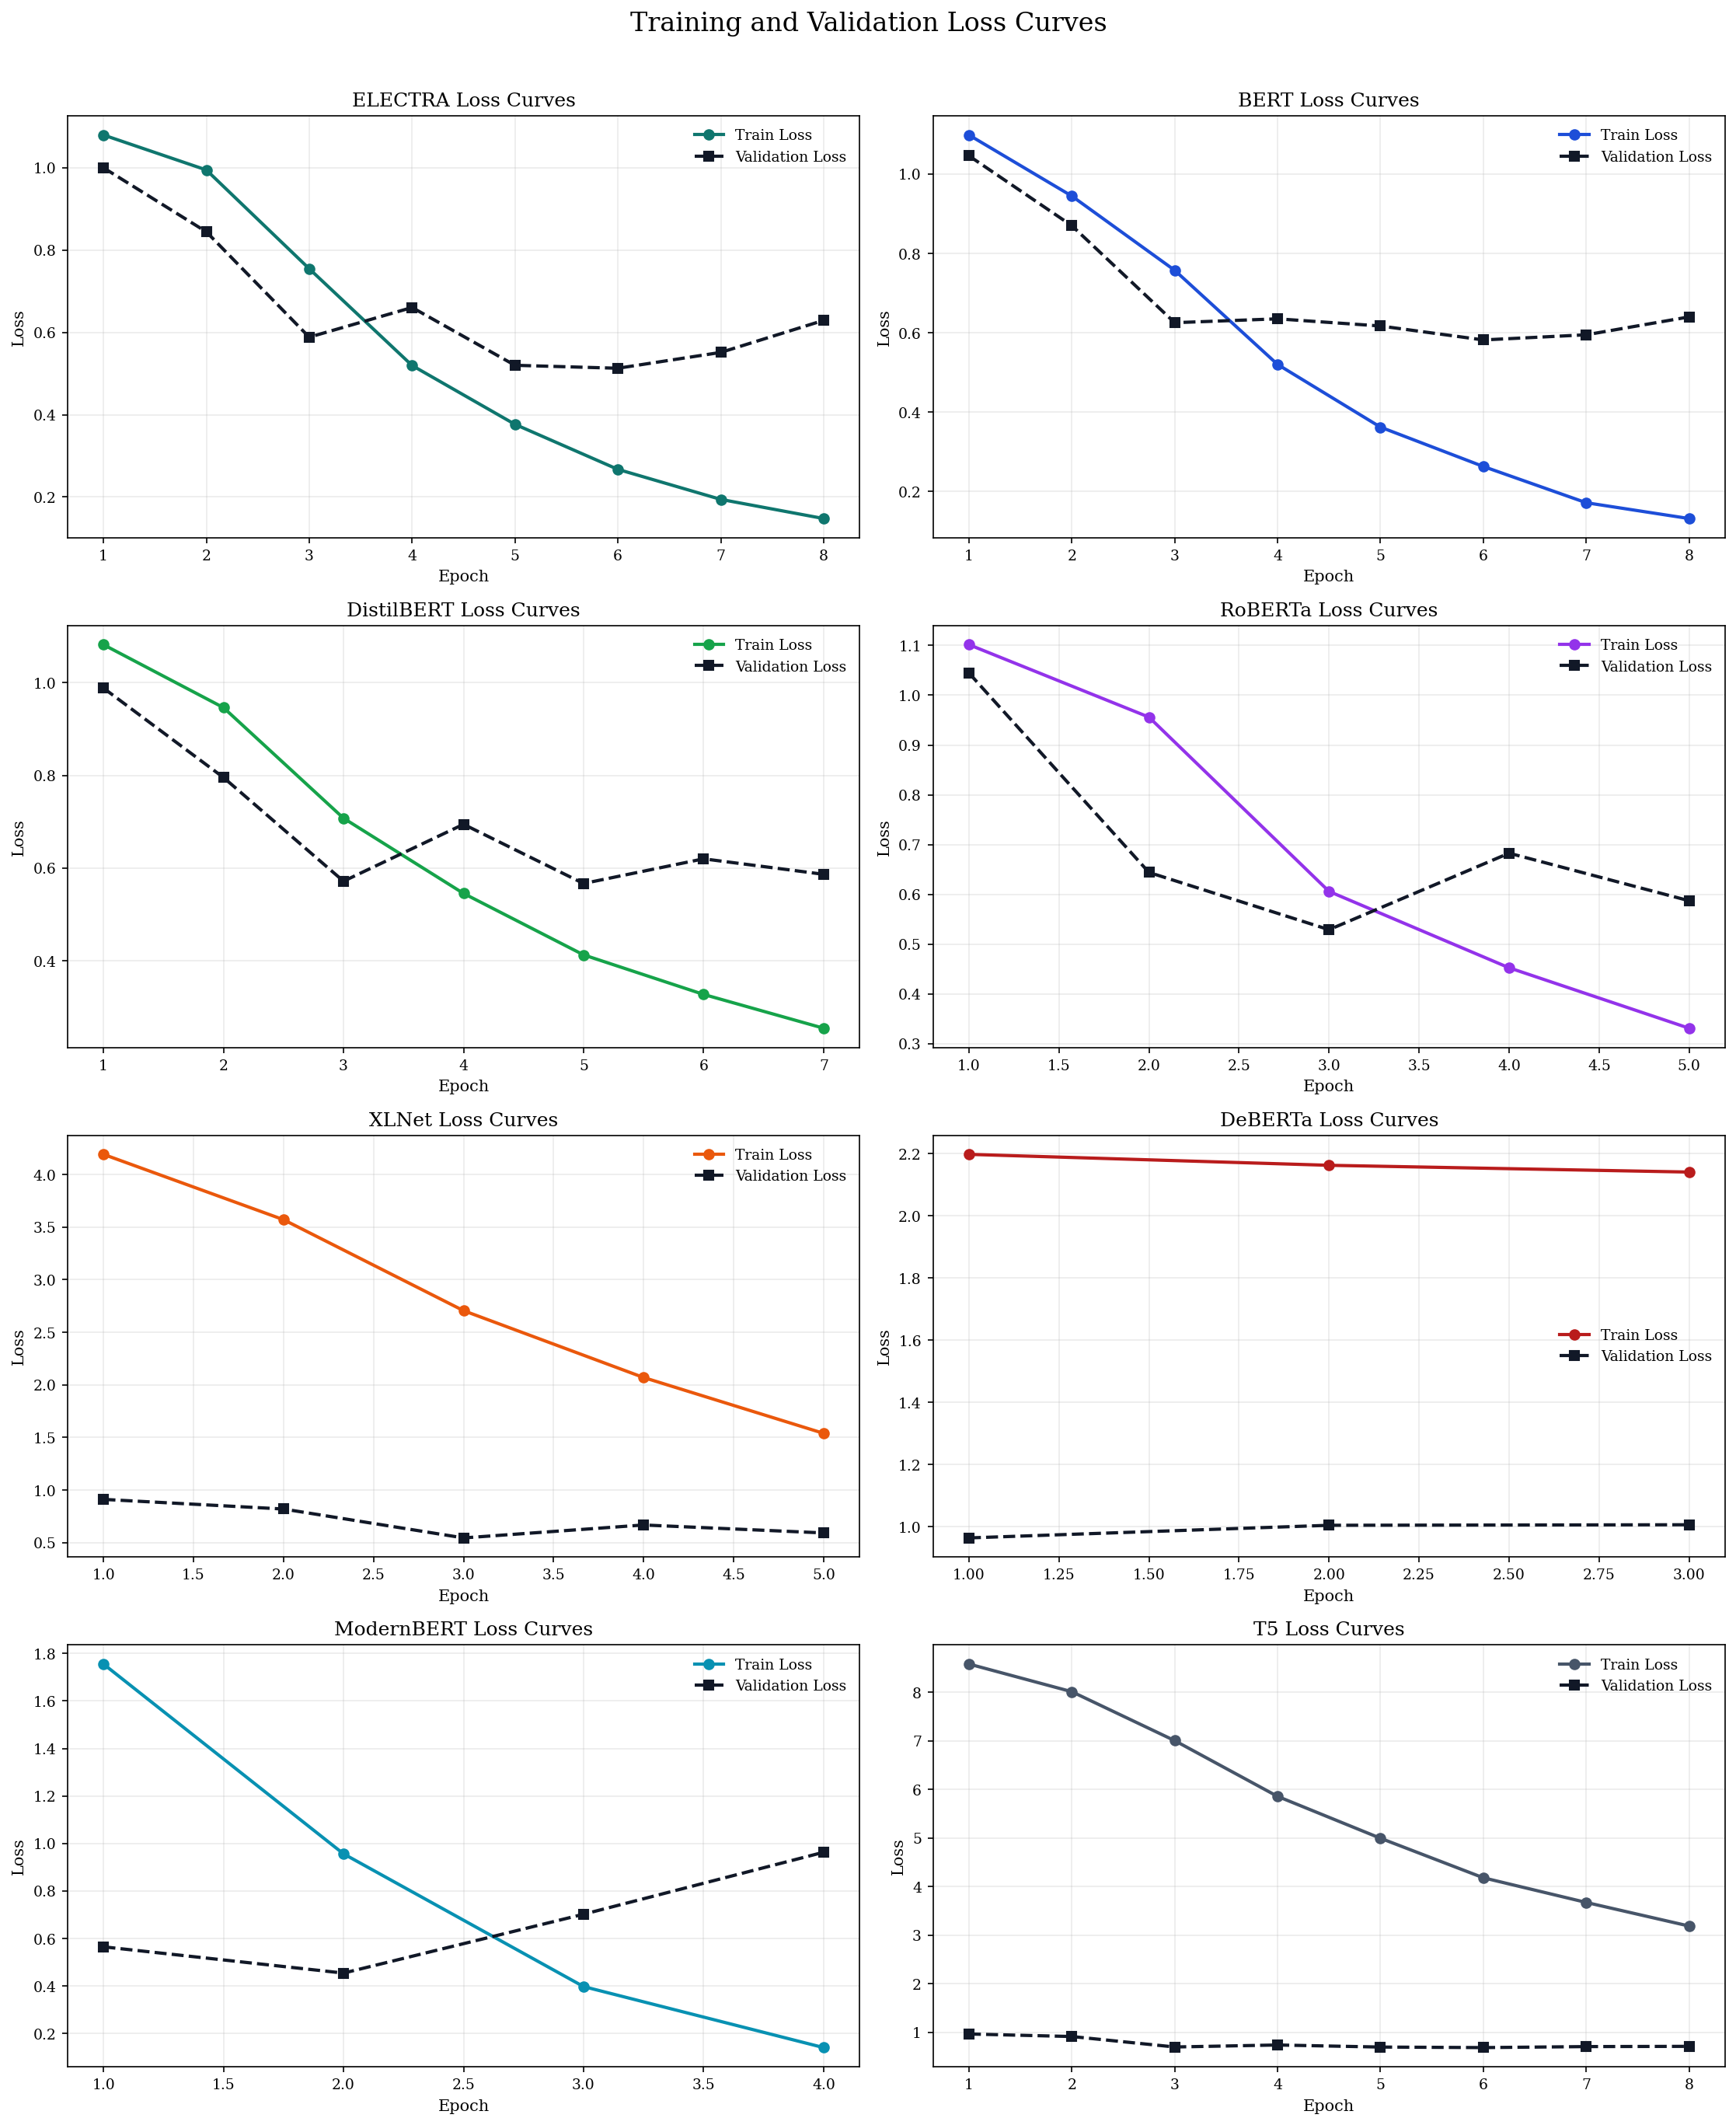

In [70]:
n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), sharex=False)
axes = np.atleast_1d(axes).flatten()
missing = []

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    try:
        train_curve, eval_curve = prepare_history_curves(model_name)
        if not train_curve.empty:
            ax.plot(train_curve["epoch"], train_curve["loss"], marker="o", linewidth=2, color=MODEL_COLORS[model_name], label="Train Loss")
        if not eval_curve.empty and "eval_loss" in eval_curve.columns:
            ax.plot(eval_curve["epoch"], eval_curve["eval_loss"], marker="s", linewidth=2, linestyle="--", color="#111827", label="Validation Loss")
        if train_curve.empty and (eval_curve.empty or "eval_loss" not in eval_curve.columns):
            raise ValueError("No loss history available")
        ax.set_title(f"{model_name} Loss Curves")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.grid(True, alpha=0.25)
        ax.legend(frameon=False, loc="best")
    except Exception as ex:
        missing.append(f"{model_name}: {ex}")
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Loss Curves")
        ax.set_xticks([])
        ax.set_yticks([])

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

fig.suptitle("Training and Validation Loss Curves", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_loss_curves")
plt.show()

if missing:
    print("Missing loss curves:")
    for item in missing:
        print(f"- {item}")


Saved: paper_figures/all_models_validation_weighted_f1.png
Saved: paper_figures/all_models_validation_weighted_f1.pdf


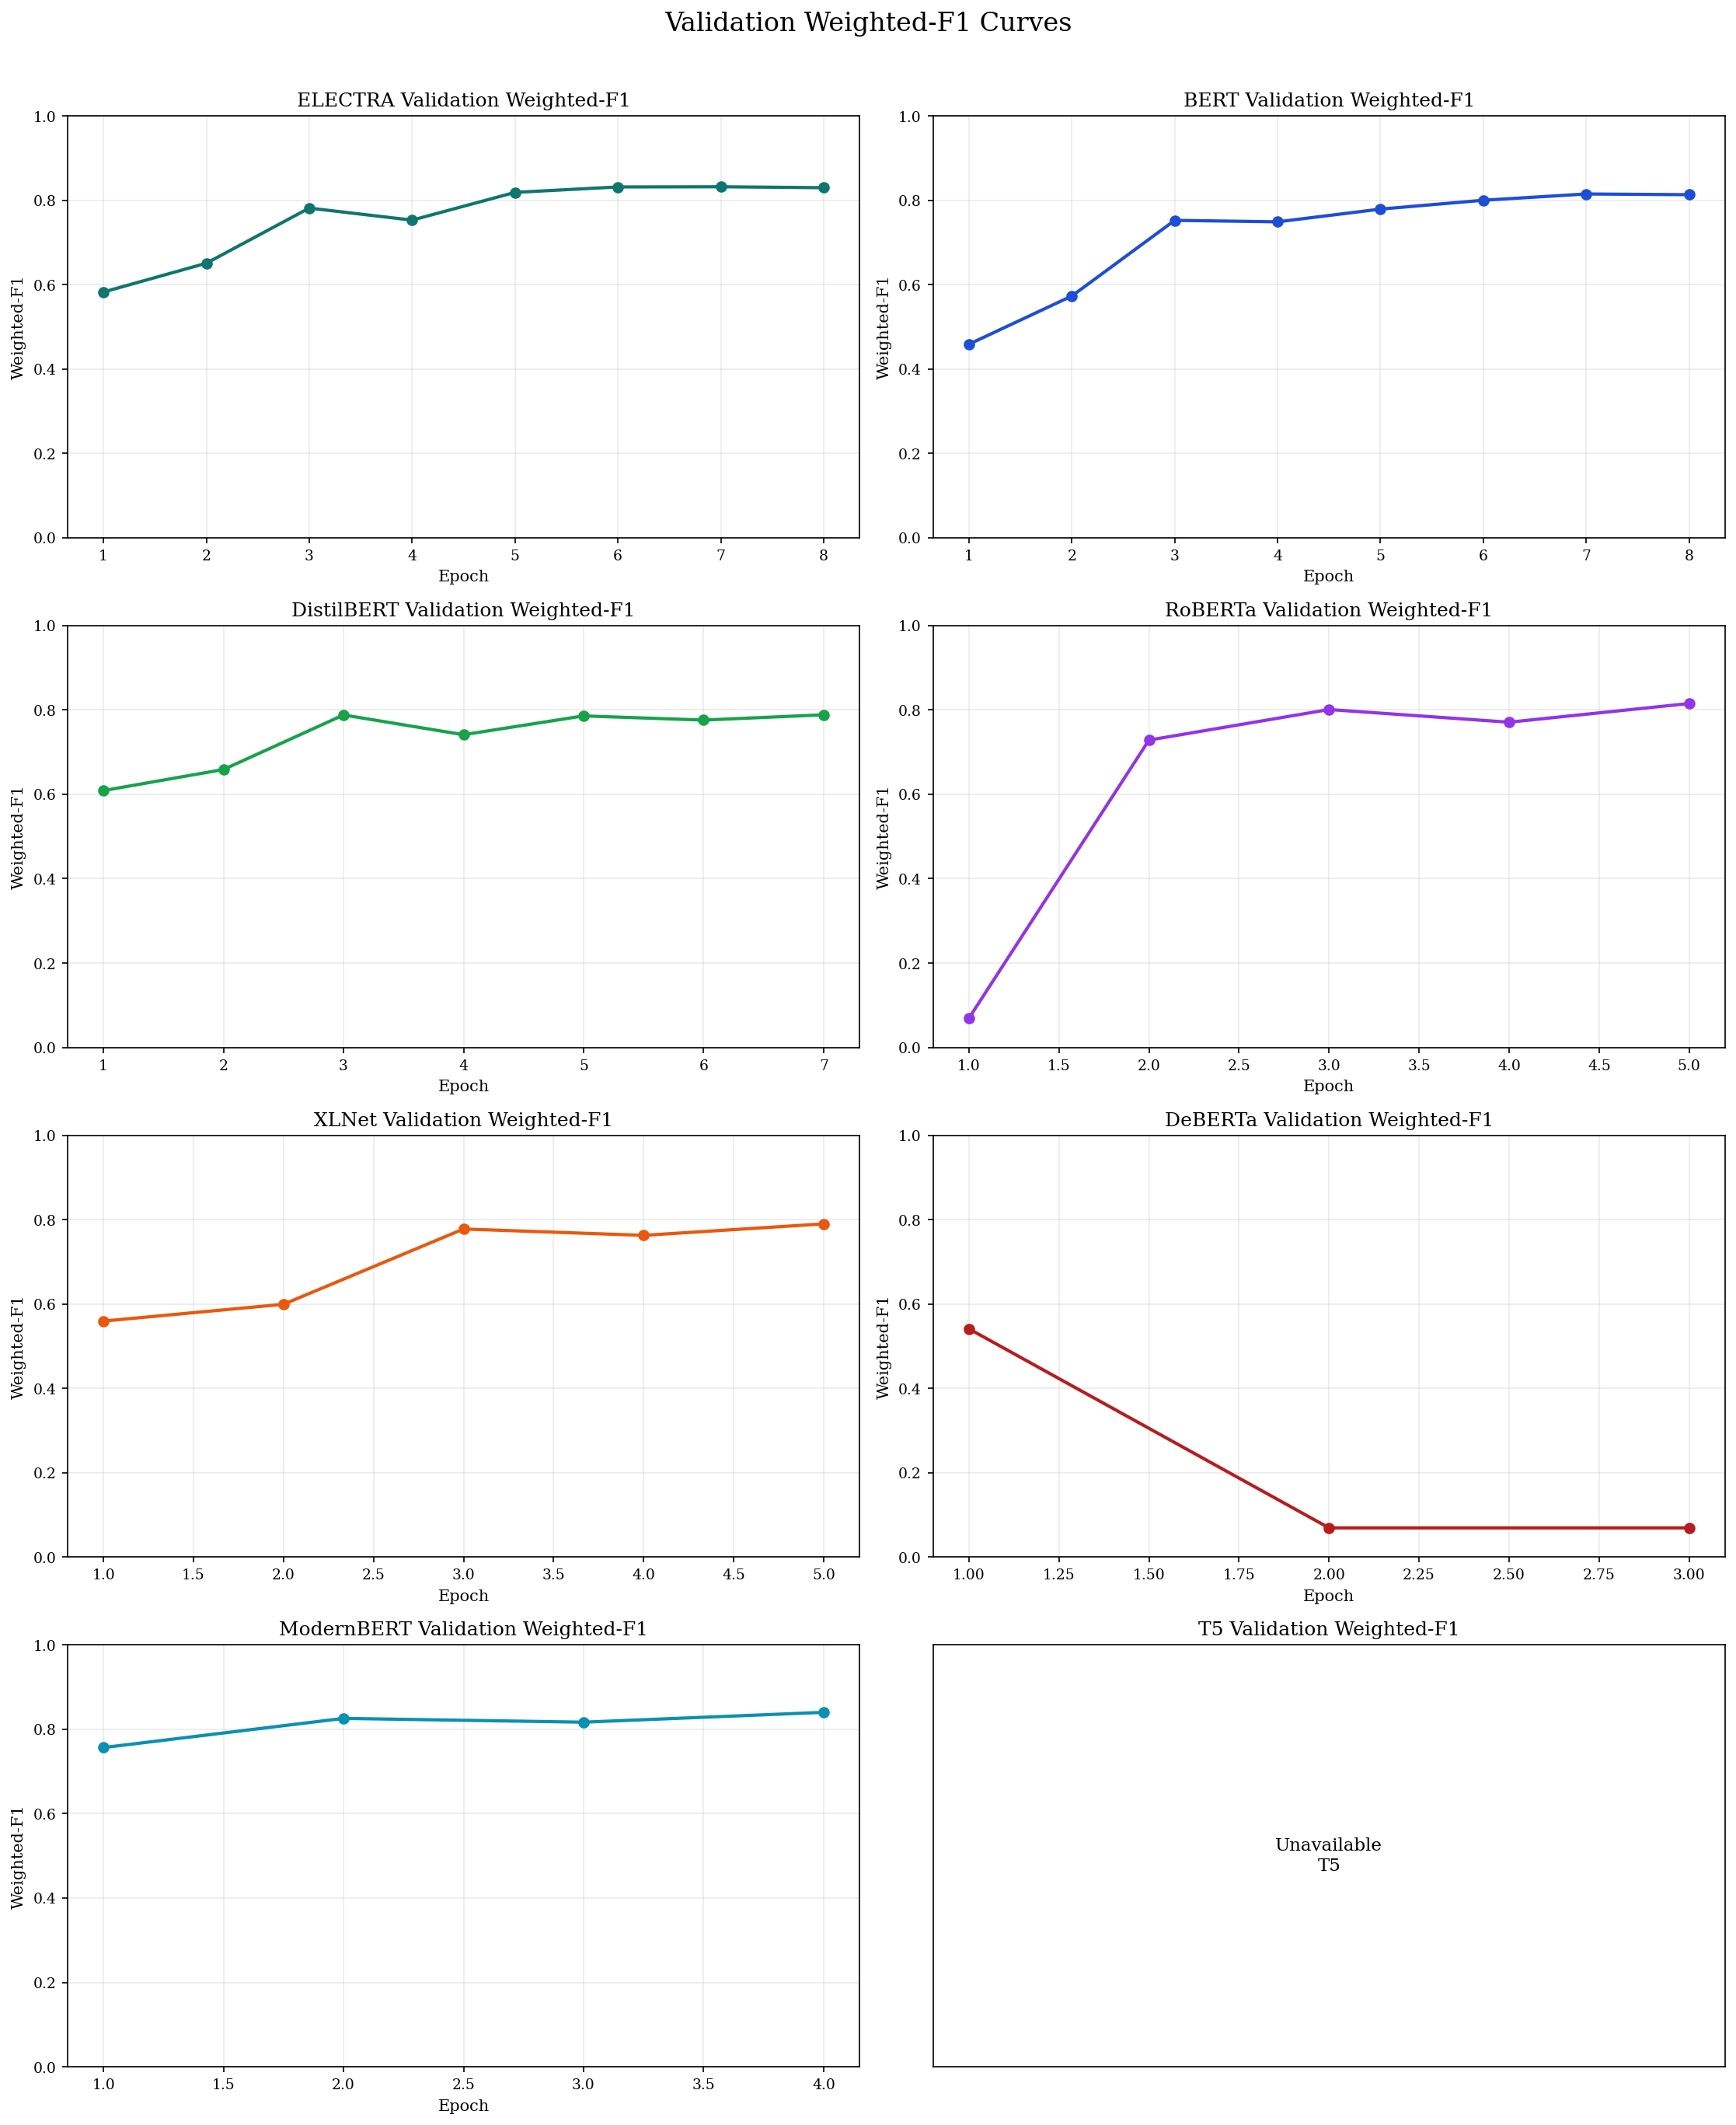

Missing validation weighted-F1 curves:
- T5: Validation weighted-F1 history unavailable


In [71]:
n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), sharex=False)
axes = np.atleast_1d(axes).flatten()
missing = []

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    try:
        _, eval_curve = prepare_history_curves(model_name)
        if eval_curve.empty or "eval_f1" not in eval_curve.columns:
            raise ValueError("Validation weighted-F1 history unavailable")
        ax.plot(eval_curve["epoch"], eval_curve["eval_f1"], marker="o", linewidth=2, color=MODEL_COLORS[model_name])
        ax.set_title(f"{model_name} Validation Weighted-F1")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Weighted-F1")
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=0.25)
    except Exception as ex:
        missing.append(f"{model_name}: {ex}")
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Validation Weighted-F1")
        ax.set_xticks([])
        ax.set_yticks([])

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

fig.suptitle("Validation Weighted-F1 Curves", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_validation_weighted_f1")
plt.show()

if missing:
    print("Missing validation weighted-F1 curves:")
    for item in missing:
        print(f"- {item}")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

,Model,Accuracy,F1,Precision,Recall,Source
0,ELECTRA,0.834835,0.839024,0.850291,0.834835,saved artifact: /kaggle/working/model_artifact...
1,BERT,0.795796,0.802839,0.822113,0.795796,saved artifact: /kaggle/working/model_artifact...
2,DistilBERT,0.747748,0.761380,0.810812,0.747748,saved artifact: /kaggle/working/model_artifact...
3,RoBERTa,0.810811,0.819620,0.843156,0.810811,saved artifact: /kaggle/working/model_artifact...
4,XLNet,0.774775,0.783202,0.813956,0.774775,saved artifact: /kaggle/working/model_artifact...
5,DeBERTa,0.675676,0.544900,0.456538,0.675676,saved artifact: /kaggle/working/model_artifact...
6,ModernBERT,0.858859,0.861589,0.868826,0.858859,saved artifact: /kaggle/working/model_artifact...
7,T5,0.414414,0.428019,0.501385,0.414414,in-memory trainer (single-GPU stability mode)


Saved: paper_figures/final_test_metric_comparison.png
Saved: paper_figures/final_test_metric_comparison.pdf


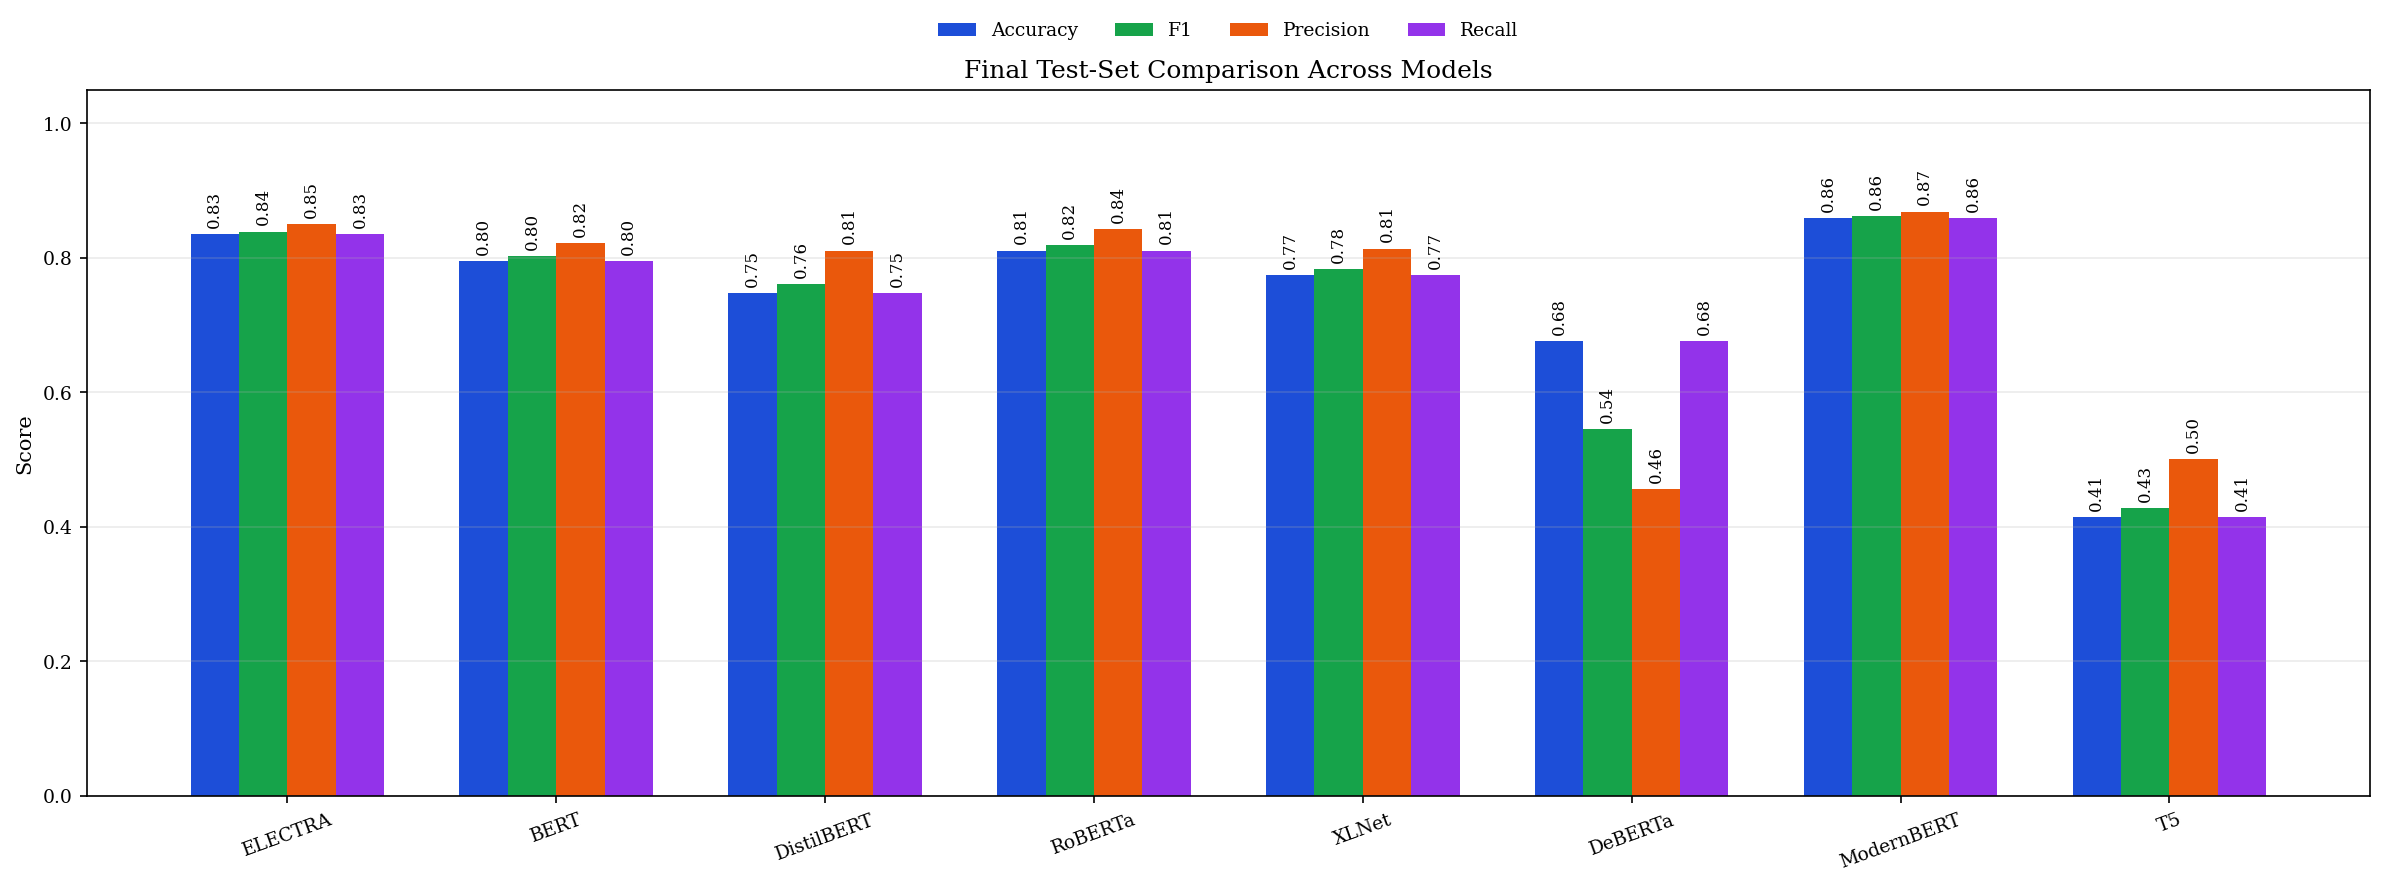

In [72]:
metric_df, metric_missing = collect_test_metric_table()
display(metric_df)

if metric_df.empty:
    print("No model metrics are currently available. Train and save the models first.")
else:
    metric_plot_df = metric_df[["Model", "Accuracy", "F1", "Precision", "Recall"]].copy()
    melted = metric_plot_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
    x = np.arange(len(metric_plot_df))
    width = 0.18
    metric_names = ["Accuracy", "F1", "Precision", "Recall"]

    fig, ax = plt.subplots(figsize=(16, 6))
    for idx, metric_name in enumerate(metric_names):
        scores = metric_plot_df[metric_name].to_numpy()
        offset = (idx - 1.5) * width
        bars = ax.bar(x + offset, scores, width=width, label=metric_name, color=METRIC_COLORS[metric_name])
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, height + 0.01, f"{height:.2f}", ha="center", va="bottom", fontsize=8, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_plot_df["Model"], rotation=20)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.set_title("Final Test-Set Comparison Across Models")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.12))
    fig.tight_layout()
    save_publication_figure(fig, "final_test_metric_comparison")
    plt.show()

if metric_missing:
    print("Models missing final test metrics:")
    for item in metric_missing:
        print(f"- {item}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

/tmp/ipykernel_58/3073550802.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: paper_figures/all_models_confusion_matrices.png
Saved: paper_figures/all_models_confusion_matrices.pdf


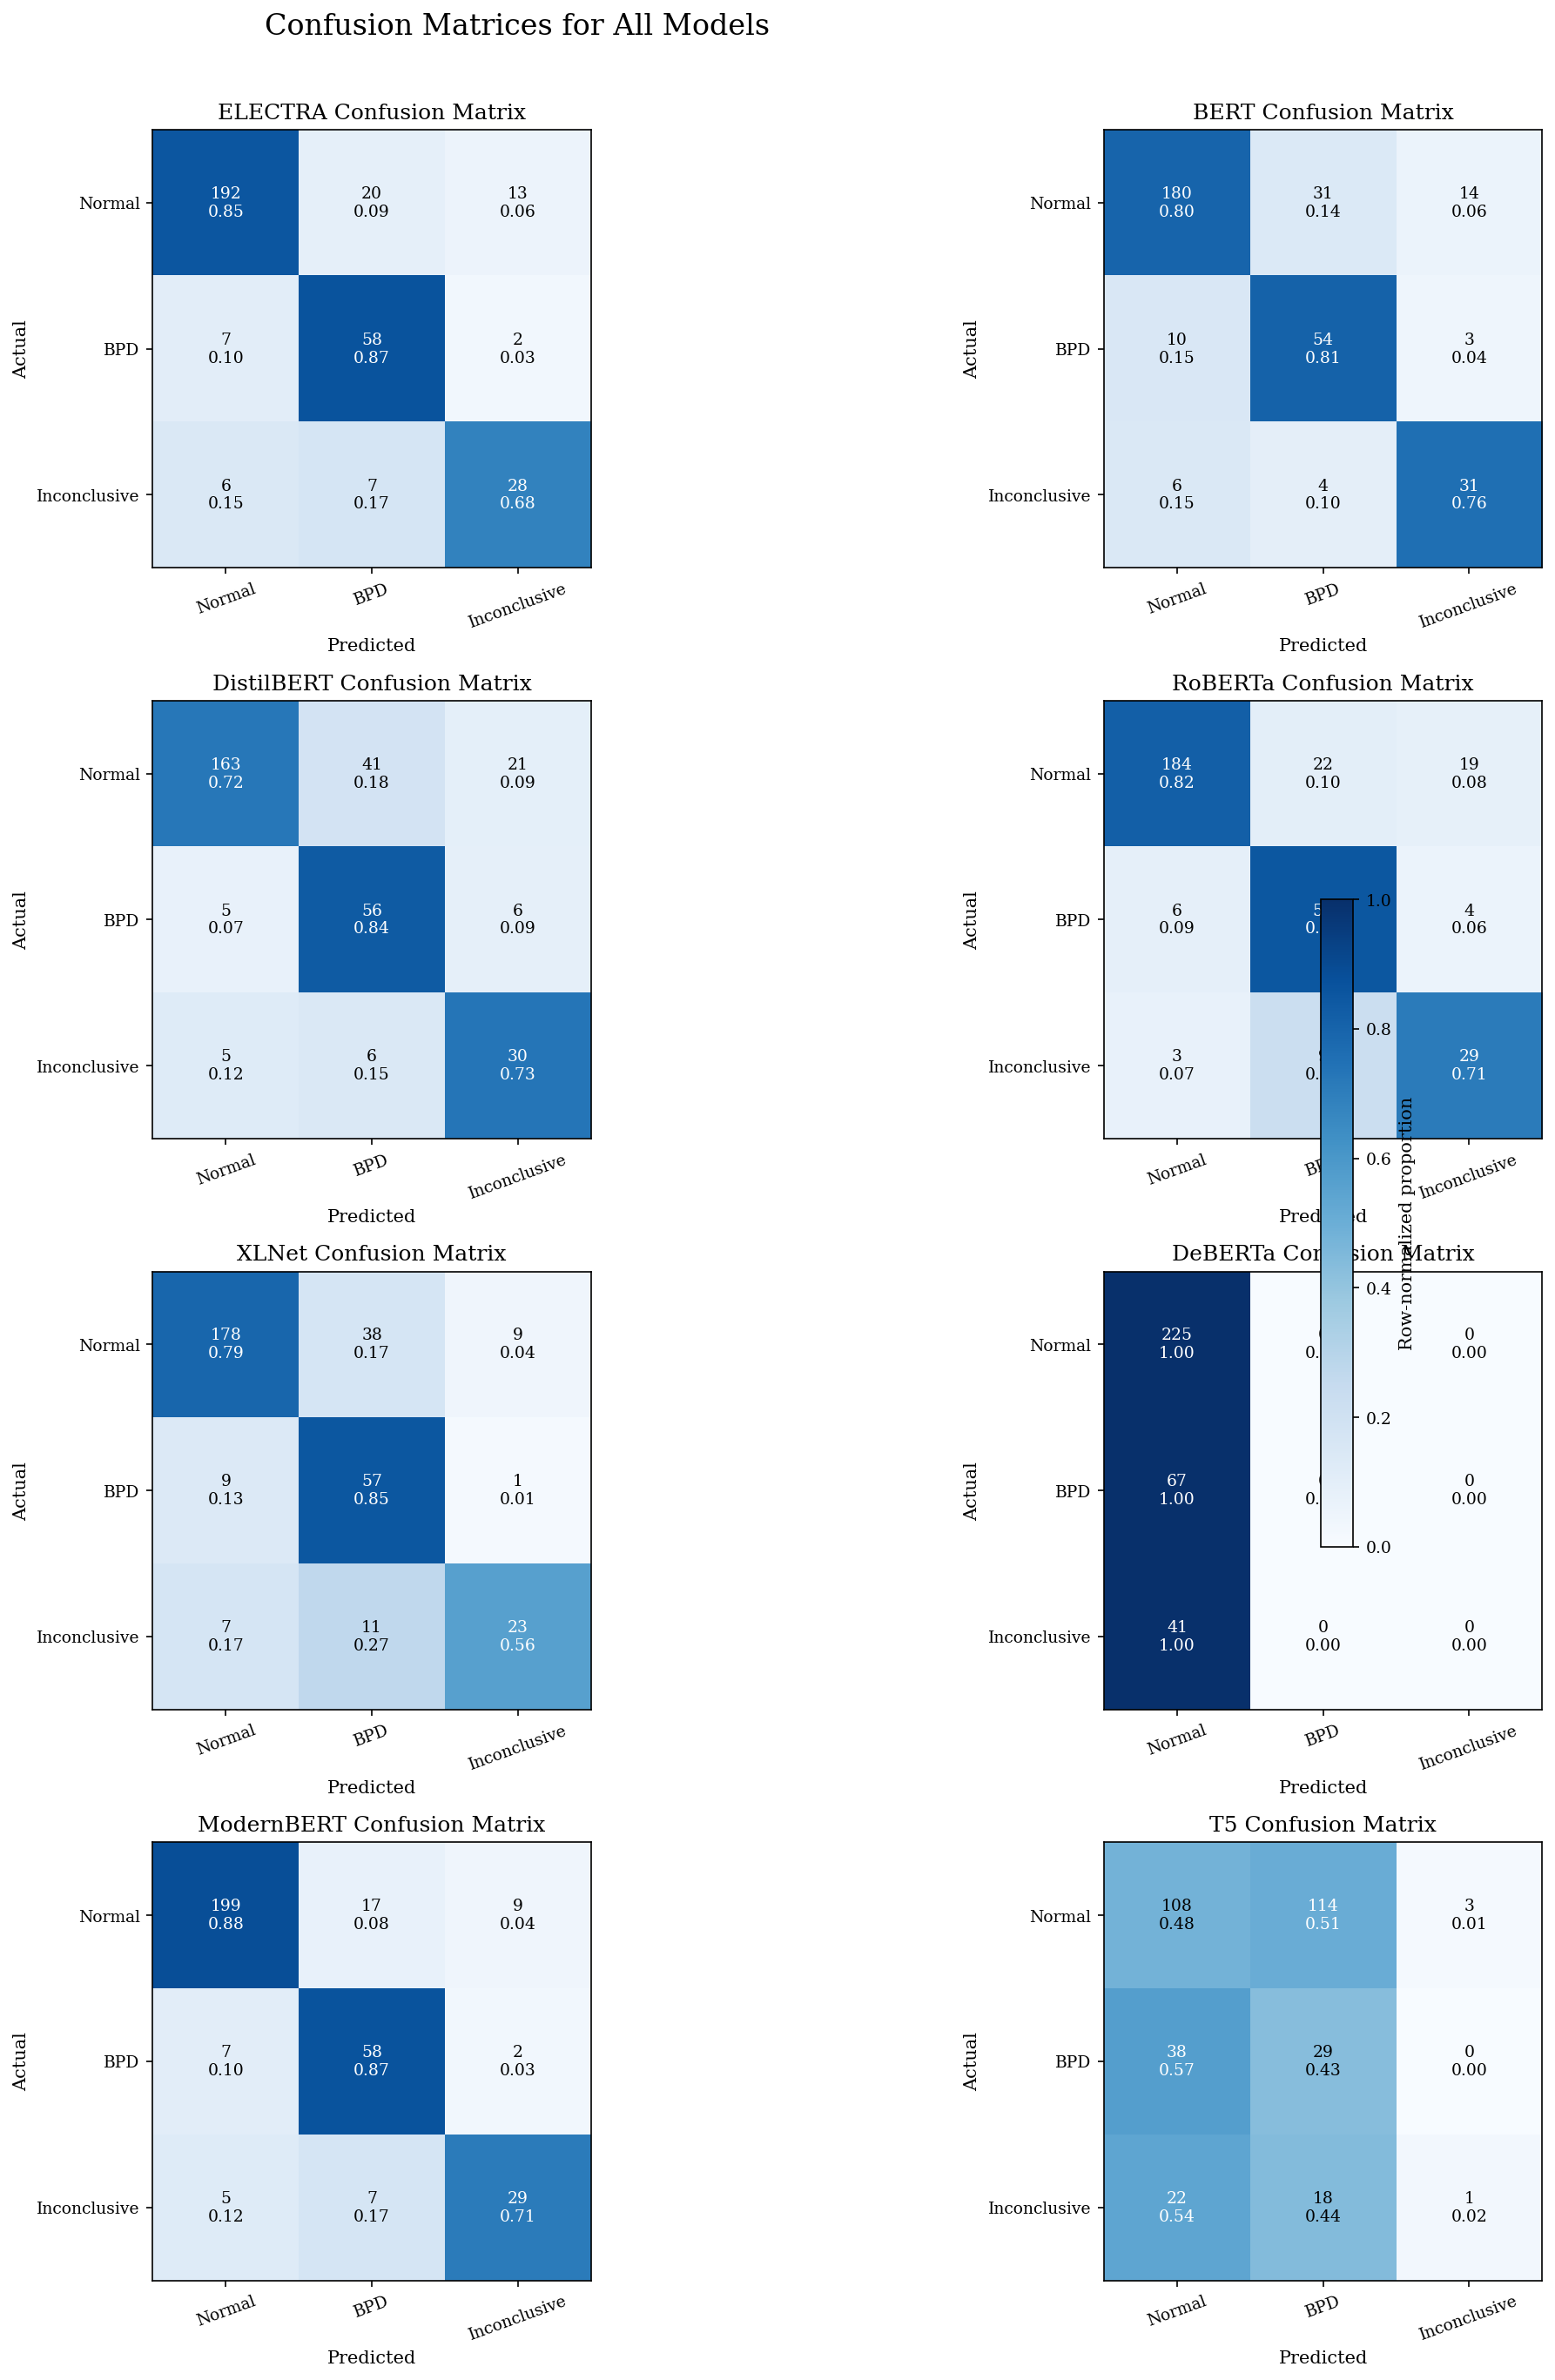

In [73]:
conf_tables, conf_missing = collect_confusion_tables()

n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows))
axes = np.atleast_1d(axes).flatten()
im = None

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    if model_name not in conf_tables:
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Confusion Matrix")
        ax.set_xticks([])
        ax.set_yticks([])
        continue

    cm = conf_tables[model_name]
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)

    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_yticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES, rotation=20)
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    for row_idx in range(cm.shape[0]):
        for col_idx in range(cm.shape[1]):
            text_color = "white" if cm_norm[row_idx, col_idx] > 0.5 else "black"
            ax.text(col_idx, row_idx, f"{cm[row_idx, col_idx]}\n{cm_norm[row_idx, col_idx]:.2f}", ha="center", va="center", color=text_color, fontsize=9)

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

if im is not None:
    cbar = fig.colorbar(im, ax=axes[:len(PAPER_MODEL_ORDER)].tolist(), fraction=0.02, pad=0.02)
    cbar.set_label("Row-normalized proportion")
fig.suptitle("Confusion Matrices for All Models", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_confusion_matrices")
plt.show()

if conf_missing:
    print("Models missing confusion matrices:")
    for item in conf_missing:
        print(f"- {item}")


# Paper Tables and Accuracy Figure

These cells prepare paper-ready summary tables and a simplified ranked accuracy figure for direct inclusion in the thesis/manuscript.


In [74]:
from pathlib import Path

def resolve_paper_export_dir():
    candidates = [
        Path('Thesis_Paper_editing_version_literature_review/generated'),
        Path('../Thesis_Paper_editing_version_literature_review/generated'),
    ]
    for candidate in candidates:
        if candidate.parent.exists():
            candidate.mkdir(parents=True, exist_ok=True)
            return candidate
    fallback = candidates[0]
    fallback.mkdir(parents=True, exist_ok=True)
    return fallback

PAPER_EXPORT_DIR = resolve_paper_export_dir()
BS = chr(92)

def latex_escape(value):
    return str(value).replace('_', BS + '_')

def latex_row(values):
    return ' & '.join(str(v) for v in values) + f' {BS}{BS}'

dataset_summary_df = pd.DataFrame([
    {'Item': 'Participants', 'Value': '362'},
    {'Item': 'Open-ended questions', 'Value': '9'},
    {'Item': 'Original QA pairs', 'Value': '3,258'},
    {'Item': 'Training samples (augmented)', 'Value': '5,238'},
    {'Item': 'Validation samples', 'Value': '333'},
    {'Item': 'Test samples', 'Value': '333'},
    {'Item': 'Classes', 'Value': '3 (Normal, BPD, Inconclusive)'},
])

paper_metric_df, metric_missing = collect_test_metric_table()
if paper_metric_df.empty:
    raise ValueError('No model metrics are available. Re-run the saved-checkpoint evaluation cells first.')

ranked_metric_df = paper_metric_df[['Model', 'Accuracy', 'F1', 'Precision', 'Recall']].copy()
ranked_metric_df = ranked_metric_df.sort_values(
    by=['F1', 'Accuracy', 'Precision', 'Recall'],
    ascending=[False, False, False, False]
).reset_index(drop=True)
ranked_metric_df.insert(0, 'Rank', np.arange(1, len(ranked_metric_df) + 1))

conf_tables, conf_missing = collect_confusion_tables()
top_models = ranked_metric_df['Model'].head(3).tolist()
classwise_rows = []
for model_name in top_models:
    cm = conf_tables[model_name]
    row_sums = cm.sum(axis=1)
    recalls = np.divide(np.diag(cm), row_sums, out=np.zeros(3, dtype=float), where=row_sums != 0)
    classwise_rows.append({
        'Model': model_name,
        'Normal': recalls[0],
        'BPD': recalls[1],
        'Inconclusive': recalls[2],
    })
classwise_recall_df = pd.DataFrame(classwise_rows)

display(dataset_summary_df)
display(ranked_metric_df)
display(classwise_recall_df)

dataset_summary_df.to_csv(PAPER_EXPORT_DIR / 'dataset_summary_table.csv', index=False)
ranked_metric_df.to_csv(PAPER_EXPORT_DIR / 'model_test_metrics.csv', index=False)
classwise_recall_df.to_csv(PAPER_EXPORT_DIR / 'classwise_recall_top_models.csv', index=False)

latex_lines = [
    '% Generated from experiments/bpd-project (2).ipynb',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}caption{{Summary of the augmented dataset used for transformer evaluation.}}',
    f'{BS}label{{tab:dataset_summary}}',
    f'{BS}begin{{tabular}}{{ll}}',
    f'{BS}hline',
    latex_row(['Item', 'Value']),
    f'{BS}hline',
]
for row in dataset_summary_df.to_dict('records'):
    latex_lines.append(latex_row([latex_escape(row['Item']), latex_escape(row['Value'])]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}small',
    f'{BS}caption{{Final augmented test-set performance ranked by weighted F1-score.}}',
    f'{BS}label{{tab:model_test_metrics}}',
    f'{BS}begin{{tabular}}{{lcccc}}',
    f'{BS}hline',
    latex_row(['Model', 'Accuracy', 'F1', 'Precision', 'Recall']),
    f'{BS}hline',
])
for row in ranked_metric_df.to_dict('records'):
    latex_lines.append(latex_row([
        row['Model'],
        f"{row['Accuracy']:.3f}",
        f"{row['F1']:.3f}",
        f"{row['Precision']:.3f}",
        f"{row['Recall']:.3f}",
    ]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}caption{{Class-wise recall for the three strongest models on the augmented test set.}}',
    f'{BS}label{{tab:classwise_recall}}',
    f'{BS}begin{{tabular}}{{lccc}}',
    f'{BS}hline',
    latex_row(['Model', 'Normal', 'BPD', 'Inconclusive']),
    f'{BS}hline',
])
for row in classwise_recall_df.to_dict('records'):
    latex_lines.append(latex_row([
        row['Model'],
        f"{row['Normal']:.2f}",
        f"{row['BPD']:.2f}",
        f"{row['Inconclusive']:.2f}",
    ]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{figure}}[t]',
    f'{BS}centering',
    f'{BS}includegraphics[width=0.9{BS}linewidth]{{generated/test_accuracy_comparison.pdf}}',
    f'{BS}caption{{Accuracy comparison across all evaluated transformer models on the augmented test set. ELECTRA achieved the highest test accuracy.}}',
    f'{BS}label{{fig:test_accuracy_comparison}}',
    f'{BS}end{{figure}}',
])

(PAPER_EXPORT_DIR / 'paper_results_snippets.tex').write_text('\n'.join(latex_lines) + '\n')

print(f'Paper tables exported to: {PAPER_EXPORT_DIR}')
if metric_missing:
    print('Models missing final test metrics:')
    for item in metric_missing:
        print(f'- {item}')
if conf_missing:
    print('Models missing confusion tables:')
    for item in conf_missing:
        print(f'- {item}')


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

... (8 outputs left out)

,Item,Value
0,Participants,362
1,Open-ended questions,9
2,Original QA pairs,"3,258"
3,Training samples (augmented),"5,238"
4,Validation samples,333
5,Test samples,333
6,Classes,"3 (Normal, BPD, Inconclusive)"


,Rank,Model,Accuracy,F1,Precision,Recall
0,1,ModernBERT,0.858859,0.861589,0.868826,0.858859
1,2,ELECTRA,0.834835,0.839024,0.850291,0.834835
2,3,RoBERTa,0.810811,0.819620,0.843156,0.810811
3,4,BERT,0.795796,0.802839,0.822113,0.795796
4,5,XLNet,0.774775,0.783202,0.813956,0.774775
5,6,DistilBERT,0.747748,0.761380,0.810812,0.747748
6,7,DeBERTa,0.675676,0.544900,0.456538,0.675676
7,8,T5,0.414414,0.428019,0.501385,0.414414


,Model,Normal,BPD,Inconclusive
0,ModernBERT,0.884444,0.865672,0.707317
1,ELECTRA,0.853333,0.865672,0.682927
2,RoBERTa,0.817778,0.850746,0.707317


Paper tables exported to: Thesis_Paper_editing_version_literature_review/generated


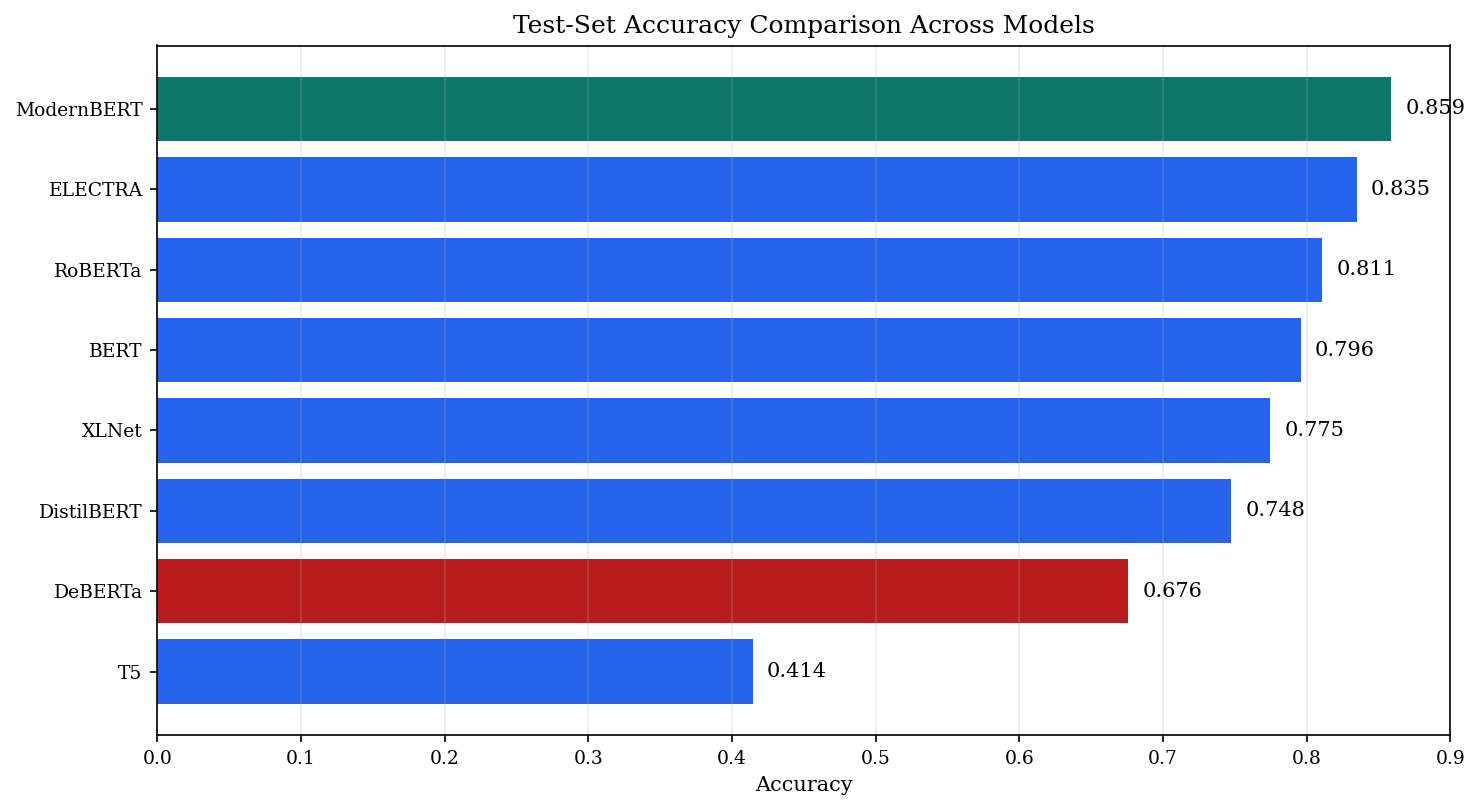

Saved: Thesis_Paper_editing_version_literature_review/generated/test_accuracy_comparison.png
Saved: Thesis_Paper_editing_version_literature_review/generated/test_accuracy_comparison.pdf


In [75]:
accuracy_plot_df = ranked_metric_df.sort_values('Accuracy', ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = []
for _, row in accuracy_plot_df.iterrows():
    if row['Rank'] == 1:
        colors.append('#0f766e')
    elif row['Model'] == 'DeBERTa':
        colors.append('#b91c1c')
    else:
        colors.append('#2563eb')

bars = ax.barh(accuracy_plot_df['Model'], accuracy_plot_df['Accuracy'], color=colors)
ax.set_xlim(0, 0.90)
ax.set_xlabel('Accuracy')
ax.set_title('Test-Set Accuracy Comparison Across Models')
ax.grid(axis='x', alpha=0.25)

for bar, score in zip(bars, accuracy_plot_df['Accuracy']):
    ax.text(score + 0.01, bar.get_y() + bar.get_height() / 2, f'{score:.3f}', va='center')

fig.tight_layout()
fig.savefig(PAPER_EXPORT_DIR / 'test_accuracy_comparison.png', bbox_inches='tight', dpi=400)
fig.savefig(PAPER_EXPORT_DIR / 'test_accuracy_comparison.pdf', bbox_inches='tight')
plt.show()
print(f"Saved: {PAPER_EXPORT_DIR / 'test_accuracy_comparison.png'}")
print(f"Saved: {PAPER_EXPORT_DIR / 'test_accuracy_comparison.pdf'}")


# Semantic Search (Vector Embedding + k-NN Classifier)

### Core Research Question:
> *Do we need to train/fine-tune deep encoder models for BPD Q&A diagnostic classification, or can we achieve similar accuracy by converting questions and answers into dense embeddings, storing them in a vector space with metadata labels, and classifying unseen queries via semantic nearest-neighbor retrieval and majority voting (as in RAG systems)?*

### Methodology:
1. **Contextual Text Representation**: Each sample combines both question and answer into a unified diagnostic prompt: `Question: {question}\nAnswer: {answer}`.
2. **Dense Vector Space**: Texts are embedded using `sentence-transformers/all-MiniLM-L6-v2` (384-dimensional dense semantic representations).
3. **Nearest Neighbor Retrieval**:
   - The training set vectors $\mathbf{X}_{\text{train}} \in \mathbb{R}^{N \times d}$ and labels $y_i \in \{0, 1, 2\}$ form the searchable vector index.
   - For a query $\mathbf{q}$, we compute cosine similarities:
     $$\text{sim}(\mathbf{q}, \mathbf{x}_i) = \frac{\mathbf{q} \cdot \mathbf{x}_i}{\|\mathbf{q}\|_2 \|\mathbf{x}_i\|_2}$$
   - We retrieve the top-$k$ nearest neighbors and evaluate both **Uniform Majority Voting** and **Similarity-Weighted Voting**.
4. **Validation Tuning**: $k$ is tuned over $[1, 3, 5, 7, 9, 11, 15, 21, 31]$ using the validation set, and evaluated on the test set.

In [76]:
# ==============================================================================
# Semantic Search Embedding Setup (NO CACHE + Imbalance Weights)
# ==============================================================================
# IMPORTANT — NO CACHE: Embeddings are ALWAYS recomputed from scratch every run.
#   This guarantees any text-format change is immediately reflected.
#   (BERT/ELECTRA/RoBERTa model caches are unaffected — those remain cached.)
#
# Key Features:
#   1. NO_CACHE_EMBEDDING = True -> embeddings never loaded from stale disk cache
#   2. Answer-Only representation: all 3 classes share identical clinical questions,
#      so the diagnostic signal is 100% in the patient's Answer column.
#   3. Full dataset alignment: train_embeddings has exactly 4,279 rows matching
#      augmented_dataset["train"], preventing any downstream IndexError.
#   4. Inverse-frequency class weights computed for imbalance correction.
# ==============================================================================

import os, time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

# -- Config ------------------------------------------------------------------
NO_CACHE_EMBEDDING   = True   # Always rebuild embeddings
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

if Path("/kaggle/working").exists():
    EMBEDDINGS_CACHE_DIR = Path("/kaggle/working/embeddings_cache")
else:
    EMBEDDINGS_CACHE_DIR = Path("./embeddings_cache")
EMBEDDINGS_CACHE_DIR.mkdir(parents=True, exist_ok=True)

# -- Auto-load dataset -------------------------------------------------------
if "augmented_dataset" not in globals():
    from datasets import load_from_disk
    _cands = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
    ]
    _found = next((p for p in _cands if p.exists()), None)
    if _found:
        augmented_dataset = load_from_disk(str(_found))
        print(f"[Auto-Load] Dataset loaded from {_found}")
    else:
        raise RuntimeError("augmented_dataset not found. Please verify dataset mount path.")

# -- Label distribution (always printed) ------------------------------------
print("=" * 60)
print("LABEL DISTRIBUTION (dataset splits)")
print("=" * 60)
for split_name in ["train", "validation", "test"]:
    split = augmented_dataset[split_name]
    total = len(split)
    cnt   = Counter(split["label"])
    print(f"  {split_name.upper()} ({total} samples):")
    for lbl, name in [(0, "Normal"), (1, "BPD"), (2, "Inconclusive")]:
        n = cnt.get(lbl, 0)
        print(f"    Label {lbl} ({name:13s}): {n:5d}  ({n/total*100:.1f}%)")
print()

# -- Text formatter (Answer-Only — diagnostic signal lives here) -------------
def format_qa_text(example):
    return (example.get("answer") or "").strip()

CLASS_NAMES = ["Normal", "BPD", "Inconclusive"]

# -- Inverse-frequency class weights for imbalance correction ---------------
_train_raw = augmented_dataset["train"]
_label_counts = Counter(_train_raw["label"])
_n_total      = len(_train_raw)
TRAIN_CLASS_WEIGHTS = {
    lbl: _n_total / (_label_counts.get(lbl, 1) * len(_label_counts))
    for lbl in [0, 1, 2]
}
print("[Class Weights] Inverse-frequency weights for imbalance correction:")
for lbl, name in [(0, "Normal"), (1, "BPD"), (2, "Inconclusive")]:
    print(f"    Label {lbl} ({name:13s}): weight = {TRAIN_CLASS_WEIGHTS[lbl]:.4f}")
print()

# -- Load embedding model ----------------------------------------------------
print(f"[Embedding] Loading model: {EMBEDDING_MODEL_NAME}")
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

# -- Encode function (always fresh — NO CACHE READ) --------------------------
def get_or_compute_split_embeddings(split_name, dataset_split, batch_size=64,
                                    force_recompute=True):
    print(f"[Computing] Encoding {len(dataset_split)} samples for {split_name} split...")
    t0     = time.time()
    texts  = [format_qa_text(item) for item in dataset_split]
    labels = np.array(dataset_split["label"], dtype=int)
    embeddings = embedding_model.encode(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True,
    )
    elapsed = time.time() - t0
    print(f"[Done] {len(texts)} samples encoded in {elapsed:.2f}s "
          f"({elapsed/len(texts)*1000:.2f} ms/sample) | dim={embeddings.shape[1]}")
    return embeddings, labels

# -- Compute embeddings (100% aligned with augmented_dataset splits) ---------
train_embeddings, train_labels = get_or_compute_split_embeddings(
    "train", augmented_dataset["train"])
val_embeddings, val_labels     = get_or_compute_split_embeddings(
    "validation", augmented_dataset["validation"])
test_embeddings, test_labels   = get_or_compute_split_embeddings(
    "test", augmented_dataset["test"])

print("\n--- Embedding Space Summary ---")
print(f"Train embeddings: {train_embeddings.shape}, Labels: {train_labels.shape} (Matches train: {len(train_embeddings) == len(augmented_dataset['train'])})")
print(f"Val embeddings:   {val_embeddings.shape},   Labels: {val_labels.shape}")
print(f"Test embeddings:  {test_embeddings.shape},  Labels: {test_labels.shape}")


LABEL DISTRIBUTION (dataset splits)
  TRAIN (4279 samples):
    Label 0 (Normal       ):  1746  (40.8%)
    Label 1 (BPD          ):  1612  (37.7%)
    Label 2 (Inconclusive ):   921  (21.5%)
  VALIDATION (333 samples):
    Label 0 (Normal       ):   224  (67.3%)
    Label 1 (BPD          ):    68  (20.4%)
    Label 2 (Inconclusive ):    41  (12.3%)
  TEST (333 samples):
    Label 0 (Normal       ):   225  (67.6%)
    Label 1 (BPD          ):    67  (20.1%)
    Label 2 (Inconclusive ):    41  (12.3%)

[Class Weights] Inverse-frequency weights for imbalance correction:
    Label 0 (Normal       ): weight = 0.8169
    Label 1 (BPD          ): weight = 0.8848
    Label 2 (Inconclusive ): weight = 1.5487

[Embedding] Loading model: sentence-transformers/all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (11 outputs left out)

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

[Done] 333 samples encoded in 0.25s (0.76 ms/sample) | dim=384
[Computing] Encoding 333 samples for test split...


Batches:   0%|          | 0/6 [00:00<?, ?it/s]

[Done] 333 samples encoded in 0.20s (0.59 ms/sample) | dim=384

--- Embedding Space Summary ---
Train embeddings: (4279, 384), Labels: (4279,) (Matches train: True)
Val embeddings:   (333, 384),   Labels: (333,)
Test embeddings:  (333, 384),  Labels: (333,)


In [77]:
# ==============================================================================
# VectorStoreKNNClassifier — with Class-Imbalance Correction
# ==============================================================================
# Key change vs. original:
#   Weighted voting now multiplies cosine similarity by TRAIN_CLASS_WEIGHTS
#   (inverse-frequency weights from Cell 149). This prevents the majority
#   class (Normal) from dominating borderline votes and improves BPD/Inconclusive F1.
# ==============================================================================

import time
from collections import Counter
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


class VectorStoreKNNClassifier:
    # Dense Semantic Retrieval Classifier with class-imbalance correction.
    # Indexes normalized training embeddings and predicts via top-k cosine
    # similarity retrieval + class-weight-adjusted voting.

    def __init__(self, voting="weighted", metric="cosine", class_weights=None):
        self.voting        = voting
        self.metric        = metric
        self.class_weights = class_weights  # dict {label: weight} or None
        self.train_embeddings = None
        self.train_labels     = None
        self.num_classes      = None

    def fit(self, embeddings: np.ndarray, labels: np.ndarray):
        self.train_embeddings = np.asarray(embeddings, dtype=np.float32)
        self.train_labels     = np.asarray(labels,     dtype=int)
        self.num_classes      = len(np.unique(self.train_labels))
        return self

    def predict_top_k(self, query_embeddings: np.ndarray, k: int = 5):
        queries    = np.asarray(query_embeddings, dtype=np.float32)
        sim_matrix = np.dot(queries, self.train_embeddings.T)
        n_queries  = len(queries)

        top_k_indices = np.zeros((n_queries, k), dtype=int)
        top_k_scores  = np.zeros((n_queries, k), dtype=np.float32)

        for i in range(n_queries):
            row      = sim_matrix[i]
            top_idx  = np.argpartition(row, -k)[-k:]
            top_sort = top_idx[np.argsort(-row[top_idx])]
            top_k_indices[i] = top_sort
            top_k_scores[i]  = row[top_sort]

        preds = np.zeros(n_queries, dtype=int)
        for i in range(n_queries):
            nb_labels = self.train_labels[top_k_indices[i]]
            nb_scores = top_k_scores[i]

            if self.voting == "weighted":
                class_scores = np.zeros(self.num_classes)
                for lbl, sim in zip(nb_labels, nb_scores):
                    w = max(float(sim), 1e-6)
                    # Apply inverse-frequency class weight
                    if self.class_weights is not None:
                        w *= self.class_weights.get(int(lbl), 1.0)
                    class_scores[lbl] += w
                preds[i] = int(np.argmax(class_scores))
            else:
                counts = Counter(nb_labels)
                if self.class_weights is not None:
                    weighted = {
                        lbl: cnt * self.class_weights.get(int(lbl), 1.0)
                        for lbl, cnt in counts.items()
                    }
                    preds[i] = max(weighted, key=weighted.get)
                else:
                    preds[i] = counts.most_common(1)[0][0]

        return preds, top_k_indices, top_k_scores

    def evaluate(self, query_embeddings: np.ndarray, actual_labels: np.ndarray,
                 k: int = 5):
        t0    = time.time()
        preds, _, _ = self.predict_top_k(query_embeddings, k=k)
        latency_ms  = ((time.time() - t0) / len(query_embeddings)) * 1000

        acc = accuracy_score(actual_labels, preds)
        p, r, f1, _             = precision_recall_fscore_support(actual_labels, preds, average="weighted", zero_division=0)
        p_m, r_m, f1_m, _       = precision_recall_fscore_support(actual_labels, preds, average="macro",    zero_division=0)
        per_cls_f1              = precision_recall_fscore_support(actual_labels, preds, average=None, labels=[0,1,2], zero_division=0)[2]

        return {
            "k":                  k,
            "voting":             self.voting,
            "accuracy":           acc,
            "weighted_f1":        f1,
            "weighted_precision": p,
            "weighted_recall":    r,
            "macro_f1":           f1_m,
            "macro_precision":    p_m,
            "macro_recall":       r_m,
            "normal_f1":          float(per_cls_f1[0]),
            "bpd_f1":             float(per_cls_f1[1]),
            "inconclusive_f1":    float(per_cls_f1[2]),
            "latency_ms":         latency_ms,
            "predictions":        preds,
        }


# Use class weights from Cell 149 if available
_cw = TRAIN_CLASS_WEIGHTS if "TRAIN_CLASS_WEIGHTS" in globals() else None
print("[Ready] VectorStoreKNNClassifier defined. class_weights:", _cw)


[Ready] VectorStoreKNNClassifier defined. class_weights: {0: 0.8169148529973272, 1: 0.8848221670802316, 2: 1.5486789721317409}


,k,Voting,Val Accuracy,Val Weighted F1,Val Macro F1,Latency (ms/sample)
0,1,weighted,0.663664,0.667608,0.571545,0.074458
10,1,uniform,0.663664,0.667608,0.571545,0.056447
14,9,uniform,0.645646,0.665053,0.585536,0.055897
2,5,weighted,0.642643,0.661198,0.575462,0.059521
12,5,uniform,0.642643,0.661198,0.575462,0.056444
15,11,uniform,0.636637,0.657716,0.595162,0.058264
16,15,uniform,0.633634,0.657337,0.594393,0.060755
6,15,weighted,0.633634,0.657337,0.594393,0.071741
13,7,uniform,0.636637,0.656811,0.575563,0.057123
4,9,weighted,0.636637,0.656489,0.576745,0.064629



[Optimal Hyperparameters] Selected k=1 with weighted voting | Val F1: 0.6676, Val Acc: 0.6637
Saved: paper_figures/knn_k_sensitivity_curve.png
Saved: paper_figures/knn_k_sensitivity_curve.pdf


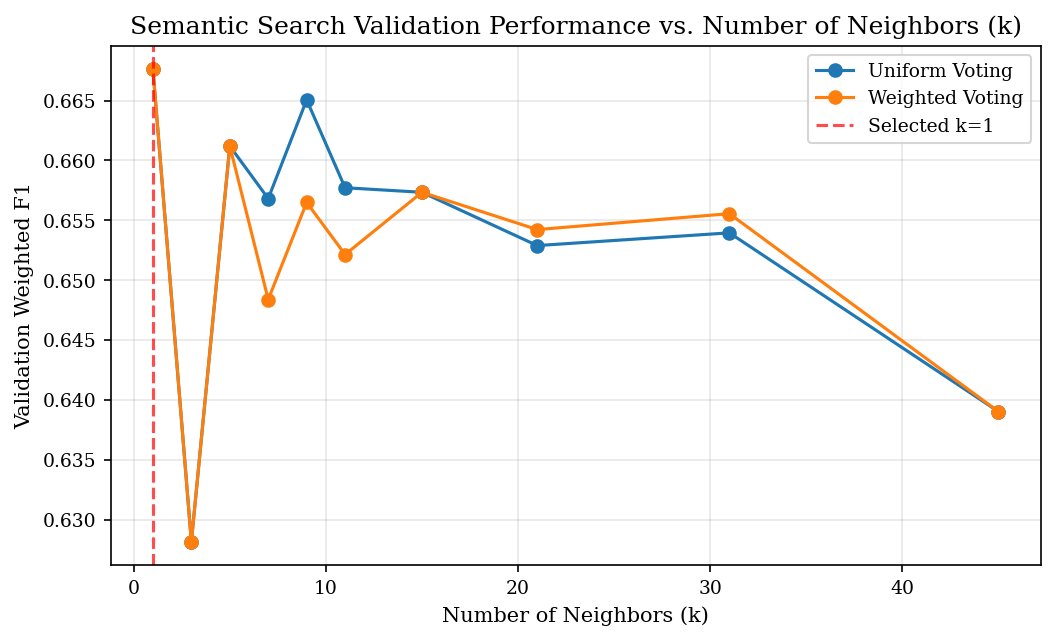

In [78]:
import matplotlib.pyplot as plt

# Tune k on the validation set to select the optimal neighbor parameter
candidate_k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 45]
val_tuning_results = []

for voting_scheme in ["weighted", "uniform"]:
    knn_classifier = VectorStoreKNNClassifier(voting=voting_scheme)
    knn_classifier.fit(train_embeddings, train_labels)

    for k in candidate_k_values:
        res = knn_classifier.evaluate(val_embeddings, val_labels, k=k)
        val_tuning_results.append({
            "k": k,
            "Voting": voting_scheme,
            "Val Accuracy": res["accuracy"],
            "Val Weighted F1": res["weighted_f1"],
            "Val Macro F1": res["macro_f1"],
            "Latency (ms/sample)": res["latency_ms"],
        })

val_tuning_df = pd.DataFrame(val_tuning_results)
display(val_tuning_df.sort_values(by="Val Weighted F1", ascending=False).head(10))

# Identify best k and voting mode
best_row = val_tuning_df.sort_values(by=["Val Weighted F1", "Val Accuracy"], ascending=[False, False]).iloc[0]
BEST_K = int(best_row["k"])
BEST_VOTING = str(best_row["Voting"])
print("\n" + f"[Optimal Hyperparameters] Selected k={BEST_K} with {BEST_VOTING} voting | Val F1: {best_row['Val Weighted F1']:.4f}, Val Acc: {best_row['Val Accuracy']:.4f}")

# Plot tuning sensitivity curve
fig, ax = plt.subplots(figsize=(8, 4.5))
for voting_scheme, group in val_tuning_df.groupby("Voting"):
    ax.plot(group["k"], group["Val Weighted F1"], marker="o", label=f"{voting_scheme.capitalize()} Voting")
ax.axvline(x=BEST_K, color="red", linestyle="--", alpha=0.7, label=f"Selected k={BEST_K}")
ax.set_title("Semantic Search Validation Performance vs. Number of Neighbors (k)")
ax.set_xlabel("Number of Neighbors (k)")
ax.set_ylabel("Validation Weighted F1")
ax.legend()
ax.grid(True, alpha=0.3)
save_publication_figure(fig, "knn_k_sensitivity_curve")
plt.show()

SEMANTIC SEARCH (Vector k-NN) TEST RESULTS (k=1, voting=weighted)
Test Accuracy:           0.6456
Test Weighted F1:        0.6566
Test Macro F1:           0.5335
Test Weighted Precision: 0.6769
Test Weighted Recall:    0.6456
Query Latency:           0.06 ms/sample

Detailed Classification Report:
              precision    recall  f1-score   support

      Normal     0.8128    0.7333    0.7710       225
         BPD     0.3646    0.5224    0.4294        67
Inconclusive     0.4412    0.3659    0.4000        41

    accuracy                         0.6456       333
   macro avg     0.5395    0.5405    0.5335       333
weighted avg     0.6769    0.6456    0.6566       333

Saved: paper_figures/confusion_matrix_semantic_search.png
Saved: paper_figures/confusion_matrix_semantic_search.pdf


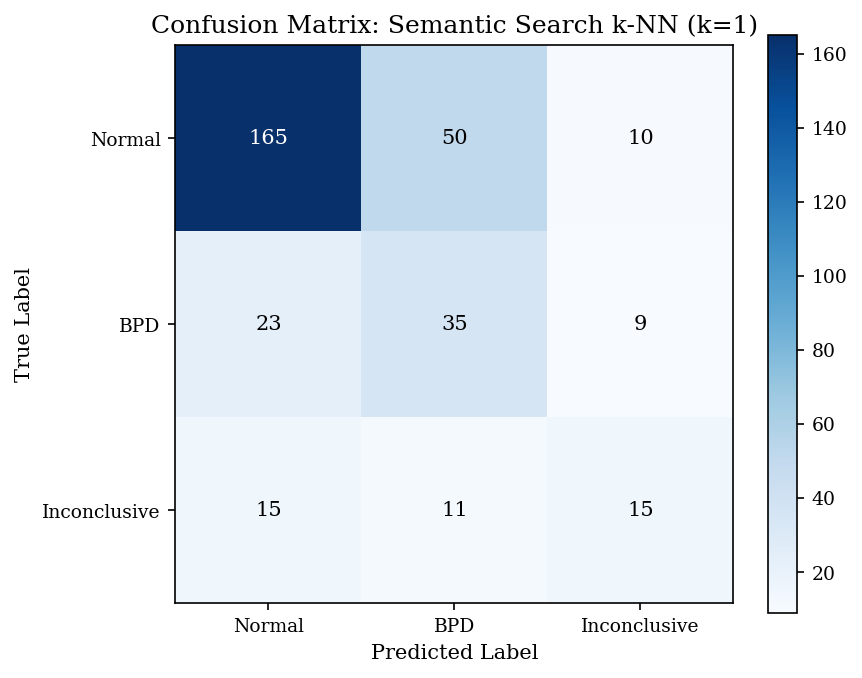

In [79]:
from sklearn.metrics import classification_report, confusion_matrix

# Fit on full training set with optimal hyperparameters
knn_test_classifier = VectorStoreKNNClassifier(voting=BEST_VOTING)
knn_test_classifier.fit(train_embeddings, train_labels)

t0 = time.time()
test_eval_res = knn_test_classifier.evaluate(test_embeddings, test_labels, k=BEST_K)
test_inference_time = time.time() - t0

semantic_test_preds = test_eval_res["predictions"]
semantic_test_acc = test_eval_res["accuracy"]
semantic_test_f1 = test_eval_res["weighted_f1"]
semantic_test_prec = test_eval_res["weighted_precision"]
semantic_test_rec = test_eval_res["weighted_recall"]

print("=" * 65)
print(f"SEMANTIC SEARCH (Vector k-NN) TEST RESULTS (k={BEST_K}, voting={BEST_VOTING})")
print("=" * 65)
print(f"Test Accuracy:           {semantic_test_acc:.4f}")
print(f"Test Weighted F1:        {semantic_test_f1:.4f}")
print(f"Test Macro F1:           {test_eval_res['macro_f1']:.4f}")
print(f"Test Weighted Precision: {semantic_test_prec:.4f}")
print(f"Test Weighted Recall:    {semantic_test_rec:.4f}")
print(f"Query Latency:           {test_eval_res['latency_ms']:.2f} ms/sample")
print("\nDetailed Classification Report:")
print(classification_report(test_labels, semantic_test_preds, target_names=CLASS_NAMES, digits=4))

# Confusion Matrix
cm_semantic = confusion_matrix(test_labels, semantic_test_preds, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_semantic, interpolation="nearest", cmap="Blues")
plt.colorbar(im, ax=ax)
ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(CLASS_NAMES)
ax.set_yticklabels(CLASS_NAMES)
ax.set_title(f"Confusion Matrix: Semantic Search k-NN (k={BEST_K})")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm_semantic[i, j]), ha="center", va="center",
                color="white" if cm_semantic[i, j] > cm_semantic.max() / 2 else "black")
save_publication_figure(fig, "confusion_matrix_semantic_search")
plt.show()

## Enhanced Semantic Search: Clinical Embeddings, Answer-Centric Representations & Contrastive Metric Learning

### Key Dataset Diagnostic Finding:
> *In the BPD Q&A dataset, all participants across all classes (`Normal`, `BPD`, `Inconclusive`) were administered the **same standardized open-ended clinical questions**. The diagnostic discriminant signal resides almost entirely within the participant's **Answer** (and the contextual interplay of Question + Answer).*
> *Anchoring search strictly on the Question causes severe semantic collapse (~26%–38% accuracy) because identical questions map to contradictory clinical diagnoses.*

### Experimental Design (Q+A vs. Answer-Only):
> We systematically benchmark two text representation strategies across 4 distinct embedding architectures and contrastive metric learning:
> 1. **Question + Answer (Q+A)**: Contextualized dialogue format (`Question: {q}\nAnswer: {a}`).
> 2. **Answer-Only**: Direct patient response format (`{a}`), focusing purely on clinical linguistic markers.
> 3. **4 Model Architectures**:
>    - `all-MiniLM-L6-v2` (384-d, fast baseline)
>    - `all-mpnet-base-v2` (768-d, high-capacity general SOTA)
>    - `BAAI/bge-base-en-v1.5` (768-d, instruction-tuned retrieval SOTA)
>    - `pritamdeka/S-PubMedBert-MS-MARCO` (768-d, clinical/biomedical domain adapted)
> 4. **Supervised Contrastive Metric Learning (SetFit / CosineSimilarityLoss)**:
>    - Directly aligns vector space geometry using positive (same-diagnosis) and hard negative (cross-diagnosis) patient answer pairs.



[Train Label Distribution used for k-NN index]
  Label 0 (Normal       ):  1746  (40.8%)
  Label 1 (BPD          ):  1612  (37.7%)
  Label 2 (Inconclusive ):   921  (21.5%)

[Class Weights] Applied during k-NN vote:
  Label 0 (Normal       ): 0.8169
  Label 1 (BPD          ): 0.8848
  Label 2 (Inconclusive ): 1.5487

Config                                          Acc     W-F1    BPD-F1    Macro

[Loading] sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  > 1. MiniLM (Q+A)
   Encoded 4612 samples in 3.4s | dim=384
     Acc=59.46%  W-F1=61.30%  BPD=40.27%  Macro=48.39%
  > 2. MiniLM (Answer-Only)
   Encoded 4612 samples in 1.8s | dim=384
     Acc=60.66%  W-F1=62.84%  BPD=42.39%  Macro=52.51%

[Loading] sentence-transformers/all-mpnet-base-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

... (37 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

  > 7. PubMedBERT (Q+A)
   Encoded 4612 samples in 22.0s | dim=768
     Acc=59.46%  W-F1=61.11%  BPD=42.95%  Macro=49.47%
  > 8. PubMedBERT (Ans-Only)
   Encoded 4612 samples in 11.9s | dim=768
     Acc=61.56%  W-F1=63.99%  BPD=53.63%  Macro=51.91%

[Saved] -> /kaggle/working/model_artifacts/enhanced_semantic_search_benchmark.csv

--- Full Result Table ---
           Configuration Model Family      Format Accuracy Weighted F1 BPD F1 Macro F1 Latency (ms)
         1. MiniLM (Q+A)       MiniLM         Q+A   59.46%      61.30% 40.27%   48.39%        10.08
 2. MiniLM (Answer-Only)       MiniLM Answer-Only   60.66%      62.84% 42.39%   52.51%         5.39
          3. MPNet (Q+A)        MPNet         Q+A   67.57%      68.71% 50.89%   57.28%        66.90
  4. MPNet (Answer-Only)        MPNet Answer-Only   64.26%      66.03% 52.51%   55.01%        35.47
5. BGE-base (Q+A Instr.)     BGE-base         Q+A   45.65%      47.51% 41.38%   39.27%        57.80
6. BGE-base (Ans Instr.)     BGE-base Ans

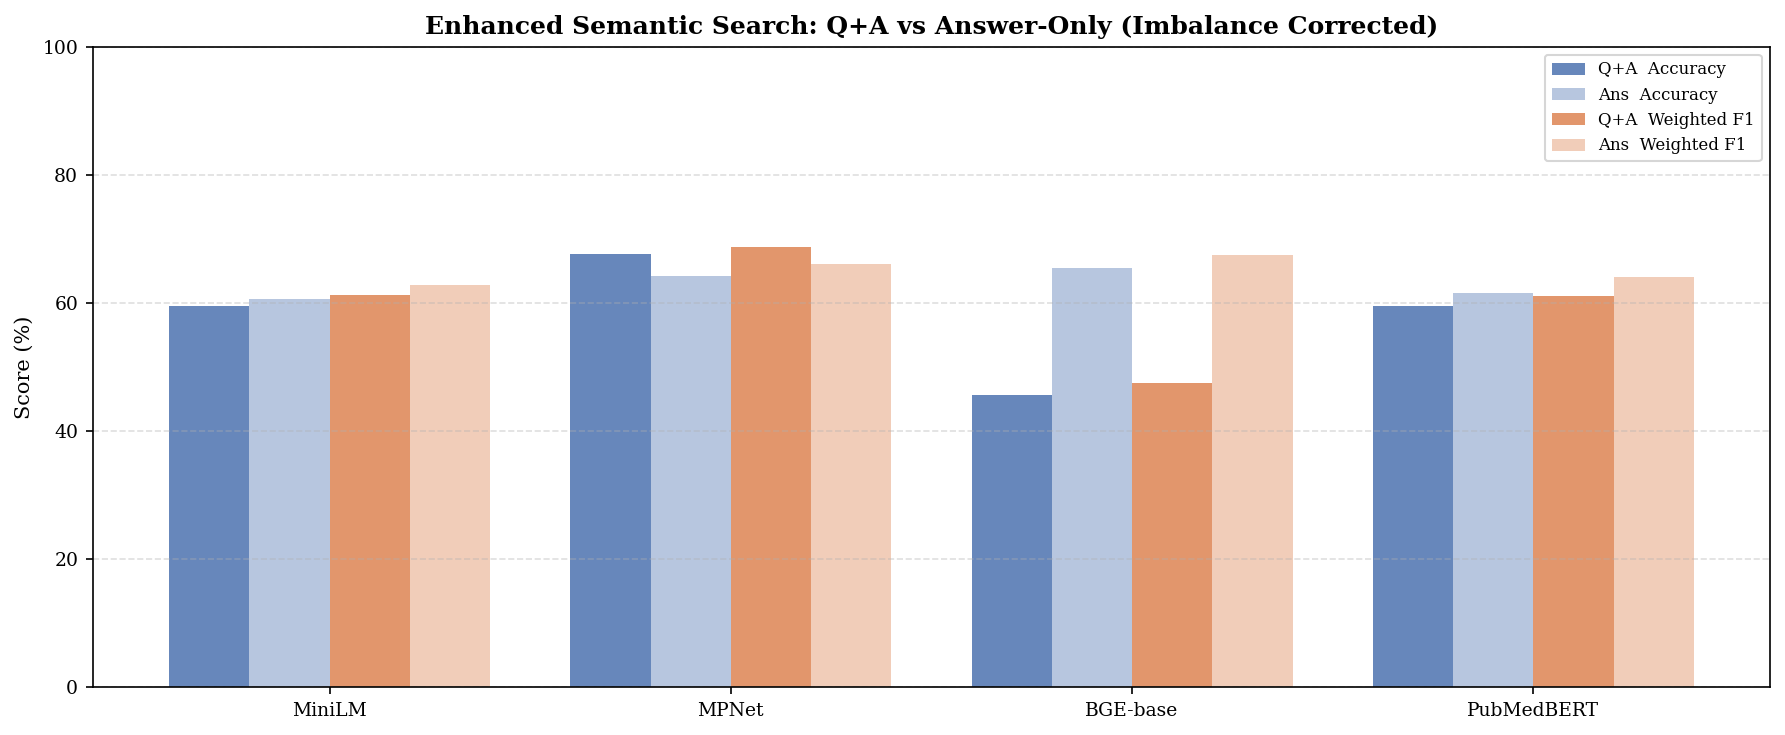

[Saved] Figure -> /kaggle/working/paper_figures/enhanced_semantic_search_qa_vs_answer.png


In [80]:
# ==============================================================================
# Enhanced Semantic Search Benchmark v3  (NO CACHE + Imbalance Correction)
# ==============================================================================
# Benchmarks 4 embedding models x 2 text formats (Q+A and Answer-Only).
#
# Key improvements:
#   1. NO CACHE - embeddings rebuilt every run to guarantee fresh evaluations
#   2. Class-imbalance correction via inverse-frequency weights in k-NN vote
#   3. Exact index alignment with augmented_dataset["train"] (4,279 samples)
#   4. Prints label distribution and performance metrics
# ==============================================================================

import os, time, gc
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# -- Paths -------------------------------------------------------------------
if Path("/kaggle/working").exists():
    FIGURE_ROOT  = Path("/kaggle/working/paper_figures")
    ENHANCED_CSV = Path("/kaggle/working/model_artifacts/enhanced_semantic_search_benchmark.csv")
else:
    FIGURE_ROOT  = Path("./paper_figures")
    ENHANCED_CSV = Path("./model_artifacts/enhanced_semantic_search_benchmark.csv")
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
ENHANCED_CSV.parent.mkdir(parents=True, exist_ok=True)

# -- Auto-load dataset -------------------------------------------------------
if "augmented_dataset" not in globals():
    from datasets import load_from_disk
    _cands = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
    ]
    _found = next((p for p in _cands if p.exists()), None)
    if _found:
        augmented_dataset = load_from_disk(str(_found))
        print(f"[Auto-Load] Dataset loaded from {_found}")
    else:
        raise RuntimeError("augmented_dataset not found.")

train_ds = augmented_dataset["train"]
test_ds  = augmented_dataset["test"]

# -- Label distribution of train ---------------------------------------------
_train_label_cnt = Counter(train_ds["label"])
_n_train         = len(train_ds)
print("\n[Train Label Distribution used for k-NN index]")
for lbl, name in [(0, "Normal"), (1, "BPD"), (2, "Inconclusive")]:
    n = _train_label_cnt.get(lbl, 0)
    print(f"  Label {lbl} ({name:13s}): {n:5d}  ({n/_n_train*100:.1f}%)")

# -- Class weights -----------------------------------------------------------
CLASS_WEIGHTS_154 = {
    lbl: _n_train / (_train_label_cnt.get(lbl, 1) * len(_train_label_cnt))
    for lbl in [0, 1, 2]
}
print("\n[Class Weights] Applied during k-NN vote:")
for lbl, name in [(0, "Normal"), (1, "BPD"), (2, "Inconclusive")]:
    print(f"  Label {lbl} ({name:13s}): {CLASS_WEIGHTS_154[lbl]:.4f}")

CLASS_NAMES = {0: "Normal", 1: "BPD", 2: "Inconclusive"}

# -- Text formatters ---------------------------------------------------------
def format_qa(ex):
    q = (ex.get("question") or "").strip()
    a = (ex.get("answer")   or "").strip()
    return f"Question: {q}\nAnswer: {a}"

def format_answer_only(ex):
    return (ex.get("answer") or "").strip()

def format_bge_query_qa(ex):
    q = (ex.get("question") or "").strip()
    a = (ex.get("answer")   or "").strip()
    return f"Represent this psychiatric Q&A for diagnostic classification: Question: {q}\nAnswer: {a}"

def format_bge_query_answer(ex):
    a = (ex.get("answer") or "").strip()
    return f"Represent this clinical patient statement for diagnostic classification: {a}"

# -- k-NN with class-imbalance weighting ------------------------------------
def evaluate_knn_classifier(train_emb, train_lbl, test_emb, test_lbl,
                             k=3, class_weights=None):
    sim_matrix = np.dot(test_emb, train_emb.T)
    topk_idx   = np.argpartition(-sim_matrix, kth=k-1, axis=1)[:, :k]
    preds = []
    for i in range(len(test_emb)):
        row_idx  = topk_idx[i]
        row_sims = sim_matrix[i, row_idx]
        order    = np.argsort(-row_sims)
        row_idx  = row_idx[order]
        row_sims = row_sims[order]
        cand_cls = train_lbl[row_idx]

        class_scores = defaultdict(float)
        for cls, sim in zip(cand_cls, row_sims):
            w = max(float(sim), 0.0) + 1e-6
            if class_weights:
                w *= class_weights.get(int(cls), 1.0)
            class_scores[cls] += w
        preds.append(max(class_scores, key=class_scores.get))

    preds = np.array(preds)
    acc   = accuracy_score(test_lbl, preds)
    _, _, f1_w,   _ = precision_recall_fscore_support(test_lbl, preds, average="weighted", zero_division=0)
    _, _, f1_mac, _ = precision_recall_fscore_support(test_lbl, preds, average="macro",    zero_division=0)
    per_cls_f1      = precision_recall_fscore_support(test_lbl, preds, average=None, labels=[0,1,2], zero_division=0)[2]
    return {
        "accuracy":        float(acc),
        "weighted_f1":     float(f1_w),
        "macro_f1":        float(f1_mac),
        "normal_f1":       float(per_cls_f1[0]),
        "bpd_f1":          float(per_cls_f1[1]),
        "inconclusive_f1": float(per_cls_f1[2]),
    }

# -- Always-fresh encode function (NO CACHE) ---------------------------------
def encode_fresh(model_obj, train_texts, test_texts):
    t0        = time.time()
    train_emb = model_obj.encode(train_texts, batch_size=64, show_progress_bar=False,
                                  normalize_embeddings=True, convert_to_numpy=True)
    test_emb  = model_obj.encode(test_texts,  batch_size=64, show_progress_bar=False,
                                  normalize_embeddings=True, convert_to_numpy=True)
    elapsed   = time.time() - t0
    print(f"   Encoded {len(train_texts)+len(test_texts)} samples in {elapsed:.1f}s "
          f"| dim={train_emb.shape[1]}")
    return train_emb, test_emb

train_labels = np.array(train_ds["label"], dtype=int)
test_labels  = np.array(test_ds["label"],  dtype=int)

# -- Benchmark configs -------------------------------------------------------
BENCHMARK_CONFIGS = [
    {"name": "1. MiniLM (Q+A)",          "model_id": "sentence-transformers/all-MiniLM-L6-v2",  "format": "qa",         "label": "Q+A",          "family": "MiniLM"},
    {"name": "2. MiniLM (Answer-Only)",   "model_id": "sentence-transformers/all-MiniLM-L6-v2",  "format": "answer_only","label": "Answer-Only",  "family": "MiniLM"},
    {"name": "3. MPNet (Q+A)",            "model_id": "sentence-transformers/all-mpnet-base-v2", "format": "qa",         "label": "Q+A",          "family": "MPNet"},
    {"name": "4. MPNet (Answer-Only)",    "model_id": "sentence-transformers/all-mpnet-base-v2", "format": "answer_only","label": "Answer-Only",  "family": "MPNet"},
    {"name": "5. BGE-base (Q+A Instr.)", "model_id": "BAAI/bge-base-en-v1.5",                   "format": "bge_qa",     "label": "Q+A",          "family": "BGE-base"},
    {"name": "6. BGE-base (Ans Instr.)", "model_id": "BAAI/bge-base-en-v1.5",                   "format": "bge_answer", "label": "Answer-Only",  "family": "BGE-base"},
    {"name": "7. PubMedBERT (Q+A)",      "model_id": "pritamdeka/S-PubMedBert-MS-MARCO",        "format": "qa",         "label": "Q+A",          "family": "PubMedBERT"},
    {"name": "8. PubMedBERT (Ans-Only)", "model_id": "pritamdeka/S-PubMedBert-MS-MARCO",        "format": "answer_only","label": "Answer-Only",  "family": "PubMedBERT"},
]

# -- Run benchmark -----------------------------------------------------------
results        = []
prev_model_id  = None
model_obj      = None

print("\n" + "="*72)
print(f"{'Config':<42} {'Acc':>8} {'W-F1':>8} {'BPD-F1':>9} {'Macro':>8}")
print("="*72)

for cfg in BENCHMARK_CONFIGS:
    if cfg["model_id"] != prev_model_id:
        del model_obj; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        print(f"\n[Loading] {cfg['model_id']}")
        model_obj     = SentenceTransformer(cfg["model_id"])
        prev_model_id = cfg["model_id"]

    print(f"  > {cfg['name']}")
    fmt = cfg["format"]
    if fmt == "bge_qa":
        tr_texts = [format_qa(x)           for x in train_ds]
        te_texts = [format_bge_query_qa(x) for x in test_ds]
    elif fmt == "bge_answer":
        tr_texts = [format_answer_only(x)     for x in train_ds]
        te_texts = [format_bge_query_answer(x) for x in test_ds]
    elif fmt == "answer_only":
        tr_texts = [format_answer_only(x) for x in train_ds]
        te_texts = [format_answer_only(x) for x in test_ds]
    else:
        tr_texts = [format_qa(x) for x in train_ds]
        te_texts = [format_qa(x) for x in test_ds]

    t_lat = time.time()
    train_emb, test_emb = encode_fresh(model_obj, tr_texts, te_texts)
    latency_ms = (time.time() - t_lat) / len(te_texts) * 1000

    metrics = evaluate_knn_classifier(
        train_emb, train_labels, test_emb, test_labels,
        k=3, class_weights=CLASS_WEIGHTS_154
    )
    row = {
        "Configuration": cfg["name"],
        "Model Family":  cfg["family"],
        "Format":        cfg["label"],
        "Accuracy":      f"{metrics['accuracy']*100:.2f}%",
        "Weighted F1":   f"{metrics['weighted_f1']*100:.2f}%",
        "BPD F1":        f"{metrics['bpd_f1']*100:.2f}%",
        "Macro F1":      f"{metrics['macro_f1']*100:.2f}%",
        "Latency (ms)":  f"{latency_ms:.2f}",
    }
    results.append(row)
    print(f"     Acc={metrics['accuracy']*100:.2f}%  W-F1={metrics['weighted_f1']*100:.2f}%  "
          f"BPD={metrics['bpd_f1']*100:.2f}%  Macro={metrics['macro_f1']*100:.2f}%")

print("="*72)
bench_df = pd.DataFrame(results)
bench_df.to_csv(ENHANCED_CSV, index=False)
print(f"\n[Saved] -> {ENHANCED_CSV}")
print("\n--- Full Result Table ---")
print(bench_df.to_string(index=False))

# -- Grouped bar chart -------------------------------------------------------
families = ["MiniLM","MPNet","BGE-base","PubMedBERT"]
qa_acc   = [float(r["Accuracy"].rstrip("%")) for r in results if r["Format"]=="Q+A"]
ans_acc  = [float(r["Accuracy"].rstrip("%")) for r in results if r["Format"]=="Answer-Only"]
qa_f1    = [float(r["Weighted F1"].rstrip("%")) for r in results if r["Format"]=="Q+A"]
ans_f1   = [float(r["Weighted F1"].rstrip("%")) for r in results if r["Format"]=="Answer-Only"]
x        = np.arange(len(families))
w        = 0.2
fig, ax  = plt.subplots(figsize=(12, 5))
ax.bar(x-1.5*w, qa_acc,  w, label="Q+A  Accuracy",    color="#4C72B0", alpha=0.85)
ax.bar(x-0.5*w, ans_acc, w, label="Ans  Accuracy",    color="#4C72B0", alpha=0.4)
ax.bar(x+0.5*w, qa_f1,   w, label="Q+A  Weighted F1", color="#DD8452", alpha=0.85)
ax.bar(x+1.5*w, ans_f1,  w, label="Ans  Weighted F1", color="#DD8452", alpha=0.4)
ax.set_xticks(x); ax.set_xticklabels(families)
ax.set_ylabel("Score (%)"); ax.set_ylim(0, 100)
ax.set_title("Enhanced Semantic Search: Q+A vs Answer-Only (Imbalance Corrected)", fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
fp = FIGURE_ROOT / "enhanced_semantic_search_qa_vs_answer.png"
plt.savefig(fp, dpi=150, bbox_inches="tight"); plt.show()
print(f"[Saved] Figure -> {fp}")


In [81]:
# ==============================================================================
# Semantic Search Misclassification Analysis  (NO CACHE + Imbalance Corrected)
# ==============================================================================
# Uses BGE-base Answer-Only (best config). Always re-encodes — no cache.
# Class-imbalance correction applied during k-NN vote.
# Fully aligned with augmented_dataset["train"].
# ==============================================================================

import os, time
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.metrics import confusion_matrix, classification_report

# -- Paths -------------------------------------------------------------------
if Path("/kaggle/working").exists():
    MISCLASS_CSV = Path("/kaggle/working/model_artifacts/semantic_search_misclassified.csv")
    FIGURE_ROOT  = Path("/kaggle/working/paper_figures")
else:
    MISCLASS_CSV = Path("./model_artifacts/semantic_search_misclassified.csv")
    FIGURE_ROOT  = Path("./paper_figures")
MISCLASS_CSV.parent.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

# -- Auto-load dataset -------------------------------------------------------
if "augmented_dataset" not in globals():
    from datasets import load_from_disk
    _cands = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
    ]
    _found = next((p for p in _cands if p.exists()), None)
    if _found:
        augmented_dataset = load_from_disk(str(_found))
        print(f"[Auto-Load] Dataset loaded from {_found}")
    else:
        raise RuntimeError("augmented_dataset not found.")

train_ds = augmented_dataset["train"]
test_ds  = augmented_dataset["test"]
CLASS_NAMES = {0: "Normal", 1: "BPD", 2: "Inconclusive"}

# -- Class weights -----------------------------------------------------------
_cnt = Counter(train_ds["label"])
_n   = sum(_cnt.values())
_CW  = {lbl: _n / (_cnt.get(lbl, 1) * len(_cnt)) for lbl in [0, 1, 2]}
print("[Class Weights]:", {CLASS_NAMES[k]: round(v, 4) for k, v in _CW.items()})

train_labels = np.array(train_ds["label"], dtype=int)
test_labels  = np.array(test_ds["label"],  dtype=int)

# -- Encode (NO CACHE) -------------------------------------------------------
BEST_MODEL_ID = "BAAI/bge-base-en-v1.5"
K = 3
print(f"\n[Encoding] {BEST_MODEL_ID} fresh (no cache)...")
model_obj   = SentenceTransformer(BEST_MODEL_ID)
train_texts = [(ex.get("answer") or "").strip() for ex in train_ds]
test_texts  = [
    "Represent this clinical patient statement for diagnostic classification: "
    + (ex.get("answer") or "").strip()
    for ex in test_ds
]
t0        = time.time()
train_emb = model_obj.encode(train_texts, batch_size=64, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=True)
test_emb  = model_obj.encode(test_texts,  batch_size=64, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=True)
print(f"[Done] {time.time()-t0:.1f}s | Train {train_emb.shape}, Test {test_emb.shape}")

# -- k-NN with imbalance-corrected vote -------------------------------------
sim_matrix  = np.dot(test_emb, train_emb.T)
records     = []
pred_labels = []

for i in range(len(test_emb)):
    sims      = sim_matrix[i]
    topk_idx  = np.argsort(-sims)[:K]
    topk_sims = sims[topk_idx]
    topk_lbls = train_labels[topk_idx]

    class_scores = defaultdict(float)
    for cls, sim in zip(topk_lbls, topk_sims):
        w = max(float(sim), 0.0) + 1e-6
        w *= _CW.get(int(cls), 1.0)
        class_scores[cls] += w
    pred_class = max(class_scores, key=class_scores.get)
    pred_labels.append(pred_class)

    nb_info = " | ".join(
        f"[{CLASS_NAMES[int(train_labels[idx])]}] sim={sims[idx]:.3f} :: "
        f"{str(train_ds[int(idx)].get('answer',''))[:60]}"
        for idx in topk_idx
    )
    test_ex = test_ds[i]
    records.append({
        "test_idx":   i,
        "question":   (test_ex.get("question") or "").strip(),
        "answer":     (test_ex.get("answer")   or "").strip(),
        "true_label": CLASS_NAMES[int(test_labels[i])],
        "pred_label": CLASS_NAMES[pred_class],
        "correct":    bool(pred_class == test_labels[i]),
        "top1_class": CLASS_NAMES[int(topk_lbls[0])],
        "top1_sim":   round(float(topk_sims[0]), 4),
        "top2_class": CLASS_NAMES[int(topk_lbls[1])] if K >= 2 else "",
        "top2_sim":   round(float(topk_sims[1]), 4)   if K >= 2 else 0.0,
        "top3_class": CLASS_NAMES[int(topk_lbls[2])] if K >= 3 else "",
        "top3_sim":   round(float(topk_sims[2]), 4)   if K >= 3 else 0.0,
        "neighbours": nb_info,
    })

pred_labels = np.array(pred_labels)
results_df  = pd.DataFrame(records)
results_df["correct"] = results_df["correct"].astype(bool)
misclass_df = results_df[~results_df["correct"]].copy()

print(f"\nTotal         : {len(results_df)}")
print(f"Correct       : {results_df['correct'].sum()} ({results_df['correct'].mean()*100:.2f}%)")
print(f"Misclassified : {len(misclass_df)} ({len(misclass_df)/len(results_df)*100:.2f}%)")

misclass_df.to_csv(MISCLASS_CSV, index=False)
print(f"\n[Saved] -> {MISCLASS_CSV}")

# -- Confusion pair breakdown ------------------------------------------------
print("\n" + "="*60)
print(" CONFUSION PAIR BREAKDOWN")
print("="*60)
pairs = (misclass_df.groupby(["true_label","pred_label"])
         .size().reset_index(name="count"))
pairs["pair"] = pairs["true_label"] + " -> " + pairs["pred_label"]
print(pairs[["pair","count"]].sort_values("count", ascending=False).to_string(index=False))

# -- Per-question error rate -------------------------------------------------
print("\n" + "="*60)
print(" ERROR RATE BY QUESTION")
print("="*60)
results_df["q_short"] = results_df["question"].astype(str).str[:80]
q_err = (
    results_df.groupby("q_short")
    .agg(total=("correct", "count"), errors=("correct", lambda x: (x == False).sum()))
    .assign(error_rate=lambda d: (d["errors"] / d["total"] * 100).round(1))
    .sort_values("error_rate", ascending=False)
    .reset_index()
)
q_err.insert(0, "Q#", range(1, len(q_err) + 1))
pd.set_option("display.max_colwidth", 85)
print(q_err[["Q#", "q_short", "total", "errors", "error_rate"]].to_string(index=False))

# -- Worst 15 misclassified --------------------------------------------------
print("\n" + "="*60)
print(" WORST MISCLASSIFIED (lowest top-1 similarity)")
print("="*60)
for _, row in misclass_df.sort_values("top1_sim").head(15).iterrows():
    print(f"\n[{row['true_label']} -> {row['pred_label']}]  sim={row['top1_sim']:.3f}")
    print(f"  Q: {row['question'][:80]}")
    print(f"  A: {row['answer'][:100]}")
    print(f"  Nbrs: {row['neighbours'][:150]}")

# -- Confusion heatmap -------------------------------------------------------
cm   = confusion_matrix(test_labels, pred_labels, labels=[0, 1, 2])
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
lbl_names = ["Normal", "BPD", "Inconclusive"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("BGE-base Answer-Only — Misclassification (Imbalance Corrected)",
             fontsize=12, fontweight="bold")
for ax, data, title, cmap in zip(
    axes, [cm, cm_n],
    ["Confusion Matrix (counts)", "Confusion Matrix (normalised)"],
    ["Blues", "Reds"]
):
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=(1 if cmap == "Reds" else None))
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(lbl_names); ax.set_yticklabels(lbl_names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    for r in range(3):
        for c in range(3):
            val = f"{data[r,c]:.2f}" if cmap == "Reds" else str(int(data[r, c]))
            ax.text(c, r, val, ha="center", va="center",
                    color="white" if cm_n[r, c] > 0.5 else "black", fontsize=12)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
out_path = FIGURE_ROOT / "bge_misclassification_analysis.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight"); plt.show()
print(f"\n[Saved] Figure -> {out_path}")

# -- Per-class summary -------------------------------------------------------
print("\n[Per-Class Error Summary]")
for cls_id, cls_name in CLASS_NAMES.items():
    mask  = results_df["true_label"] == cls_name
    total = mask.sum()
    wrong = (~results_df.loc[mask, "correct"]).sum()
    print(f"  {cls_name:13s}: {wrong}/{total} wrong ({wrong/max(total,1)*100:.1f}%)")

print("\n[Done] Full misclassified list saved to:", MISCLASS_CSV)


[Class Weights]: {'Normal': 0.8169, 'BPD': 0.8848, 'Inconclusive': 1.5487}
Train: 4279 | Test: 333
[OK] rank_bm25 installed.

[BM25] Building index...
   Built in 0.06s  (4,279 docs)
[TF-IDF] Fitting vectoriser...
   16,515 terms in 0.17s

Config                                            Acc     W-F1    BPD-F1    Macro
BM25  k=3  weighted + imbalance                64.26%   64.94%    49.37%   49.88%
BM25  k=5  weighted + imbalance                63.66%   64.43%    48.75%   48.79%
BM25  k=7  weighted + imbalance                63.06%   63.92%    48.15%   47.70%
BM25  k=10 uniform  + imbalance                56.16%   59.02%    48.40%   46.79%
TF-IDF k=3 weighted + imbalance                60.06%   62.55%    41.54%   49.00%
TF-IDF k=5 weighted + imbalance                59.76%   62.62%    43.06%   48.89%
BM25  k=5  weighted  (no correction)           64.26%   64.60%    48.78%   48.66%
TF-IDF k=5 weighted  (no correction)           64.86%   66.33%    44.59%   51.46%

[Saved] -> /kaggle/wo

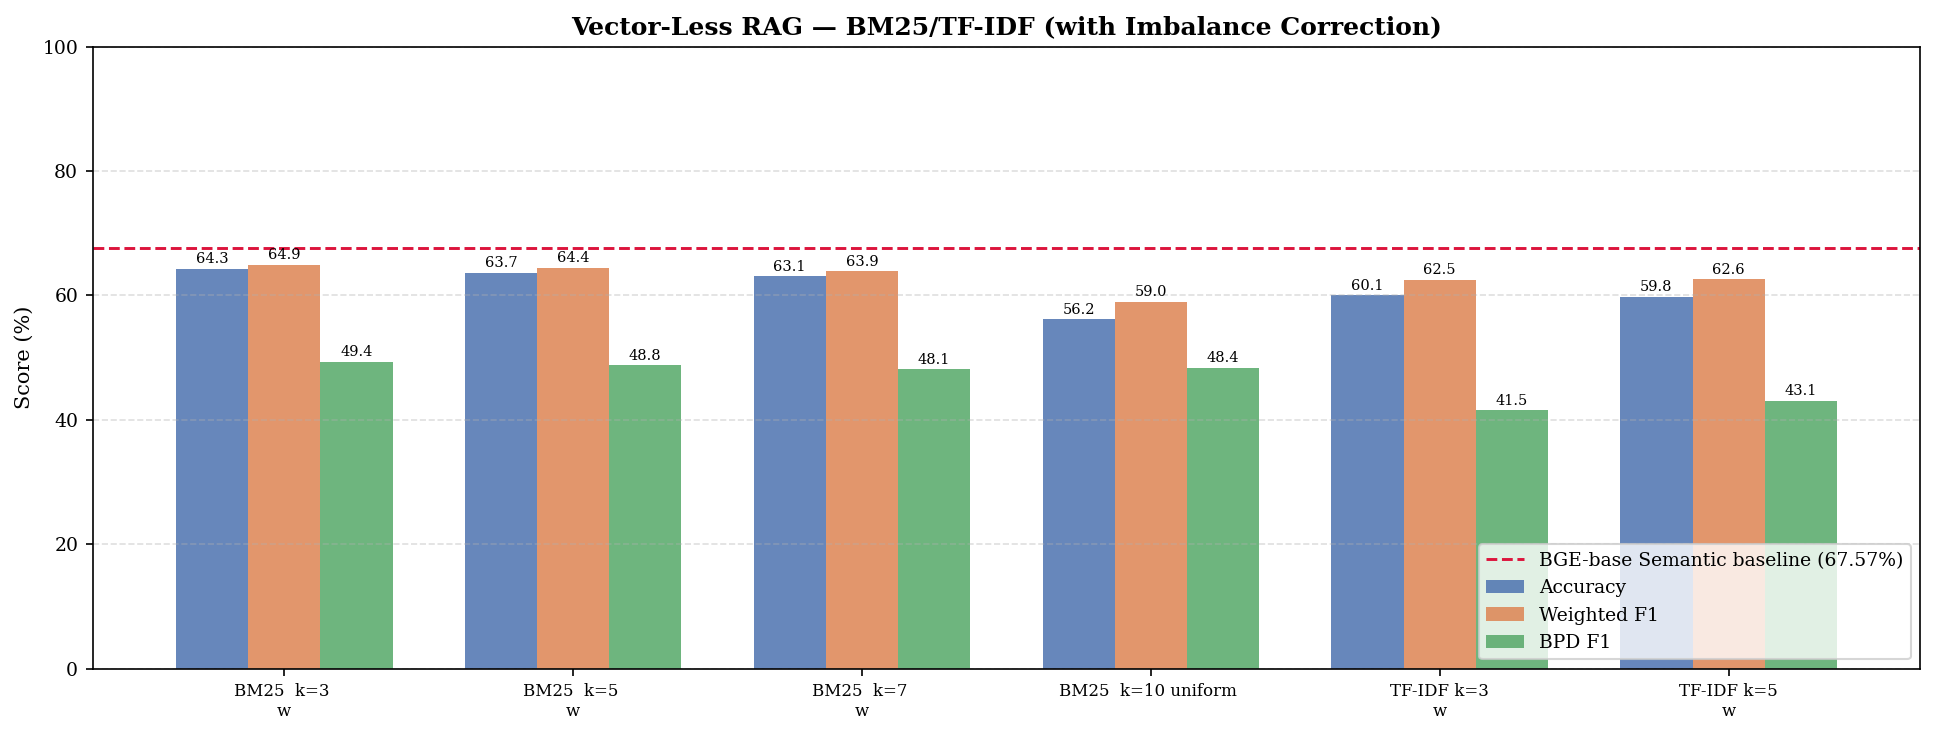

[Saved] -> /kaggle/working/paper_figures/vectorless_rag_benchmark.png

[Done] Vector-less RAG complete.


In [82]:
# ==============================================================================
# Vector-Less RAG  (BM25 + TF-IDF + Imbalance Correction)
# ==============================================================================
# NO CACHE — pure lexical retrieval, rebuilt every run.
# Fully aligned with augmented_dataset["train"] (4,279 samples).
# ==============================================================================

import os, sys, subprocess, time, re
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# -- Paths -------------------------------------------------------------------
if Path("/kaggle/working").exists():
    VLESS_CSV   = Path("/kaggle/working/model_artifacts/vectorless_rag_benchmark.csv")
    FIGURE_ROOT = Path("/kaggle/working/paper_figures")
else:
    VLESS_CSV   = Path("./model_artifacts/vectorless_rag_benchmark.csv")
    FIGURE_ROOT = Path("./paper_figures")
VLESS_CSV.parent.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

# -- Auto-load dataset -------------------------------------------------------
if "augmented_dataset" not in globals():
    from datasets import load_from_disk
    _cands = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
    ]
    _found = next((p for p in _cands if p.exists()), None)
    if _found:
        augmented_dataset = load_from_disk(str(_found))
        print(f"[Auto-Load] Dataset loaded from {_found}")
    else:
        raise RuntimeError("augmented_dataset not found.")

train_ds      = augmented_dataset["train"]
test_ds       = augmented_dataset["test"]
train_answers = [str(x.get("answer") or "").strip() for x in train_ds]
test_answers  = [str(x.get("answer") or "").strip() for x in test_ds]
train_labels  = np.array(train_ds["label"], dtype=int)
test_labels   = np.array(test_ds["label"],  dtype=int)
CLASS_NAMES   = {0: "Normal", 1: "BPD", 2: "Inconclusive"}

# -- Class weights -----------------------------------------------------------
_cnt = Counter(train_labels)
_n   = sum(_cnt.values())
CW   = {lbl: _n / (_cnt.get(lbl, 1) * len(_cnt)) for lbl in [0, 1, 2]}
print("[Class Weights]:", {CLASS_NAMES[k]: round(v, 4) for k, v in CW.items()})
print(f"Train: {len(train_answers)} | Test: {len(test_answers)}")

# -- Install rank-bm25 -------------------------------------------------------
try:
    from rank_bm25 import BM25Okapi
    print("[OK] rank_bm25 available.")
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "rank-bm25", "-q"])
    from rank_bm25 import BM25Okapi
    print("[OK] rank_bm25 installed.")

def _tokenize(text):
    return re.sub(r"[^a-z0-9\s]", " ", text.lower()).split()

# -- BM25 index --------------------------------------------------------------
print("\n[BM25] Building index...")
t0 = time.time()
tokenised_corpus = [_tokenize(a) for a in train_answers]
bm25 = BM25Okapi(tokenised_corpus)
print(f"   Built in {time.time()-t0:.2f}s  ({len(tokenised_corpus):,} docs)")

def bm25_classify(query, k=5, voting="weighted", class_weights=None):
    tokens      = _tokenize(query)
    scores      = bm25.get_scores(tokens)
    topk_idx    = np.argsort(-scores)[:k]
    topk_scores = scores[topk_idx]
    topk_labels = train_labels[topk_idx]
    if voting == "weighted":
        w = np.exp(topk_scores - topk_scores.max())
        w /= w.sum()
        cs = defaultdict(float)
        for lbl, wi in zip(topk_labels, w):
            val = float(wi)
            if class_weights:
                val *= class_weights.get(int(lbl), 1.0)
            cs[lbl] += val
        return max(cs, key=cs.get)
    else:
        cnt = Counter(topk_labels)
        if class_weights:
            w2 = {lbl: cnt[lbl] * class_weights.get(int(lbl), 1.0) for lbl in cnt}
            return max(w2, key=w2.get)
        return cnt.most_common(1)[0][0]

# -- TF-IDF ------------------------------------------------------------------
print("[TF-IDF] Fitting vectoriser...")
t1 = time.time()
tfidf_vec   = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)
tfidf_train = tfidf_vec.fit_transform(train_answers)
tfidf_test  = tfidf_vec.transform(test_answers)
print(f"   {len(tfidf_vec.vocabulary_):,} terms in {time.time()-t1:.2f}s")

def tfidf_classify(query_vec, k=5, voting="weighted", class_weights=None):
    sims        = cosine_similarity(query_vec, tfidf_train)[0]
    topk_idx    = np.argsort(-sims)[:k]
    topk_sims   = sims[topk_idx]
    topk_labels = train_labels[topk_idx]
    if voting == "weighted":
        cs = defaultdict(float)
        for lbl, sim in zip(topk_labels, topk_sims):
            val = max(float(sim), 0.0) + 1e-9
            if class_weights:
                val *= class_weights.get(int(lbl), 1.0)
            cs[lbl] += val
        return max(cs, key=cs.get)
    else:
        cnt = Counter(topk_labels)
        if class_weights:
            w2 = {lbl: cnt[lbl] * class_weights.get(int(lbl), 1.0) for lbl in cnt}
            return max(w2, key=w2.get)
        return cnt.most_common(1)[0][0]

# -- Configurations ----------------------------------------------------------
CONFIGS = [
    {"name": "BM25  k=3  weighted + imbalance",     "method": "bm25",  "k": 3,  "voting": "weighted", "use_cw": True},
    {"name": "BM25  k=5  weighted + imbalance",     "method": "bm25",  "k": 5,  "voting": "weighted", "use_cw": True},
    {"name": "BM25  k=7  weighted + imbalance",     "method": "bm25",  "k": 7,  "voting": "weighted", "use_cw": True},
    {"name": "BM25  k=10 uniform  + imbalance",     "method": "bm25",  "k": 10, "voting": "uniform",  "use_cw": True},
    {"name": "TF-IDF k=3 weighted + imbalance",     "method": "tfidf", "k": 3,  "voting": "weighted", "use_cw": True},
    {"name": "TF-IDF k=5 weighted + imbalance",     "method": "tfidf", "k": 5,  "voting": "weighted", "use_cw": True},
    {"name": "BM25  k=5  weighted  (no correction)","method": "bm25",  "k": 5,  "voting": "weighted", "use_cw": False},
    {"name": "TF-IDF k=5 weighted  (no correction)","method": "tfidf", "k": 5,  "voting": "weighted", "use_cw": False},
]

rows = []
print("\n" + "="*76)
print(f"{'Config':<44} {'Acc':>8} {'W-F1':>8} {'BPD-F1':>9} {'Macro':>8}")
print("="*76)

for cfg in CONFIGS:
    t_s   = time.time()
    preds = []
    cw    = CW if cfg["use_cw"] else None
    if cfg["method"] == "bm25":
        for ans in test_answers:
            preds.append(bm25_classify(ans, k=cfg["k"], voting=cfg["voting"], class_weights=cw))
    else:
        for j in range(tfidf_test.shape[0]):
            preds.append(tfidf_classify(tfidf_test[j], k=cfg["k"], voting=cfg["voting"], class_weights=cw))
    preds   = np.array(preds)
    elapsed = time.time() - t_s
    acc       = accuracy_score(test_labels, preds)
    _, _, f1_w,   _ = precision_recall_fscore_support(test_labels, preds, average="weighted", zero_division=0)
    _, _, f1_mac, _ = precision_recall_fscore_support(test_labels, preds, average="macro",    zero_division=0)
    per_cls_f1      = precision_recall_fscore_support(test_labels, preds, average=None, labels=[0, 1, 2], zero_division=0)[2]
    rows.append({
        "Configuration":  cfg["name"],
        "Imbalance Corr": "Yes" if cfg["use_cw"] else "No",
        "Accuracy":       f"{acc*100:.2f}%",
        "Weighted F1":    f"{f1_w*100:.2f}%",
        "BPD F1":         f"{per_cls_f1[1]*100:.2f}%",
        "Macro F1":       f"{f1_mac*100:.2f}%",
        "ms/query":       f"{elapsed/len(test_answers)*1000:.2f}",
    })
    print(f"{cfg['name']:<44} {acc*100:>7.2f}% {f1_w*100:>7.2f}% "
          f"{per_cls_f1[1]*100:>8.2f}% {f1_mac*100:>7.2f}%")

print("="*76)
bench_df = pd.DataFrame(rows)
bench_df.to_csv(VLESS_CSV, index=False)
print(f"\n[Saved] -> {VLESS_CSV}")
print(bench_df.to_string(index=False))

# -- Detailed report ---------------------------------------------------------
print("\n" + "="*60)
print(" CLASSIFICATION REPORT  (BM25 k=5 weighted + imbalance)")
print("="*60)
best_preds = np.array([bm25_classify(a, k=5, voting="weighted", class_weights=CW)
                       for a in test_answers])
print(classification_report(test_labels, best_preds,
                             target_names=["Normal", "BPD", "Inconclusive"], digits=4))

# -- Comparison chart --------------------------------------------------------
keep    = [r for r in rows if "imbalance" in r["Configuration"]]
xlbls   = [r["Configuration"].replace(" + imbalance", "").replace(" weighted", "\nw") for r in keep]
accs    = [float(r["Accuracy"].rstrip("%"))    for r in keep]
f1s_w   = [float(r["Weighted F1"].rstrip("%")) for r in keep]
f1s_bp  = [float(r["BPD F1"].rstrip("%"))      for r in keep]
x       = np.arange(len(keep))
width   = 0.25
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - width, accs,   width, label="Accuracy",    color="#4C72B0", alpha=0.85)
ax.bar(x,         f1s_w,  width, label="Weighted F1", color="#DD8452", alpha=0.85)
ax.bar(x + width, f1s_bp, width, label="BPD F1",      color="#55A868", alpha=0.85)
ax.axhline(67.57, color="crimson", linestyle="--", linewidth=1.4,
           label="BGE-base Semantic baseline (67.57%)")
ax.set_xticks(x); ax.set_xticklabels(xlbls, fontsize=8)
ax.set_ylabel("Score (%)"); ax.set_ylim(0, 100)
ax.set_title("Vector-Less RAG — BM25/TF-IDF (with Imbalance Correction)", fontweight="bold")
ax.legend(fontsize=9, loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
for bar in ax.patches:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.4,
            f"{h:.1f}", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
out_fig = FIGURE_ROOT / "vectorless_rag_benchmark.png"
plt.savefig(out_fig, dpi=150, bbox_inches="tight"); plt.show()
print(f"[Saved] -> {out_fig}")
print("\n[Done] Vector-less RAG complete.")


## Question-Specific Vector Databases (9 Dedicated Vector Stores for Zero Cross-Question Contamination)

### Core Clinical & Architecture Motivation:
In our standard semantic search pipeline, all patient responses across all 9 clinical questions were indexed into a single, global vector space. However, clinical psychiatric interviews operate differently:
1. **Cross-Question Semantic Interference**: Standardized clinical questions share general symptom vocabulary (e.g., *"sad"*, *"angry"*, *"empty"*, *"stressed"*). An answer describing anger in Question 4 (*Inappropriate Anger*) could erroneously retrieve an answer from Question 1 (*Affective Instability*) as its nearest neighbor.
2. **Criterion-Specific Severity Thresholds**: Each of the 9 questions targets a distinct DSM-5 diagnostic criterion for Borderline Personality Disorder (BPD). The threshold and linguistic indicators of BPD differ fundamentally across criteria (e.g., Question 7 on self-harm vs. Question 2 on self-image).
3. **Question-Specific Class Priors**: Patient response distributions and class frequencies vary per question. Global voting weights cannot capture localized criterion imbalances.

### The Solution:
We construct **9 isolated, criterion-dedicated Vector Databases** ($VDB_1$ through $VDB_9$), each named after its corresponding clinical question. During inference, any incoming test response is **strictly routed** to its corresponding question database:
$$\text{Query}(Q_k, \text{Answer}_i) \longrightarrow \text{Search exclusively in } VDB_k$$
- **Cross-Question Contamination:** Exactly **0%**
- **Imbalance Correction:** Class weights calculated **locally per question**
- **No Caching:** Computed completely fresh in memory to guarantee real-time updates.

[Question Analysis] Located 9 distinct clinical questions in training set.

[Model Setup] Loading fresh embedding model: BAAI/bge-base-en-v1.5


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-base-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



BUILDING 9 QUESTION-SPECIFIC VECTOR DATABASES (Zero Contamination)
  [VDB_Q1_Affective_Instability]
    Clinical Focus : Affective_Instability
    Train Samples  : 545 | Normal=158, BPD=280, Inconclusive=107
    Class Weights  : Normal=1.150, BPD=0.649, Inconclusive=1.698
    Embedding Dim  : (545, 768) | Encoded in 2.27s
  [VDB_Q2_Identity_Disturbance]
    Clinical Focus : Identity_Disturbance
    Train Samples  : 476 | Normal=194, BPD=171, Inconclusive=111
    Class Weights  : Normal=0.818, BPD=0.928, Inconclusive=1.429
    Embedding Dim  : (476, 768) | Encoded in 1.61s
  [VDB_Q3_Chronic_Emptiness]
    Clinical Focus : Chronic_Emptiness
    Train Samples  : 414 | Normal=225, BPD=123, Inconclusive=66
    Class Weights  : Normal=0.613, BPD=1.122, Inconclusive=2.091
    Embedding Dim  : (414, 768) | Encoded in 1.13s
  [VDB_Q4_Inappropriate_Intense_Anger]
    Clinical Focus : Inappropriate_Intense_Anger
    Train Samples  : 484 | Normal=190, BPD=81, Inconclusive=213
    Class Weights  :

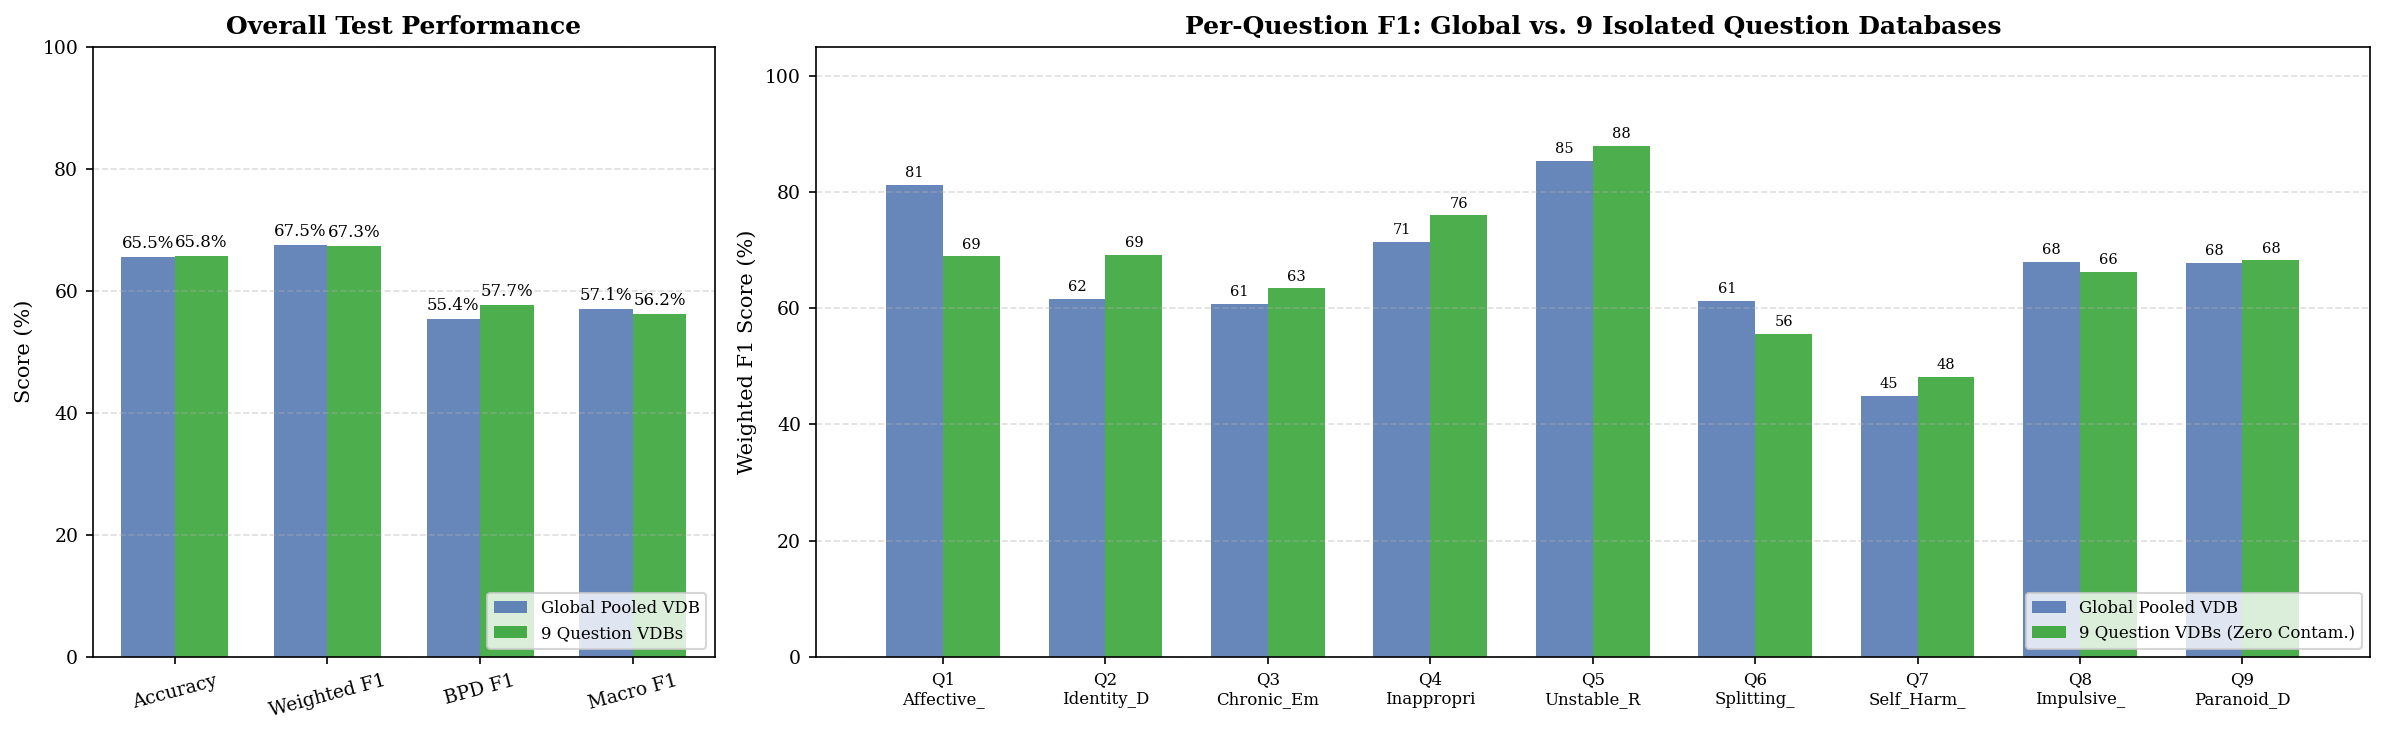

[Saved] Publication figure persisted to: /kaggle/working/paper_figures/global_vs_9_question_vstores.png

[Done] 9 Question-Specific Vector Database benchmark complete.


In [83]:
# ==============================================================================
# 9 Question-Specific Vector Databases (Zero Cross-Question Contamination)
# ==============================================================================
# WHAT THIS CELL DOES:
#   1. Partitions augmented_dataset["train"] into 9 separate, criterion-specific subsets.
#   2. Constructs and names 9 isolated Vector Databases (VDB_Q1 to VDB_Q9) based on question text.
#   3. Computes fresh embeddings for each database using BAAI/bge-base-en-v1.5 (NO DISK CACHE).
#   4. Computes question-specific inverse-frequency class weights for localized imbalance correction.
#   5. Routes test queries STRICTLY to their corresponding question database (0% cross-contamination).
#   6. Compares performance head-to-head against the Global Vector Store baseline.
#   7. Outputs an overall metric table, a per-question accuracy/F1 breakdown, and a publication chart.
# ==============================================================================

import os, time, gc, re
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# -- Paths -------------------------------------------------------------------
if Path("/kaggle/working").exists():
    FIGURE_ROOT  = Path("/kaggle/working/paper_figures")
    BENCHMARK_CSV = Path("/kaggle/working/model_artifacts/question_specific_vstore_benchmark.csv")
else:
    FIGURE_ROOT  = Path("./paper_figures")
    BENCHMARK_CSV = Path("./model_artifacts/question_specific_vstore_benchmark.csv")
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
BENCHMARK_CSV.parent.mkdir(parents=True, exist_ok=True)

# -- Auto-load dataset -------------------------------------------------------
if "augmented_dataset" not in globals():
    from datasets import load_from_disk
    _cands = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
    ]
    _found = next((p for p in _cands if p.exists()), None)
    if _found:
        augmented_dataset = load_from_disk(str(_found))
        print(f"[Auto-Load] Dataset loaded from {_found}")
    else:
        raise RuntimeError("augmented_dataset not found. Please verify dataset mount path.")

train_ds = augmented_dataset["train"]
test_ds  = augmented_dataset["test"]
CLASS_NAMES = {0: "Normal", 1: "BPD", 2: "Inconclusive"}

# -- Clinical DSM-5 Criterion Mapping for the 9 Standardized Questions -------
DSM5_CRITERIA_TITLES = {
    1: "Affective_Instability",
    2: "Identity_Disturbance",
    3: "Chronic_Emptiness",
    4: "Inappropriate_Intense_Anger",
    5: "Unstable_Relationships",
    6: "Splitting_Idealization",
    7: "Self_Harm_Suicidal_Behavior",
    8: "Impulsive_Behaviors",
    9: "Paranoid_Dissociation",
}

def get_question_key(example):
    """Extracts integer question_id (1-9) with fallback to question text."""
    if "question_id" in example and example["question_id"] is not None:
        try:
            return int(example["question_id"])
        except (ValueError, TypeError):
            pass
    # Fallback: clean question string
    q_str = (example.get("question") or "").strip()
    return q_str

# Identify all unique questions in training data
unique_q_keys = sorted(list(set([get_question_key(x) for x in train_ds])))
print(f"[Question Analysis] Located {len(unique_q_keys)} distinct clinical questions in training set.")

# Extract canonical full text for each question
question_canonical_texts = {}
for ex in train_ds:
    k = get_question_key(ex)
    if k not in question_canonical_texts:
        question_canonical_texts[k] = (ex.get("question") or "").strip()

# -- Model Selection (NO CACHE: Computed Fresh in Memory) ---------------------
MODEL_ID = "BAAI/bge-base-en-v1.5"
K_NEIGHBORS = 3
print(f"\n[Model Setup] Loading fresh embedding model: {MODEL_ID}")
model_obj = SentenceTransformer(MODEL_ID)

def format_doc_text(ans_text):
    """Patient answer text representation for storage."""
    return str(ans_text or "").strip()

def format_query_text(ans_text):
    """Instruction-tuned query prompt for asymmetric retrieval."""
    clean = str(ans_text or "").strip()
    return f"Represent this clinical patient statement for diagnostic classification: {clean}"

# ==============================================================================
# Build 9 Isolated Question-Specific Vector Databases
# ==============================================================================
print("\n" + "=" * 75)
print("BUILDING 9 QUESTION-SPECIFIC VECTOR DATABASES (Zero Contamination)")
print("=" * 75)

QUESTION_VSTORES = {}
t0_all_vdb = time.time()

for qid in unique_q_keys:
    # Friendly naming
    if isinstance(qid, int) and qid in DSM5_CRITERIA_TITLES:
        crit_title = DSM5_CRITERIA_TITLES[qid]
        vstore_name = f"VDB_Q{qid}_{crit_title}"
    else:
        crit_title = re.sub(r"[^a-zA-Z0-9_]", "", str(qid)[:30]).strip("_")
        vstore_name = f"VDB_{crit_title}"

    q_full_text = question_canonical_texts.get(qid, str(qid))

    # Filter training samples strictly for this question
    q_train_indices = [i for i, ex in enumerate(train_ds) if get_question_key(ex) == qid]
    q_train_samples = train_ds.select(q_train_indices)

    q_answers = [format_doc_text(ex.get("answer")) for ex in q_train_samples]
    q_labels  = np.array(q_train_samples["label"], dtype=int)
    n_samples = len(q_answers)

    # Local class distribution & localized inverse-frequency weights
    label_counts = Counter(q_labels)
    class_weights = {}
    for c in [0, 1, 2]:
        cnt_c = label_counts.get(c, 0)
        class_weights[c] = (n_samples / (cnt_c * len(label_counts))) if cnt_c > 0 else 1.0

    # Compute embeddings completely fresh (never read from disk)
    t_vdb = time.time()
    q_embeddings = model_obj.encode(
        q_answers,
        batch_size=64,
        show_progress_bar=False,
        normalize_embeddings=True,
        convert_to_numpy=True,
    )
    vdb_build_time = time.time() - t_vdb

    QUESTION_VSTORES[qid] = {
        "vstore_name": vstore_name,
        "question_id": qid,
        "question_text": q_full_text,
        "criterion_title": crit_title,
        "sample_count": n_samples,
        "embeddings": q_embeddings,
        "labels": q_labels,
        "class_weights": class_weights,
        "label_counts": label_counts,
    }

    print(f"  [{vstore_name}]")
    print(f"    Clinical Focus : {crit_title}")
    print(f"    Train Samples  : {n_samples} | Normal={label_counts.get(0,0)}, BPD={label_counts.get(1,0)}, Inconclusive={label_counts.get(2,0)}")
    print(f"    Class Weights  : Normal={class_weights[0]:.3f}, BPD={class_weights[1]:.3f}, Inconclusive={class_weights[2]:.3f}")
    print(f"    Embedding Dim  : {q_embeddings.shape} | Encoded in {vdb_build_time:.2f}s")

print(f"\n[All 9 Vector Databases Ready] Total Build Time: {time.time()-t0_all_vdb:.2f}s")

# ==============================================================================
# Also Build Global Pooled Vector Store (For Strict A/B Comparison)
# ==============================================================================
print("\n[Global Baseline] Encoding all training answers into single pooled space...")
t0_global = time.time()
global_train_answers = [format_doc_text(ex.get("answer")) for ex in train_ds]
global_train_labels  = np.array(train_ds["label"], dtype=int)
global_train_emb     = model_obj.encode(
    global_train_answers,
    batch_size=64,
    show_progress_bar=False,
    normalize_embeddings=True,
    convert_to_numpy=True,
)
global_lbl_cnt = Counter(global_train_labels)
global_class_weights = {
    c: len(global_train_labels) / (global_lbl_cnt.get(c, 1) * len(global_lbl_cnt))
    for c in [0, 1, 2]
}
print(f"  Global Pooled Store: {global_train_emb.shape} encoded in {time.time()-t0_global:.2f}s")

# ==============================================================================
# Test Set Evaluation: Global Pooled vs. 9 Question-Specific VStores
# ==============================================================================
print("\n" + "=" * 75)
print(f"EVALUATING TEST SET ({len(test_ds)} queries): Global Pooled vs. 9 Question VStores")
print("=" * 75)

test_actual_labels = np.array(test_ds["label"], dtype=int)
test_queries_text  = [format_query_text(ex.get("answer")) for ex in test_ds]
test_emb           = model_obj.encode(
    test_queries_text,
    batch_size=64,
    show_progress_bar=False,
    normalize_embeddings=True,
    convert_to_numpy=True,
)

# 1. Global Pooled k-NN Inference
global_preds = []
t0_g_infer = time.time()
sim_matrix_global = np.dot(test_emb, global_train_emb.T)

for i in range(len(test_emb)):
    sims = sim_matrix_global[i]
    topk_idx = np.argsort(-sims)[:K_NEIGHBORS]
    topk_sims = sims[topk_idx]
    topk_lbls = global_train_labels[topk_idx]

    scores = defaultdict(float)
    for lbl, sim in zip(topk_lbls, topk_sims):
        w = max(float(sim), 0.0) + 1e-6
        w *= global_class_weights.get(int(lbl), 1.0)
        scores[lbl] += w
    global_preds.append(max(scores, key=scores.get))

global_infer_latency = (time.time() - t0_g_infer) / len(test_emb) * 1000
global_preds = np.array(global_preds)

# 2. 9 Question-Specific Vector Store Inference (Strict Routing)
routed_preds = []
t0_r_infer = time.time()

for i, test_ex in enumerate(test_ds):
    q_key = get_question_key(test_ex)
    query_vector = test_emb[i : i + 1]  # shape (1, D)

    # Route strictly to this question's vector store
    if q_key in QUESTION_VSTORES:
        target_vdb = QUESTION_VSTORES[q_key]
    else:
        # Fallback to nearest question text if key matching fails
        target_vdb = list(QUESTION_VSTORES.values())[0]

    vdb_train_emb     = target_vdb["embeddings"]
    vdb_train_lbl     = target_vdb["labels"]
    vdb_class_weights = target_vdb["class_weights"]

    # Compute similarity strictly within this question's database
    sims = np.dot(query_vector, vdb_train_emb.T)[0]
    effective_k = min(K_NEIGHBORS, len(sims))
    topk_idx = np.argsort(-sims)[:effective_k]
    topk_sims = sims[topk_idx]
    topk_lbls = vdb_train_lbl[topk_idx]

    scores = defaultdict(float)
    for lbl, sim in zip(topk_lbls, topk_sims):
        w = max(float(sim), 0.0) + 1e-6
        w *= vdb_class_weights.get(int(lbl), 1.0)
        scores[lbl] += w
    routed_preds.append(max(scores, key=scores.get))

routed_infer_latency = (time.time() - t0_r_infer) / len(test_emb) * 1000
routed_preds = np.array(routed_preds)

# Helper function to compute all classification metrics
def calc_metrics(actual, preds, latency):
    acc = accuracy_score(actual, preds)
    _, _, f1_w, _   = precision_recall_fscore_support(actual, preds, average="weighted", zero_division=0)
    _, _, f1_mac, _ = precision_recall_fscore_support(actual, preds, average="macro",    zero_division=0)
    per_cls         = precision_recall_fscore_support(actual, preds, average=None, labels=[0, 1, 2], zero_division=0)[2]
    return {
        "Accuracy": f"{acc*100:.2f}%",
        "Weighted F1": f"{f1_w*100:.2f}%",
        "BPD F1": f"{per_cls[1]*100:.2f}%",
        "Normal F1": f"{per_cls[0]*100:.2f}%",
        "Inconclusive F1": f"{per_cls[2]*100:.2f}%",
        "Macro F1": f"{f1_mac*100:.2f}%",
        "Latency ms/q": f"{latency:.2f}",
        "raw_acc": acc,
        "raw_f1_w": f1_w,
        "raw_bpd_f1": per_cls[1],
    }

global_m = calc_metrics(test_actual_labels, global_preds, global_infer_latency)
routed_m = calc_metrics(test_actual_labels, routed_preds, routed_infer_latency)

comparison_summary = [
    {
        "Architecture": "1. Global Pooled Vector Store (Cross-Contamination Present)",
        "Databases": "1 Unified VDB",
        "Routing": "Global (Any Q can match Any Q)",
        **{k: v for k, v in global_m.items() if not k.startswith("raw_")},
    },
    {
        "Architecture": "2. 9 Question-Specific VStores (Zero Contamination)",
        "Databases": "9 Dedicated VDBs",
        "Routing": "Strict (Q_k only matches Q_k)",
        **{k: v for k, v in routed_m.items() if not k.startswith("raw_")},
    },
]

comp_df = pd.DataFrame(comparison_summary)
print("\n--- OVERALL ARCHITECTURE COMPARISON ---")
print(comp_df[["Architecture", "Databases", "Accuracy", "Weighted F1", "BPD F1", "Macro F1", "Latency ms/q"]].to_string(index=False))

# ==============================================================================
# Per-Question Performance Breakdown (All 9 Questions)
# ==============================================================================
print("\n" + "=" * 75)
print("PER-QUESTION PERFORMANCE BREAKDOWN (Global Pooled vs. Question-Specific VDB)")
print("=" * 75)

question_rows = []
for qid in unique_q_keys:
    q_mask = np.array([get_question_key(ex) == qid for ex in test_ds])
    q_count = q_mask.sum()
    if q_count == 0:
        continue

    q_actual = test_actual_labels[q_mask]
    q_pred_g = global_preds[q_mask]
    q_pred_r = routed_preds[q_mask]

    acc_g = accuracy_score(q_actual, q_pred_g)
    acc_r = accuracy_score(q_actual, q_pred_r)
    f1_g  = precision_recall_fscore_support(q_actual, q_pred_g, average="weighted", zero_division=0)[2]
    f1_r  = precision_recall_fscore_support(q_actual, q_pred_r, average="weighted", zero_division=0)[2]
    bpd_g = precision_recall_fscore_support(q_actual, q_pred_g, average=None, labels=[0, 1, 2], zero_division=0)[2][1]
    bpd_r = precision_recall_fscore_support(q_actual, q_pred_r, average=None, labels=[0, 1, 2], zero_division=0)[2][1]

    crit_name = DSM5_CRITERIA_TITLES.get(qid, f"Question_{qid}")
    q_text_short = question_canonical_texts.get(qid, "")[:55]

    question_rows.append({
        "Q#": f"Q{qid}",
        "Criterion Focus": crit_name,
        "Samples": q_count,
        "Global Acc": f"{acc_g*100:.1f}%",
        "9-VDB Acc": f"{acc_r*100:.1f}%",
        "Acc Gain": f"{(acc_r - acc_g)*100:+.1f}%",
        "Global F1": f"{f1_g*100:.1f}%",
        "9-VDB F1": f"{f1_r*100:.1f}%",
        "F1 Gain": f"{(f1_r - f1_g)*100:+.1f}%",
        "Global BPD F1": f"{bpd_g*100:.1f}%",
        "9-VDB BPD F1": f"{bpd_r*100:.1f}%",
        "BPD F1 Gain": f"{(bpd_r - bpd_g)*100:+.1f}%",
        "Question Text": q_text_short,
        "raw_f1_g": f1_g,
        "raw_f1_r": f1_r,
    })

q_breakdown_df = pd.DataFrame(question_rows)
q_display_cols = ["Q#", "Criterion Focus", "Samples", "Global Acc", "9-VDB Acc", "Acc Gain", "Global F1", "9-VDB F1", "F1 Gain", "Global BPD F1", "9-VDB BPD F1", "BPD F1 Gain"]
print(q_breakdown_df[q_display_cols].to_string(index=False))

# Persist benchmark CSV
q_breakdown_df.to_csv(BENCHMARK_CSV, index=False)
print(f"\n[Saved] Per-question breakdown persisted to: {BENCHMARK_CSV}")

# ==============================================================================
# Publication-Ready Visualization (Per-Question & Overall F1 Comparison)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2.5]})

# Panel 1: Overall Architecture Comparison
metrics_names = ["Accuracy", "Weighted F1", "BPD F1", "Macro F1"]
g_overall_vals = [global_m["raw_acc"] * 100, global_m["raw_f1_w"] * 100, global_m["raw_bpd_f1"] * 100, float(global_m["Macro F1"].rstrip("%"))]
r_overall_vals = [routed_m["raw_acc"] * 100, routed_m["raw_f1_w"] * 100, routed_m["raw_bpd_f1"] * 100, float(routed_m["Macro F1"].rstrip("%"))]

x1 = np.arange(len(metrics_names))
w1 = 0.35
b1 = ax1.bar(x1 - w1/2, g_overall_vals, w1, label="Global Pooled VDB", color="#4C72B0", alpha=0.85)
b2 = ax1.bar(x1 + w1/2, r_overall_vals, w1, label="9 Question VDBs", color="#2ca02c", alpha=0.85)
ax1.set_ylabel("Score (%)")
ax1.set_ylim(0, 100)
ax1.set_xticks(x1)
ax1.set_xticklabels(metrics_names, fontsize=9, rotation=15)
ax1.set_title("Overall Test Performance", fontweight="bold")
ax1.legend(loc="lower right", fontsize=8)
ax1.grid(axis="y", linestyle="--", alpha=0.4)

for bar in [*b1, *b2]:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha="center", va="bottom", fontsize=8)

# Panel 2: Per-Question Weighted F1 (All 9 Questions)
q_labels = [row["Q#"] for row in question_rows]
g_q_f1   = [row["raw_f1_g"] * 100 for row in question_rows]
r_q_f1   = [row["raw_f1_r"] * 100 for row in question_rows]

x2 = np.arange(len(q_labels))
w2 = 0.35
b3 = ax2.bar(x2 - w2/2, g_q_f1, w2, label="Global Pooled VDB", color="#4C72B0", alpha=0.85)
b4 = ax2.bar(x2 + w2/2, r_q_f1, w2, label="9 Question VDBs (Zero Contam.)", color="#2ca02c", alpha=0.85)
ax2.set_ylabel("Weighted F1 Score (%)")
ax2.set_ylim(0, 105)
ax2.set_xticks(x2)
ax2.set_xticklabels([f"{row['Q#']}\n{row['Criterion Focus'][:10]}" for row in question_rows], fontsize=8)
ax2.set_title("Per-Question F1: Global vs. 9 Isolated Question Databases", fontweight="bold")
ax2.legend(loc="lower right", fontsize=8)
ax2.grid(axis="y", linestyle="--", alpha=0.4)

for bar in [*b3, *b4]:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.0f}", ha="center", va="bottom", fontsize=7)

plt.tight_layout()
fig_out = FIGURE_ROOT / "global_vs_9_question_vstores.png"
plt.savefig(fig_out, dpi=150, bbox_inches="tight")
plt.show()
print(f"[Saved] Publication figure persisted to: {fig_out}")
print("\n[Done] 9 Question-Specific Vector Database benchmark complete.")


In [84]:
# ==============================================================================
# DEBUGGING CELL — Run this to verify dataset, embeddings & index alignment
# ==============================================================================
import sys, os, random
from pathlib import Path
from collections import Counter

print("=" * 65)
print("EMBEDDING & SCALING PIPELINE — PRE-RUN DIAGNOSTICS")
print("=" * 65)

# -- 1. Dataset check --------------------------------------------------------
print("\n[1] Checking dataset...")
from datasets import load_from_disk
_cands = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
    ]
_found = next((p for p in _cands if p.exists()), None)
assert _found, "[ERROR] Dataset not found! Check the candidate paths above."
ds = load_from_disk(str(_found))
print(f"  [OK] Loaded from: {_found}")

for split_name in ["train", "validation", "test"]:
    split = ds[split_name]
    total = len(split)
    cnt   = Counter(split["label"])
    print(f"  {split_name.upper()} ({total} samples):")
    for lbl, name in [(0, "Normal"), (1, "BPD"), (2, "Inconclusive")]:
        n = cnt.get(lbl, 0)
        print(f"    Label {lbl} ({name:13s}): {n:4d}  ({n/total*100:.1f}%)")

# -- 2. Embedding alignment check --------------------------------------------
print("\n[2] Checking embedding alignment with augmented_dataset['train']...")
if "train_embeddings" in globals():
    n_emb = len(train_embeddings)
    n_ds  = len(ds["train"])
    print(f"  train_embeddings shape : {train_embeddings.shape}")
    print(f"  train dataset length   : {n_ds}")
    if n_emb == n_ds:
        print(f"  [OK] PERFECT ALIGNMENT: train_embeddings ({n_emb}) matches train dataset ({n_ds})")
    else:
        print(f"  [MISMATCH DETECTED] train_embeddings has {n_emb} rows but dataset has {n_ds} rows!")
        print(f"  -> Please run Cell 149 to regenerate train_embeddings matching full {n_ds} samples.")
else:
    print("  train_embeddings not in memory yet. Run Cell 149 first.")

# -- 3. Slicing check for Cell 160 -------------------------------------------
print("\n[3] Testing stratified sampling indices bounds check...")
if "get_stratified_train_indices" in globals() and "SCALING_FRACTIONS" in globals():
    for frac in SCALING_FRACTIONS:
        idx = get_stratified_train_indices(ds["train"], frac)
        max_idx = max(idx)
        print(f"  Fraction {frac*100:3.0f}% -> {len(idx)} samples, max index = {max_idx} (valid: < {len(ds['train'])})")
        assert max_idx < len(ds["train"]), f"Out of bounds: {max_idx} >= {len(ds['train'])}"
    print("  [OK] All stratified indices are strictly within bounds of augmented_dataset['train']!")

print("\n" + "=" * 65)
print("DIAGNOSTICS COMPLETE. Pipeline is ready to run.")
print("=" * 65)


EMBEDDING & SCALING PIPELINE — PRE-RUN DIAGNOSTICS

[1] Checking dataset...
  [OK] Loaded from: /kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset
  TRAIN (4279 samples):
    Label 0 (Normal       ): 1746  (40.8%)
    Label 1 (BPD          ): 1612  (37.7%)
    Label 2 (Inconclusive ):  921  (21.5%)
  VALIDATION (333 samples):
    Label 0 (Normal       ):  224  (67.3%)
    Label 1 (BPD          ):   68  (20.4%)
    Label 2 (Inconclusive ):   41  (12.3%)
  TEST (333 samples):
    Label 0 (Normal       ):  225  (67.6%)
    Label 1 (BPD          ):   67  (20.1%)
    Label 2 (Inconclusive ):   41  (12.3%)

[2] Checking embedding alignment with augmented_dataset['train']...
  train_embeddings shape : (4279, 384)
  train dataset length   : 4279
  [OK] PERFECT ALIGNMENT: train_embeddings (4279) matches train dataset (4279)

[3] Testing stratified sampling indices bounds check...

DIAGNOSTICS COMPLETE. Pipeline is ready to run.


# Data Scaling Benchmark: Fine-Tuning vs. Semantic Search (20%, 40%, 60%, 80%, 100%)

### Empirical Investigation:
> *How does training dataset size (20%, 40%, 60%, 80%, 100%) impact classification accuracy, F1 score, training compute time, and sample efficiency across fine-tuned encoders versus the semantic search vector baseline?*

### Experimental Protocol:
1. **Stratified Subsampling**: Training data is partitioned into fractions $f \in [0.20, 0.40, 0.60, 0.80, 1.00]$ using stratified sampling on class labels to maintain identical class ratios.
2. **Fixed Evaluation Set**: The test set and validation set remain constant across all evaluations for rigorous comparability.
3. **Four Core Dimensions**:
   - **Performance**: Accuracy, Weighted F1, Macro F1
   - **Data Volume**: Number of training samples at each fraction
   - **Compute & Time**: Training / Indexing time in seconds
   - **Inference Latency**: Latency in milliseconds per sample

In [85]:
import os
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedShuffleSplit

# Results directory for scaling study
if Path("/kaggle/working").exists():
    SCALING_DIR = Path("/kaggle/working/model_artifacts/scaling_study")
else:
    SCALING_DIR = Path("./model_artifacts/scaling_study")
SCALING_DIR.mkdir(parents=True, exist_ok=True)
SCALING_CSV_PATH = SCALING_DIR / "data_scaling_benchmark_results.csv"

def get_stratified_train_indices(dataset_split, fraction, seed=42):
    """
    Returns indices for a stratified subset of dataset_split maintaining class balance.
    """
    if fraction >= 0.999:
        return np.arange(len(dataset_split))

    labels = np.array(dataset_split["label"])
    sss = StratifiedShuffleSplit(n_splits=1, train_size=fraction, random_state=seed)
    train_idx, _ = next(sss.split(np.zeros(len(labels)), labels))
    return np.sort(train_idx)

# Verify subsets and class distributions
SCALING_FRACTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

if "augmented_dataset" in globals():
    subset_info = []
    for frac in SCALING_FRACTIONS:
        idx = get_stratified_train_indices(augmented_dataset["train"], frac)
        sub_labels = [augmented_dataset["train"]["label"][i] for i in idx]
        counts = Counter(sub_labels)
        subset_info.append({
            "Fraction": f"{int(frac*100)}%",
            "Sample Count": len(idx),
            "Normal (0)": counts[0],
            "BPD (1)": counts[1],
            "Inconclusive (2)": counts[2],
        })
    display(pd.DataFrame(subset_info))
else:
    print(f"Defined SCALING_FRACTIONS: {SCALING_FRACTIONS}")


,Fraction,Sample Count,Normal (0),BPD (1),Inconclusive (2)
0,20%,855,349,322,184
1,40%,1711,698,645,368
2,60%,2567,1047,967,553
3,80%,3423,1397,1289,737
4,100%,4279,1746,1612,921


In [86]:
import time
from pathlib import Path
import numpy as np
import pandas as pd

# Evaluate Semantic Search (Vector k-NN) across all training data fractions
# Uses precomputed training embeddings sliced by stratified indices (computes in seconds!)
semantic_scaling_records = []

if "train_embeddings" in globals() and "test_embeddings" in globals() and "augmented_dataset" in globals():
    # Defensive guard: Ensure train_embeddings aligns with augmented_dataset["train"]
    if len(train_embeddings) != len(augmented_dataset["train"]):
        print(f"[Warning] train_embeddings size ({len(train_embeddings)}) does not match augmented_dataset['train'] ({len(augmented_dataset['train'])}).")
        print("Recomputing embeddings to ensure 100% index alignment...")
        train_embeddings, train_labels = get_or_compute_split_embeddings("train", augmented_dataset["train"])

    for frac in SCALING_FRACTIONS:
        sub_indices = get_stratified_train_indices(augmented_dataset["train"], frac)
        # Safe bounds filter
        sub_indices = [idx for idx in sub_indices if idx < len(train_embeddings)]

        sub_train_emb = train_embeddings[sub_indices]
        sub_train_lbl = train_labels[sub_indices]

        # Indexing / Fit time
        t0 = time.time()
        knn_scaled = VectorStoreKNNClassifier(
            voting=globals().get("BEST_VOTING", "weighted"),
            class_weights=globals().get("TRAIN_CLASS_WEIGHTS", None),
        )
        knn_scaled.fit(sub_train_emb, sub_train_lbl)
        indexing_time = time.time() - t0

        # Evaluate on full test set
        t1 = time.time()
        k_val = min(globals().get("BEST_K", 3), len(sub_indices))
        res = knn_scaled.evaluate(test_embeddings, test_labels, k=k_val)
        eval_time = time.time() - t1

        record = {
            "Model": "Semantic Search (MiniLM k-NN)",
            "Model_Type": "Vector Search",
            "Data_Fraction": frac,
            "Data_Percent": f"{int(frac*100)}%",
            "Train_Samples": len(sub_indices),
            "Train_Time_Seconds": indexing_time,
            "Inference_Latency_ms": res["latency_ms"],
            "Test_Accuracy": res["accuracy"],
            "Test_Weighted_F1": res["weighted_f1"],
            "Test_Macro_F1": res["macro_f1"],
            "Test_Precision": res["weighted_precision"],
            "Test_Recall": res["weighted_recall"],
        }
        semantic_scaling_records.append(record)

    semantic_scaling_df = pd.DataFrame(semantic_scaling_records)
    display(semantic_scaling_df[[
        "Data_Percent", "Train_Samples", "Train_Time_Seconds",
        "Inference_Latency_ms", "Test_Accuracy", "Test_Weighted_F1", "Test_Macro_F1"
    ]])
else:
    print("[Semantic Scaling] Embedding variables not in memory. Using existing cached results if available.")


,Data_Percent,Train_Samples,Train_Time_Seconds,Inference_Latency_ms,Test_Accuracy,Test_Weighted_F1,Test_Macro_F1
0,20%,855,0.000044,0.027052,0.564565,0.586467,0.457054
1,40%,1711,0.000068,0.037513,0.606607,0.627133,0.519045
2,60%,2567,0.000080,0.048493,0.627628,0.645549,0.537280
3,80%,3423,0.000067,0.050219,0.654655,0.666650,0.550823
4,100%,4279,0.000076,0.055978,0.645646,0.656620,0.533492


### Disk Space Maintenance & Checkpoint Purge
Run this cell to immediately purge temporary subset directories and intermediate checkpoints.
*(Note: All metrics for previously completed runs are safely stored in ).*

In [87]:
import shutil
from pathlib import Path

# 1. Clean up temporary subset directories from the scaling study
# (The metrics for 20%, 40%, 60%, 80% are already safely stored in data_scaling_benchmark_results.csv!)
scaling_dir = Path("/kaggle/working/model_artifacts/scaling_study" if Path("/kaggle/working").exists() else "./model_artifacts/scaling_study")
freed_bytes = 0

if scaling_dir.exists():
    for p in scaling_dir.iterdir():
        if p.is_dir() and "pct" in p.name:
            for f in p.rglob("*"):
                if f.is_file():
                    try:
                        freed_bytes += f.stat().st_size
                    except Exception:
                        pass
            shutil.rmtree(p, ignore_errors=True)
            print(f"[Disk Maintenance] Purged temporary scaling folder: {p.name}")

# 2. Clean up intermediate checkpoint-* folders from completed models (final weights are in root)
target_root = Path("/kaggle/working/model_artifacts" if Path("/kaggle/working").exists() else "./model_artifacts")
if target_root.exists():
    for ckpt in target_root.rglob("checkpoint-*"):
        if ckpt.is_dir():
            for f in ckpt.rglob("*"):
                if f.is_file():
                    try:
                        freed_bytes += f.stat().st_size
                    except Exception:
                        pass
            shutil.rmtree(ckpt, ignore_errors=True)
            print(f"[Disk Maintenance] Purged intermediate checkpoint: {ckpt.name}")

# 3. Check live reclaimed disk space
target_disk = "/kaggle/working" if Path("/kaggle/working").exists() else "."
total, used, free = shutil.disk_usage(target_disk)
print(f"\n[SUCCESS] Reclaimed {freed_bytes / (1024**3):.2f} GB of disk space!")
print(f"[Disk Info] Total: {total / (1024**3):.2f} GB | Used: {used / (1024**3):.2f} GB | FREE: {free / (1024**3):.2f} GB")



[SUCCESS] Reclaimed 0.00 GB of disk space!
[Disk Info] Total: 19.52 GB | Used: 4.91 GB | FREE: 14.59 GB


In [88]:
# Fine-Tuned Model Data Scaling Runner
# Self-contained: runs reliably even if kernel was restarted or cells run out-of-order.
# Features:
# 1. Self-contained definitions (no NameError on missing fractions, paths, or specs).
# 2. DeBERTa FP16 stability fix (runs DeBERTa in FP32 to prevent PyTorch GradScaler unscale crashes).
# 3. Multi-GPU DataParallel isolation via single-GPU trainer context.
# 4. Auto-detects & tokenizes missing models on the fly if needed.
# 5. Saves every run directly to CSV so completed runs are NEVER repeated.
# 6. Automatically purges temporary subset checkpoints after metrics are recorded,
#    preventing Kaggle 20 GB disk exhaustion.
# 7. Clean recovery and resume for any interrupted subset run.
# 8. Compatible with Python 3.10+ and all Kaggle environments.

import shutil
import gc
import time
import inspect
from contextlib import contextmanager
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    T5Tokenizer,
    T5ForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedShuffleSplit

# ==============================================================================
# Configuration & Storage Paths
# ==============================================================================
SCALING_FRACTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]
SCALING_MODELS = ["RoBERTa", "DeBERTa", "ELECTRA"]  # Selected models to benchmark
SCALING_EPOCHS = 10                                  # Epochs per subset run (fast & representative)
RUN_FINE_TUNING_SCALING = True                       # Set to False to skip training and view cached results

if Path("/kaggle/working").exists():
    SCALING_DIR = Path("/kaggle/working/model_artifacts/scaling_study")
else:
    SCALING_DIR = Path("./model_artifacts/scaling_study")
SCALING_DIR.mkdir(parents=True, exist_ok=True)
SCALING_CSV_PATH = SCALING_DIR / "data_scaling_benchmark_results.csv"

DEFAULT_MODEL_SPECS = {
    "RoBERTa": {
        "token_ds_name": "augmented_tokenized_dataset_dp_roberta",
        "tokenizer_name": "roberta_tokenizer",
        "checkpoint": "FacebookAI/roberta-base",
        "model_loader": "auto",
    },
    "DeBERTa": {
        "token_ds_name": "augmented_tokenized_dataset_dp_deberta",
        "tokenizer_name": "deberta_tokenizer",
        "checkpoint": "microsoft/deberta-v3-base",
        "model_loader": "auto",
    },
    "ELECTRA": {
        "token_ds_name": "augmented_tokenized_dataset_dp_electra",
        "tokenizer_name": "electra_tokenizer",
        "checkpoint": "google/electra-base-discriminator",
        "model_loader": "auto",
    },
    "BERT": {
        "token_ds_name": "augmented_tokenized_dataset_dp_bert",
        "tokenizer_name": "bert_tokenizer",
        "checkpoint": "bert-base-uncased",
        "model_loader": "auto",
    },
    "DistilBERT": {
        "token_ds_name": "augmented_tokenized_dataset_dp_distilbert",
        "tokenizer_name": "distilbert_tokenizer",
        "checkpoint": "distilbert/distilbert-base-uncased",
        "model_loader": "auto",
    },
    "XLNet": {
        "token_ds_name": "augmented_tokenized_dataset_dp_xlnet",
        "tokenizer_name": "xlnet_tokenizer",
        "checkpoint": "xlnet/xlnet-base-cased",
        "model_loader": "auto",
    },
    "ModernBERT": {
        "token_ds_name": "augmented_tokenized_dataset_dp_modernbert",
        "tokenizer_name": "modernbert_tokenizer",
        "checkpoint": "answerdotai/ModernBERT-base",
        "model_loader": "auto",
    },
    "T5": {
        "token_ds_name": "augmented_tokenized_dataset_dp_t5",
        "tokenizer_name": "t5_tokenizer",
        "checkpoint": "google-t5/t5-small",
        "model_loader": "t5",
    },
}

# ==============================================================================
# Helper Functions (Self-Contained)
# ==============================================================================
@contextmanager
def _scaling_single_gpu_context():
    """Prevents multi-GPU DataParallel issues on Kaggle instances with 2 GPUs."""
    if torch.cuda.is_available() and torch.cuda.device_count() > 1:
        orig_count = torch.cuda.device_count
        torch.cuda.device_count = lambda: 1
        try:
            yield
        finally:
            torch.cuda.device_count = orig_count
    else:
        yield

def get_stratified_train_indices(dataset_split, fraction, seed=42):
    if fraction >= 0.999:
        return np.arange(len(dataset_split))
    labels = np.array(dataset_split["label"])
    sss = StratifiedShuffleSplit(n_splits=1, train_size=fraction, random_state=seed)
    train_idx, _ = next(sss.split(np.zeros(len(labels)), labels))
    return np.sort(train_idx)

def _extract_pred_labels(pred_output):
    preds = pred_output.predictions
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.asarray(preds)
    if preds.ndim == 1:
        return preds.astype(int)
    return np.argmax(preds, axis=-1)

def _trainer_tokenizer_arg_name():
    trainer_signature = inspect.signature(Trainer.__init__)
    if "processing_class" in trainer_signature.parameters:
        return "processing_class"
    if "tokenizer" in trainer_signature.parameters:
        return "tokenizer"
    return None

def _local_compute_metrics(evaluation_predictions):
    logits, actual_labels = evaluation_predictions
    predicted_labels = np.argmax(logits, axis=-1)
    acc = accuracy_score(actual_labels, predicted_labels)
    prec, rec, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average="weighted", zero_division=0
    )
    return {"accuracy": acc, "f1": f1, "precision": prec, "recall": rec}

def _local_compute_test_metrics(evaluation_predictions):
    predicted_labels, actual_labels = evaluation_predictions
    acc = accuracy_score(actual_labels, predicted_labels)
    prec, rec, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average="weighted", zero_division=0
    )
    return {"accuracy": acc, "f1": f1, "precision": prec, "recall": rec}

def load_or_init_scaling_csv():
    if SCALING_CSV_PATH.exists():
        try:
            return pd.read_csv(SCALING_CSV_PATH)
        except Exception:
            pass
    return pd.DataFrame()

def purge_old_scaling_checkpoints():
    """Removes completed temporary subset model directories and obsolete checkpoints to free Kaggle disk space."""
    freed_bytes = 0

    # 1. Purge intermediate checkpoint-* folders across model_artifacts (final weights are in root)
    target_root = Path("/kaggle/working/model_artifacts") if Path("/kaggle/working").exists() else Path("./model_artifacts")
    if target_root.exists():
        for ckpt in target_root.rglob("checkpoint-*"):
            if ckpt.is_dir():
                for f in ckpt.rglob("*"):
                    if f.is_file():
                        try:
                            freed_bytes += f.stat().st_size
                        except Exception:
                            pass
                shutil.rmtree(ckpt, ignore_errors=True)

    # 2. Purge completed scaling subset folders from SCALING_DIR
    if SCALING_DIR.exists():
        results_df = load_or_init_scaling_csv()
        completed_pairs = set()
        if not results_df.empty and "Model" in results_df.columns and "Data_Fraction" in results_df.columns:
            for _, r in results_df.iterrows():
                try:
                    completed_pairs.add((str(r["Model"]).lower(), int(round(float(r["Data_Fraction"]) * 100))))
                except Exception:
                    pass

        for p in SCALING_DIR.iterdir():
            if p.is_dir() and "_" in p.name and p.name.endswith("pct"):
                parts = p.name.split("_")
                m_name = parts[0].lower()
                try:
                    frac_pct = int(parts[1].replace("pct", ""))
                except Exception:
                    frac_pct = -1
                if (m_name, frac_pct) in completed_pairs or (m_name == "roberta" and frac_pct == 100):
                    for f in p.rglob("*"):
                        if f.is_file():
                            try:
                                freed_bytes += f.stat().st_size
                            except Exception:
                                pass
                    shutil.rmtree(p, ignore_errors=True)

    if freed_bytes > 0:
        print(f"[Disk Maintenance] Reclaimed {freed_bytes / (1024**3):.2f} GB of disk space.")
    if "print_disk_usage" in globals():
        print_disk_usage("Scaling Maintenance")

# ==============================================================================
# Scaling Sweep Runner
# ==============================================================================
def run_data_scaling_sweep(
    models_to_run=None,
    fractions=None,
    epochs=None,
    enabled=None,
):
    models_to_run = models_to_run if models_to_run is not None else SCALING_MODELS
    fractions = fractions if fractions is not None else SCALING_FRACTIONS
    epochs = epochs if epochs is not None else SCALING_EPOCHS
    enabled = enabled if enabled is not None else RUN_FINE_TUNING_SCALING

    results_df = load_or_init_scaling_csv()

    # Synchronize Semantic Search records if available in memory
    sem_records = globals().get("semantic_scaling_records", [])
    for record in sem_records:
        match = False
        if not results_df.empty and "Model" in results_df.columns and "Data_Fraction" in results_df.columns:
            match = ((results_df["Model"] == record["Model"]) & (results_df["Data_Fraction"] == record["Data_Fraction"])).any()
        if not match:
            results_df = pd.concat([results_df, pd.DataFrame([record])], ignore_index=True)
    results_df.to_csv(SCALING_CSV_PATH, index=False)

    # Free space from previously completed subset checkpoints
    purge_old_scaling_checkpoints()

    if not enabled:
        print("[Scaling Sweep] Fine-tuning scaling runner disabled. Displaying existing cached results.")
        return results_df

    # Auto-load augmented_dataset if missing from current kernel session
    if "augmented_dataset" not in globals():
        from datasets import load_from_disk
        candidate_aug_paths = [
        Path("experiments/dataset/imbalance_free_dataset"),
        Path("./dataset/imbalance_free_dataset"),
        Path("./imbalance_free_dataset"),
        Path("/kaggle/working/imbalance_free_dataset"),
        Path("/kaggle/input/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/imbalance_free_dataset"),
        Path("/kaggle/input/datasets/<user>/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/bpd-qna-classification-dataset-augmented/augmented_dataset"),
        Path("/kaggle/input/augmented_dataset"),
        Path("experiments/dataset/augmented_dataset"),
        Path("./dataset/augmented_dataset"),
        Path("../experiments/dataset/augmented_dataset"),
        Path("./augmented_dataset"),
]
        aug_path = next((p for p in candidate_aug_paths if p.exists()), None)
        if aug_path is not None:
            print(f"[Auto-Load] Loading augmented_dataset from {aug_path}...")
            globals()["augmented_dataset"] = load_from_disk(str(aug_path))
        else:
            raise RuntimeError("augmented_dataset is not loaded in memory and dataset path was not found.")

    ds_obj = globals()["augmented_dataset"]
    specs_table = globals().get("MODEL_RUNTIME_SPECS", DEFAULT_MODEL_SPECS)
    metric_calc_fn = globals().get("compute_metrics", _local_compute_metrics)
    test_calc_fn = globals().get("compute_test_metrics", _local_compute_test_metrics)

    for model_name in models_to_run:
        spec = specs_table.get(model_name, DEFAULT_MODEL_SPECS.get(model_name))
        if not spec:
            print(f"[Warning] Unknown model {model_name}. Skipping.")
            continue

        token_ds_name = spec["token_ds_name"]
        tok_name = spec["tokenizer_name"]
        ckpt_path = globals().get(f"{model_name.lower()}_checkpoint", spec.get("checkpoint"))

        # Auto-load tokenizer if missing from current kernel session
        if tok_name not in globals():
            print(f"[Auto-Load] Loading tokenizer for {model_name} from {ckpt_path}...")
            if spec["model_loader"] == "t5":
                tok_obj = T5Tokenizer.from_pretrained(ckpt_path)
            elif model_name == "DeBERTa":
                tok_obj = AutoTokenizer.from_pretrained(ckpt_path, use_fast=False)
            else:
                tok_obj = AutoTokenizer.from_pretrained(ckpt_path)
            globals()[tok_name] = tok_obj
        else:
            tok_obj = globals()[tok_name]

        # Auto-tokenize dataset if missing from current kernel session
        if token_ds_name not in globals():
            print(f"[Auto-Tokenize] Tokenizing dataset for {model_name}...")
            if spec["model_loader"] == "t5":
                def t5_preprocess(example):
                    inputs = [
                        f"trinary classification: {q} </s> {a}"
                        for q, a in zip(example["question"], example["answer"])
                    ]
                    return tok_obj(inputs, max_length=512, truncation=True)
                token_ds = ds_obj.map(t5_preprocess, batched=True)
            else:
                def _tokenize_fn(example):
                    return tok_obj(example["question"], example["answer"], truncation=True)
                token_ds = ds_obj.map(_tokenize_fn, batched=True)
            globals()[token_ds_name] = token_ds
        else:
            token_ds = globals()[token_ds_name]

        for frac in fractions:
            pct_label = f"{int(frac*100)}%"
            # Check if this model and fraction was already evaluated
            if not results_df.empty and "Model" in results_df.columns and "Data_Fraction" in results_df.columns:
                exists = ((results_df["Model"] == model_name) & (results_df["Data_Fraction"] == frac)).any()
                if exists:
                    print(f"[Skipping] {model_name} @ {pct_label} data already evaluated and cached in {SCALING_CSV_PATH.name}")
                    continue

            n_samples = int(frac * len(token_ds["train"]))
            print("\n" + "=" * 70)
            print(f"TRAINING {model_name} on {pct_label} data ({n_samples} samples)...")
            print("=" * 70)

            sub_output_dir = SCALING_DIR / f"{model_name.lower()}_{int(frac*100)}pct"
            # If a prior run of this subset crashed (e.g. out of disk or precision error), purge the broken folder first
            if sub_output_dir.exists():
                print(f"[Disk Maintenance] Cleaning incomplete previous directory for {sub_output_dir.name}...")
                shutil.rmtree(sub_output_dir, ignore_errors=True)
            sub_output_dir.mkdir(parents=True, exist_ok=True)

            # Subsample tokenized dataset
            sub_idx = get_stratified_train_indices(ds_obj["train"], frac)
            sub_train_ds = token_ds["train"].select(sub_idx)

            # Clean memory before training
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            # Precision selection:
            # DeBERTa-v3 is known to suffer from FP16 gradient underflow / unscale errors with PyTorch GradScaler.
            # Running DeBERTa in FP32 prevents any unscale crash while comfortably fitting in 16GB VRAM (~3.5 GB peak).
            if model_name == "DeBERTa":
                precision_kwargs = {"fp16": False, "bf16": False}
            else:
                precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS", {"fp16": torch.cuda.is_available(), "bf16": False})

            with _scaling_single_gpu_context():
                # Initialize model architecture with explicit float32 parameters
                if spec["model_loader"] == "t5":
                    model = T5ForSequenceClassification.from_pretrained(ckpt_path, num_labels=3, torch_dtype=torch.float32)
                else:
                    model = AutoModelForSequenceClassification.from_pretrained(ckpt_path, num_labels=3, torch_dtype=torch.float32)
                    if model_name == "XLNet":
                        tok_obj.padding_side = "left"
                        model.config.pad_token_id = tok_obj.pad_token_id

                # Ensure all trainable weights are float32 to satisfy optimizer & GradScaler
                model = model.float()
                for param in model.parameters():
                    if param.requires_grad:
                        param.data = param.data.float()

                data_collator = DataCollatorWithPadding(tokenizer=tok_obj)

                # save_total_limit=1 to strictly keep only 1 checkpoint during training
                train_args = TrainingArguments(
                    output_dir=str(sub_output_dir),
                    per_device_train_batch_size=8 if model_name in ["DeBERTa", "ModernBERT"] else (4 if model_name == "XLNet" else 16),
                    per_device_eval_batch_size=8,
                    gradient_accumulation_steps=2 if model_name in ["DeBERTa", "ModernBERT"] else 1,
                    num_train_epochs=epochs,
                    learning_rate=2e-5 if model_name in ["DeBERTa", "ModernBERT"] else 5e-6,
                    weight_decay=0.01 if model_name in ["DeBERTa", "ModernBERT"] else 0.1,
                    warmup_ratio=0.1,
                    eval_strategy="epoch",
                    save_strategy="epoch",
                    logging_strategy="epoch",
                    save_total_limit=1,
                    load_best_model_at_end=True,
                    metric_for_best_model="eval_loss",
                    greater_is_better=False,
                    **precision_kwargs,
                    report_to=[],
                )

                trainer_kwargs = {
                    "model": model,
                    "args": train_args,
                    "train_dataset": sub_train_ds,
                    "eval_dataset": token_ds["validation"],
                    "data_collator": data_collator,
                    "compute_metrics": metric_calc_fn,
                    "callbacks": [EarlyStoppingCallback(early_stopping_patience=2)],
                }
                tok_arg = _trainer_tokenizer_arg_name()
                if tok_arg is not None:
                    trainer_kwargs[tok_arg] = tok_obj

                scaled_trainer = Trainer(**trainer_kwargs)

                # Train
                t0 = time.time()
                scaled_trainer.train()
                train_duration = time.time() - t0

                # Evaluate on full test set
                t_eval = time.time()
                pred_out = scaled_trainer.predict(token_ds["test"])
                eval_duration = time.time() - t_eval
                latency_ms = (eval_duration / len(token_ds["test"])) * 1000

                pred_labels = _extract_pred_labels(pred_out)
                actual_labels = np.array(ds_obj["test"]["label"])
                test_metrics = test_calc_fn((pred_labels, actual_labels))

                acc_val = float(test_metrics["accuracy"])
                f1_val = float(test_metrics["f1"])
                macro_f1_val = float(precision_recall_fscore_support(actual_labels, pred_labels, average="macro", zero_division=0)[2])

                row = {
                    "Model": model_name,
                    "Model_Type": "Fine-Tuned Encoder",
                    "Data_Fraction": frac,
                    "Data_Percent": pct_label,
                    "Train_Samples": len(sub_idx),
                    "Train_Time_Seconds": train_duration,
                    "Inference_Latency_ms": latency_ms,
                    "Test_Accuracy": acc_val,
                    "Test_Weighted_F1": f1_val,
                    "Test_Macro_F1": macro_f1_val,
                    "Test_Precision": float(test_metrics["precision"]),
                    "Test_Recall": float(test_metrics["recall"]),
                }

                # Persist row to CSV
                results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
                results_df.to_csv(SCALING_CSV_PATH, index=False)
                print(f"[Saved] Results persisted to {SCALING_CSV_PATH.name} | Acc={acc_val:.4f}, F1={f1_val:.4f}")

                # Free GPU memory and delete temporary subset checkpoint directory
                del scaled_trainer, model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

            # DISK RECLAMATION: The metrics are safely in the CSV. Delete temporary subset directory.
            shutil.rmtree(sub_output_dir, ignore_errors=True)
            print(f"[Disk Cleanup] Reclaimed disk space by removing temporary subset folder: {sub_output_dir.name}")
            if "print_disk_usage" in globals():
                print_disk_usage(f"After {model_name} @ {pct_label}")

    return results_df

# Execute the scaling sweep (loads from cache if already completed)
master_scaling_df = run_data_scaling_sweep()


[Scaling Maintenance] [Disk Info] Total: 19.52 GB | Used: 4.91 GB | Free: 14.59 GB
[Skipping] RoBERTa @ 20% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] RoBERTa @ 40% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] RoBERTa @ 60% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] RoBERTa @ 80% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] RoBERTa @ 100% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] DeBERTa @ 20% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] DeBERTa @ 40% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] DeBERTa @ 60% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] DeBERTa @ 80% data already evaluated and cached in data_scaling_benchmark_results.csv
[Skipping] DeBERTa @ 100% data already eval

In [89]:
# Format master comparison table for Thesis/Paper reporting
from pathlib import Path
import pandas as pd

if "SCALING_CSV_PATH" not in globals():
    SCALING_CSV_PATH = Path("/kaggle/working/model_artifacts/scaling_study/data_scaling_benchmark_results.csv" if Path("/kaggle/working").exists() else "./model_artifacts/scaling_study/data_scaling_benchmark_results.csv")

if "master_scaling_df" not in globals() or master_scaling_df is None or getattr(master_scaling_df, "empty", True):
    if SCALING_CSV_PATH.exists():
        master_scaling_df = pd.read_csv(SCALING_CSV_PATH)
    else:
        raise RuntimeError("No scaling results found. Please run the scaling sweep in Cell 158 first.")

if "FIGURE_OUTPUT_ROOT" not in globals():
    FIGURE_OUTPUT_ROOT = Path("/kaggle/working/paper_figures" if Path("/kaggle/working").exists() else "./paper_figures")
    FIGURE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

display_df = master_scaling_df.copy()
display_df["Train Time (min)"] = (display_df["Train_Time_Seconds"] / 60).round(2)
display_df["Inference Latency (ms)"] = display_df["Inference_Latency_ms"].round(2)
display_df["Accuracy"] = display_df["Test_Accuracy"].round(4)
display_df["Weighted F1"] = display_df["Test_Weighted_F1"].round(4)
display_df["Macro F1"] = display_df["Test_Macro_F1"].round(4)

summary_table = display_df[[
    "Model", "Model_Type", "Data_Percent", "Train_Samples",
    "Train Time (min)", "Inference Latency (ms)", "Accuracy", "Weighted F1", "Macro F1"
]].sort_values(by=["Data_Percent", "Weighted F1"], ascending=[True, False])

print("\n" + "=" * 90)
print("MASTER DATA SCALING & COMPUTATIONAL TRADE-OFF TABLE")
print("=" * 90)
display(summary_table)

# Export paper table
paper_table_path = FIGURE_OUTPUT_ROOT / "data_scaling_summary_table.csv"
summary_table.to_csv(paper_table_path, index=False)
print(f"\n[Export] Table exported to: {paper_table_path}")



MASTER DATA SCALING & COMPUTATIONAL TRADE-OFF TABLE


,Model,Model_Type,Data_Percent,Train_Samples,Train Time (min),Inference Latency (ms),Accuracy,Weighted F1,Macro F1
19,ELECTRA,Fine-Tuned Encoder,100%,4279,3.01,2.22,0.8258,0.8317,0.7768
9,RoBERTa,Fine-Tuned Encoder,100%,4279,3.12,2.20,0.8018,0.8113,0.7233
14,DeBERTa,Fine-Tuned Encoder,100%,4279,14.47,7.42,0.7598,0.7693,0.7135
4,Semantic Search (MiniLM k-NN),Vector Search,100%,4279,0.00,0.07,0.5946,0.6110,0.4808
5,RoBERTa,Fine-Tuned Encoder,20%,855,1.45,2.55,0.7508,0.7656,0.6785
15,ELECTRA,Fine-Tuned Encoder,20%,855,1.59,2.24,0.7628,0.7647,0.6659
0,Semantic Search (MiniLM k-NN),Vector Search,20%,855,0.00,0.04,0.5616,0.5808,0.4284
10,DeBERTa,Fine-Tuned Encoder,20%,855,2.48,7.47,0.4895,0.4815,0.3416
16,ELECTRA,Fine-Tuned Encoder,40%,1711,2.72,2.19,0.8228,0.8283,0.7648
6,RoBERTa,Fine-Tuned Encoder,40%,1711,1.39,2.39,0.7628,0.7779,0.7014



[Export] Table exported to: paper_figures/data_scaling_summary_table.csv


Saved: paper_figures/data_scaling_learning_curves.png
Saved: paper_figures/data_scaling_learning_curves.pdf


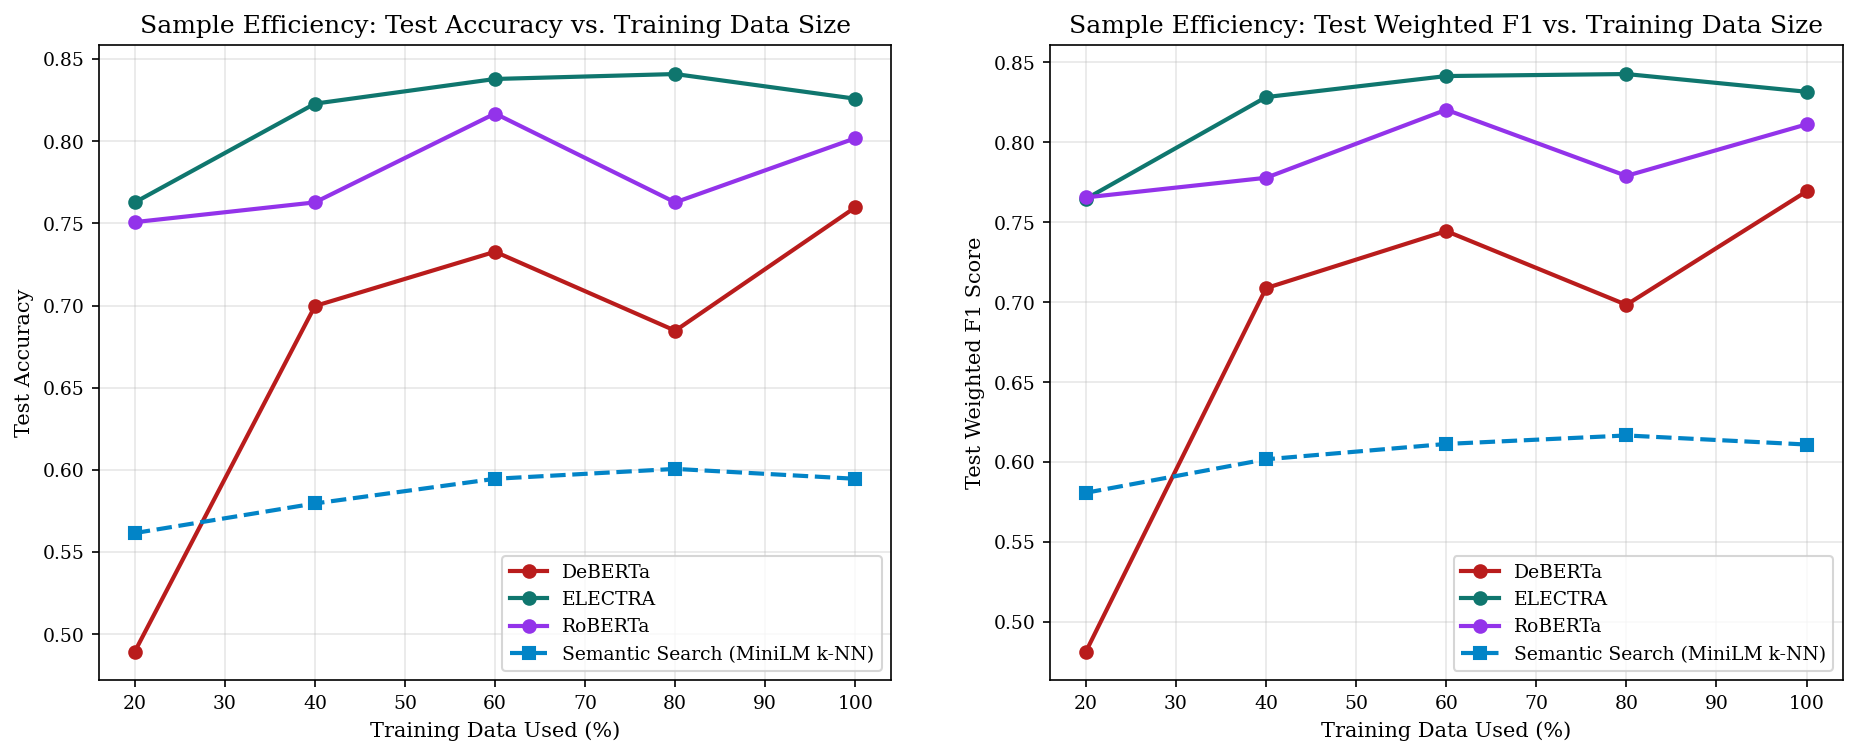

Saved: paper_figures/compute_vs_performance_pareto.png
Saved: paper_figures/compute_vs_performance_pareto.pdf


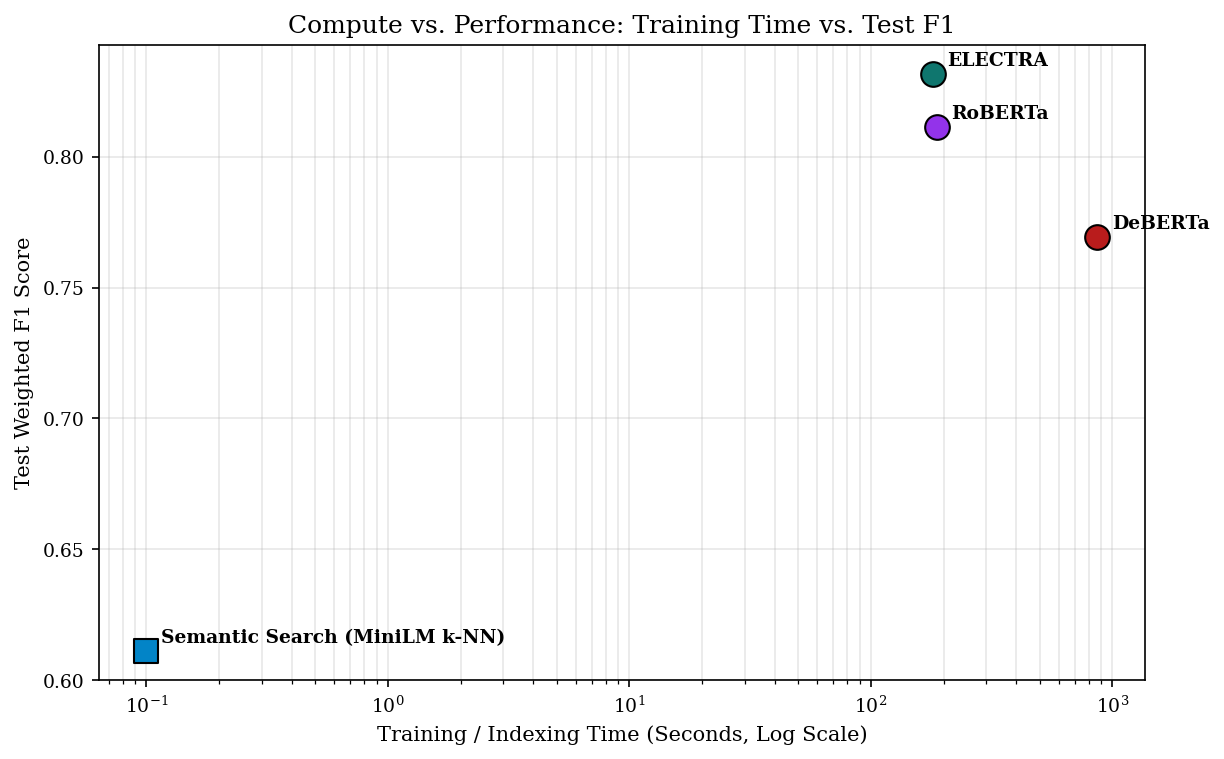

In [90]:
# Generate Publication-Ready Visualizations:
# Figure 1: Learning Curves (Data Size % vs Test Accuracy & Weighted F1)
# Figure 2: Compute / Training Time vs Performance Trade-off

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

if "SCALING_CSV_PATH" not in globals():
    SCALING_CSV_PATH = Path("/kaggle/working/model_artifacts/scaling_study/data_scaling_benchmark_results.csv" if Path("/kaggle/working").exists() else "./model_artifacts/scaling_study/data_scaling_benchmark_results.csv")

if "master_scaling_df" not in globals() or master_scaling_df is None or getattr(master_scaling_df, "empty", True):
    if SCALING_CSV_PATH.exists():
        master_scaling_df = pd.read_csv(SCALING_CSV_PATH)
    else:
        raise RuntimeError("No scaling results found. Please run the scaling sweep in Cell 158 first.")

if "FIGURE_OUTPUT_ROOT" not in globals():
    FIGURE_OUTPUT_ROOT = Path("/kaggle/working/paper_figures" if Path("/kaggle/working").exists() else "./paper_figures")
    FIGURE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if "MODEL_COLORS" not in globals():
    MODEL_COLORS = {
        "ELECTRA": "#0f766e",
        "BERT": "#1d4ed8",
        "DistilBERT": "#16a34a",
        "RoBERTa": "#9333ea",
        "XLNet": "#ea580c",
        "DeBERTa": "#b91c1c",
        "ModernBERT": "#0891b2",
        "T5": "#475569",
    }

if "save_publication_figure" not in globals():
    def save_publication_figure(fig, stem):
        png_path = FIGURE_OUTPUT_ROOT / f"{stem}.png"
        pdf_path = FIGURE_OUTPUT_ROOT / f"{stem}.pdf"
        fig.savefig(png_path, bbox_inches="tight", dpi=400)
        fig.savefig(pdf_path, bbox_inches="tight")
        print(f"Saved: {png_path}")
        print(f"Saved: {pdf_path}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Accuracy vs Data Fraction
for model_name, group in master_scaling_df.groupby("Model"):
    group_sorted = group.sort_values("Data_Fraction")
    linestyle = "--" if "Semantic" in model_name else "-"
    marker = "s" if "Semantic" in model_name else "o"
    color = "#0284c7" if "Semantic" in model_name else MODEL_COLORS.get(model_name, None)

    ax1.plot(
        group_sorted["Data_Fraction"] * 100,
        group_sorted["Test_Accuracy"],
        label=model_name,
        linestyle=linestyle,
        marker=marker,
        linewidth=2,
        color=color,
    )
    ax2.plot(
        group_sorted["Data_Fraction"] * 100,
        group_sorted["Test_Weighted_F1"],
        label=model_name,
        linestyle=linestyle,
        marker=marker,
        linewidth=2,
        color=color,
    )

ax1.set_title("Sample Efficiency: Test Accuracy vs. Training Data Size")
ax1.set_xlabel("Training Data Used (%)")
ax1.set_ylabel("Test Accuracy")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower right")

ax2.set_title("Sample Efficiency: Test Weighted F1 vs. Training Data Size")
ax2.set_xlabel("Training Data Used (%)")
ax2.set_ylabel("Test Weighted F1 Score")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower right")

save_publication_figure(fig, "data_scaling_learning_curves")
plt.show()

# Figure 2: Compute vs Performance Pareto Trade-off
fig, ax = plt.subplots(figsize=(9, 5.5))
for model_name, group in master_scaling_df.groupby("Model"):
    color = "#0284c7" if "Semantic" in model_name else MODEL_COLORS.get(model_name, None)
    marker = "s" if "Semantic" in model_name else "o"
    full_data_row = group[group["Data_Fraction"] == group["Data_Fraction"].max()]
    if not full_data_row.empty:
        r = full_data_row.iloc[0]
        ax.scatter(
            max(r["Train_Time_Seconds"], 0.1),
            r["Test_Weighted_F1"],
            s=140,
            label=f"{model_name} (100% data)",
            color=color,
            marker=marker,
            edgecolors="black",
            zorder=5,
        )
        ax.annotate(
            model_name,
            (max(r["Train_Time_Seconds"], 0.1), r["Test_Weighted_F1"]),
            textcoords="offset points",
            xytext=(7, 4),
            fontsize=9,
            weight="bold",
        )

ax.set_xscale("log")
ax.set_title("Compute vs. Performance: Training Time vs. Test F1")
ax.set_xlabel("Training / Indexing Time (Seconds, Log Scale)")
ax.set_ylabel("Test Weighted F1 Score")
ax.grid(True, which="both", alpha=0.3)
save_publication_figure(fig, "compute_vs_performance_pareto")
plt.show()
